# Independent-Group Evaluation of Pig Behavior Recognition Models

**Reproducible research notebook · DeGCN, KP-TCN, SlowFast, and ViTAM-SlowFast**

## Objective and experimental design

This notebook evaluates previously trained pig behavior recognition architectures on a manually revised **independent group**. The test data consist of **414 short RGB video clips**, each containing **15 frames**, and **3,969 eligible animal–clip instances**. An additional **1,211 instances labeled `exploring`** were excluded because that category is not one of the six target behaviors. The experiments use the same independent labels to evaluate:

- **Six-class models (6c):** walking, running, eating, drinking, lying awake, and sleeping.
- **Direct four-class models (4c):** locomotion (`deslocando`), eating, drinking, and lying (`deitado`).
- **Post-hoc six-to-four grouping (6c → 4c):** predictions and labels from a previously trained 6c model are remapped to four behaviors, **without retraining**.

**Study design:** checkpoints were chosen using their **original validation** results; the independent group is reserved for final evaluation. The DeGCN and KP-TCN systems classify keypoint/skeleton representations, while SlowFast and ViTAM-SlowFast classify temporal RGB crops. Pose extraction itself remains vision-based; RGB color and texture are not direct inputs to the downstream skeleton classifier.

## Repository use and reproducibility

1. Run cells by model section, starting with the associated configuration/import cell; do **not** assume that `Run All` is safe, because historical evaluation variants and optional file-copy steps are retained for provenance.
2. Update hard-coded Windows `F:\...` paths to your own directory tree, and obtain the relevant datasets, class-map JSON files, model source files and trained checkpoints separately.
3. Install compatible versions of `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `opencv-python`, `torch` and, for SlowFast, `pytorchvideo` and its dependencies. The notebook does not install them automatically.
4. Original cell source and saved evaluation outputs have been preserved in the documented archival version. The clean GitHub version has execution outputs removed, but does not change model calculations.
5. For scientific reporting, identify **test-set evaluation** separately from **original cross-validation**, and identify **direct 4c models** separately from **6c → 4c grouped outputs**.

> **Data availability and privacy:** Local absolute paths in the notebook are reproducibility placeholders, not downloadable assets. Do not commit unpublished annotation data, large model files, or sensitive local metadata without checking rights and permissions. The annotated repository version is not independently executed against the original Windows datasets.

## Organization

- Part I — DeGCN: six classes, historical revision, direct four classes, six-to-four grouping.
- Part II — KP-TCN: six classes, direct four classes, six-to-four grouping.
- Part III — SlowFast RGB: six classes and direct four classes.
- Part IV — ViTAM-SlowFast: model inventory, six-class evaluation, direct four-class evaluation.

---


# Avaliação DeGCN 6 classes

### Step 02 — Initial DeGCN six-class evaluation

**Purpose.** Loads manually reviewed animal tracks from the annotation JSON, constructs 15-frame / nine-keypoint sequences, runs the six-class DeGCN checkpoint and reports global and class-level metrics.

**Inputs and dependencies.** Final revised JSON, a compatible DeGCN implementation, the pretrained checkpoint and its keypoint ordering.

**Expected outputs.** Printed diagnostics and prediction/evaluation artifacts. This is an early evaluation implementation; the later revised evaluation below is the reference used for reported comparisons.

**Reproducibility and interpretation.** Check the checkpoint provenance and annotation timestamp; this section must not be used to choose a fold based on independent-test performance.



In [24]:

# ============================================================
# FINAL EVALUATION WITH AN INDEPENDENT GROUP
# DeGCN — 6 classes — T=15 — 9 keypoints
#
# Referência: anotações finais revisadas manualmente
# Entrada: keypoints presentes no JSON exportado
# Treinamento: NENHUM
# ============================================================

import sys
import json
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. CAMINHOS
# ============================================================

ANOTACOES = Path(
    r"F:\Doutorado\anotador_suinos\Anotações\anotacoes_suinos_20261103_230802"
)

VIDEOS = Path(
    r"F:\clips_3s\conjunto teste\unificado2"
)

CHECKPOINT = Path(
    r"F:\Doutorado\anotador_suinos\modelos\degcn\degcn_yolo_fold02.pth"
)

CODIGO_DEGCN = Path(
    r"F:\Doutorado\DeGCN_pytorch-main\DeGCN_pytorch-main"
)

SAIDA = Path(
    r"F:\Doutorado\anotador_suinos\avaliacao_independente\degcn_6classes"
)

SAIDA.mkdir(parents=True, exist_ok=True)

# Incluir somente clipes marcados como Revisado
SOMENTE_REVISADOS = True

# Repetições para medir latência do classificador
REPETICOES_TEMPO = 30
WARMUP = 10

CLASSES = [
    "walking",
    "running",
    "eating",
    "drinking",
    "lying awake",
    "sleeping"
]

CLASSE_PARA_ID = {
    nome: i for i, nome in enumerate(CLASSES)
}

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("AVALIAÇÃO INDEPENDENTE — DEGCN 6 CLASSES")
print("=" * 75)
print("Dispositivo:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for pasta in [ANOTACOES, VIDEOS, CODIGO_DEGCN]:
    if not pasta.is_dir():
        raise FileNotFoundError(pasta)

if not CHECKPOINT.is_file():
    raise FileNotFoundError(CHECKPOINT)

# ============================================================
# 2. CARREGAR O MODELO DEGCN
# ============================================================

sys.path.insert(0, str(CODIGO_DEGCN))

from graph.pig import Graph
from model.degcn import Model as DeGCN

graph = Graph(strategy="spatial", center=1)

pais = [-1] * 9

for filho, pai in graph.inward:
    pais[filho] = pai

PAIS_ESPERADOS = [1, -1, 1, 4, 1, 4, 1, 1, 1]

assert pais == PAIS_ESPERADOS, (
    f"Grafo incompatível: {pais}"
)

ckpt = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

for campo, esperado in [
    ("num_classes", 6),
    ("V", 9),
    ("C", 4),
    ("M", 1),
    ("center", 1),
    ("use_bone", 1),
]:
    assert int(ckpt[campo]) == esperado, (
        f"Checkpoint incompatível: {campo}"
    )

assert ckpt["graph_strategy"] == "spatial"

modelo = DeGCN(
    num_class=6,
    num_point=9,
    num_person=1,
    k=2,
    eta=int(ckpt["eta"]),
    num_stream=1,
    graph="graph.pig.Graph",
    graph_args={
        "strategy": "spatial",
        "center": 1
    },
    in_channels=4,
    drop_out=0
)

modelo.load_state_dict(
    ckpt["model"],
    strict=True
)

modelo = modelo.to(device)
modelo.eval()

n_params = sum(
    p.numel() for p in modelo.parameters()
)

print("\nModelo carregado:", CHECKPOINT.name)
print("Parâmetros:", f"{n_params:,}")
print("Grafo:", pais)

# ============================================================
# 3. CARREGAR ANOTAÇÕES EXPORTADAS
# ============================================================

CONSOLIDADO = ANOTACOES / "anotacoes_consolidadas.json"

if CONSOLIDADO.is_file():

    with open(
        CONSOLIDADO,
        "r",
        encoding="utf-8"
    ) as f:
        dados = json.load(f)

    clipes = dados.get("clipes", [])

    if not isinstance(clipes, list):
        raise ValueError(
            "Campo 'clipes' inválido no JSON consolidado."
        )

    print("\nFonte: JSON consolidado")

else:

    pasta_clipes = ANOTACOES / "por_clipe"

    arquivos = sorted(
        pasta_clipes.glob("*_anotacoes.json")
    )

    if not arquivos:
        raise FileNotFoundError(
            "Não foram encontrados JSONs exportados."
        )

    clipes = []

    for arquivo in arquivos:
        with open(
            arquivo,
            "r",
            encoding="utf-8"
        ) as f:
            clipes.append(json.load(f))

    print("\nFonte: JSONs individuais")

print("Clipes encontrados:", len(clipes))

# ============================================================
# 4. EXTRAIR JANELAS INDEPENDENTES
# ============================================================

X_lista = []
y_lista = []
metadados = []
descartes = Counter()

for clipe in clipes:

    status = str(
        clipe.get("review_status", "")
    ).strip().lower()

    if SOMENTE_REVISADOS and status != "revisado":
        descartes["clipe_nao_revisado"] += 1
        continue

    frames = clipe.get("frames", [])

    if len(frames) != 15:
        descartes["clipe_fora_T15"] += 1
        continue

    largura = float(clipe.get("width", 0))
    altura = float(clipe.get("height", 0))

    if largura <= 0 or altura <= 0:
        descartes["dimensoes_invalidas"] += 1
        continue

    video = Path(
        str(clipe.get("video", ""))
    ).name

    if not video:
        descartes["sem_video"] += 1
        continue

    if not (VIDEOS / video).is_file():
        descartes["video_nao_encontrado"] += 1
        continue

    # Identificar animais presentes em todos os frames
    mapas = []

    for frame in frames:

        animais = frame.get("animals", [])

        mapa = {
            int(a["track_id"]): a
            for a in animais
        }

        mapas.append(mapa)

    ids = set(mapas[0])

    for mapa in mapas[1:]:
        ids &= set(mapa)

    if not ids:
        descartes["clipe_sem_tracks_completos"] += 1
        continue

    for tid in sorted(ids):

        sequencia = [
            mapa[tid] for mapa in mapas
        ]

        # Rótulos finais após revisão manual
        rotulos = {
            str(a.get("behavior", "")).strip().lower()
            for a in sequencia
        }

        if len(rotulos) != 1:
            descartes["rotulo_inconsistente"] += 1
            continue

        rotulo = next(iter(rotulos))

        if rotulo not in CLASSE_PARA_ID:
            descartes[f"classe_excluida:{rotulo}"] += 1
            continue

        try:
            pontos = np.array(
                [
                    a["keypoints"]
                    for a in sequencia
                ],
                dtype=np.float32
            )
        except (KeyError, ValueError, TypeError):
            descartes["keypoints_invalidos"] += 1
            continue

        if pontos.shape != (15, 9, 2):
            descartes["formato_keypoints_invalido"] += 1
            continue

        if not np.isfinite(pontos).all():
            descartes["keypoints_nao_finitos"] += 1
            continue

        # Coordenadas normalizadas:
        # X = largura; Y = altura
        xy = pontos.copy()

        xy[:, :, 0] /= largura
        xy[:, :, 1] /= altura

        # Entrada DeGCN:
        # (C=2, T=15, V=9, M=1)
        pos = np.transpose(
            xy,
            (2, 0, 1)
        )[..., None]

        # Vetores ósseos conforme grafo original
        bone = np.zeros_like(pos)

        for j, pai in enumerate(pais):
            if pai >= 0:
                bone[:, :, j, :] = (
                    pos[:, :, j, :]
                    - pos[:, :, pai, :]
                )

        # (4,15,9,1)
        entrada = np.concatenate(
            [pos, bone],
            axis=0
        ).astype(np.float32)

        X_lista.append(entrada)
        y_lista.append(CLASSE_PARA_ID[rotulo])

        metadados.append({
            "video": video,
            "track_id": tid,
            "classe_referencia": rotulo,
            "review_status": status,
            "modelo_origem_anotacao": str(
                clipe.get("models", {}).get(
                    "classificador", ""
                )
            )
        })

if not X_lista:
    print("\nDescartes:", dict(descartes))
    raise RuntimeError(
        "Nenhuma janela válida encontrada. "
        "Confira o status das revisões, os vídeos "
        "e a estrutura dos JSONs."
    )

X = np.stack(X_lista)
y_true = np.asarray(y_lista, dtype=np.int64)

assert X.shape[1:] == (4, 15, 9, 1)

print("\n" + "=" * 75)
print("DATASET INDEPENDENTE PREPARADO")
print("=" * 75)
print("Entrada:", X.shape)
print("Rótulos:", y_true.shape)
print("Janelas válidas:", len(y_true))
print("Clipes utilizados:", len(set(
    m["video"] for m in metadados
)))

print("\nDistribuição de referência:")

for i, nome in enumerate(CLASSES):
    print(
        f"{nome:14s}: {np.sum(y_true == i)}"
    )

print("\nDescartes:")

for motivo, quantidade in sorted(descartes.items()):
    print(f"{motivo}: {quantidade}")

# ============================================================
# 5. INFERÊNCIA DEGCN — SEM TREINAMENTO
# ============================================================

X_torch = torch.from_numpy(X)

def sincronizar():
    if device.type == "cuda":
        torch.cuda.synchronize()

y_pred = np.empty(
    len(y_true),
    dtype=np.int64
)

confiancas = np.empty(
    len(y_true),
    dtype=np.float32
)

tempos_clipes = []
predicoes_por_janela = []

# Avaliação na ordem do dataset, agrupada por vídeo
grupos = {}

for i, meta in enumerate(metadados):
    grupos.setdefault(meta["video"], []).append(i)

print("\n" + "=" * 75)
print("EXECUTANDO DEGCN")
print("=" * 75)

with torch.inference_mode():

    # Aquecimento antes da medição
    exemplo = X_torch[:1].to(device)

    for _ in range(WARMUP):
        _ = modelo(exemplo)

    sincronizar()

    for numero, (video, indices) in enumerate(
        grupos.items(), start=1
    ):

        xb = X_torch[indices].to(device)

        # Predição efetiva
        sincronizar()
        inicio = time.perf_counter()

        logits = modelo(xb)

        sincronizar()
        tempo_execucao = (
            time.perf_counter() - inicio
        ) * 1000

        if isinstance(logits, (tuple, list)):
            logits = logits[0]

        assert logits.shape == (
            len(indices), 6
        ), (
            f"Saída inesperada: {logits.shape}"
        )

        probabilidades = torch.softmax(
            logits, dim=1
        ).cpu().numpy()

        previstos = probabilidades.argmax(axis=1)

        y_pred[indices] = previstos

        confiancas[indices] = probabilidades[
            np.arange(len(indices)),
            previstos
        ]

        # Benchmark: somente forward do DeGCN,
        # mesmo batch de animais do clipe
        medidas = []

        for _ in range(REPETICOES_TEMPO):

            sincronizar()
            t0 = time.perf_counter()

            _ = modelo(xb)

            sincronizar()

            medidas.append(
                (time.perf_counter() - t0) * 1000
            )

        tempo_medio = float(
            np.mean(medidas)
        )

        tempos_clipes.append({
            "video": video,
            "num_animais": len(indices),
            "tempo_forward_real_ms": tempo_execucao,
            "tempo_medio_batch_ms": tempo_medio,
            "tempo_mediano_batch_ms": float(
                np.median(medidas)
            ),
            "tempo_medio_por_animal_ms": (
                tempo_medio / len(indices)
            )
        })

        if (
            numero == 1
            or numero % 10 == 0
            or numero == len(grupos)
        ):
            print(
                f"{numero}/{len(grupos)} clipes | "
                f"{video} | "
                f"animais={len(indices)} | "
                f"tempo={tempo_medio:.3f} ms",
                flush=True
            )

# ============================================================
# 6. MÉTRICAS — MESMA ESTRUTURA DA TABELA 3
# ============================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=range(6),
        zero_division=0
    )
)

accuracy = accuracy_score(
    y_true, y_pred
)

macro_p, macro_r, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=range(6),
        average="macro",
        zero_division=0
    )
)

weighted_p, weighted_r, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=range(6),
        average="weighted",
        zero_division=0
    )
)

tabela = pd.DataFrame({
    "Classe": CLASSES,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

tabela = pd.concat(
    [
        tabela,
        pd.DataFrame([
            {
                "Classe": "Accuracy",
                "Precision": np.nan,
                "Recall": np.nan,
                "F1-Score": accuracy,
                "Support": len(y_true)
            },
            {
                "Classe": "Macro Avg",
                "Precision": macro_p,
                "Recall": macro_r,
                "F1-Score": macro_f1,
                "Support": len(y_true)
            },
            {
                "Classe": "Weighted Avg",
                "Precision": weighted_p,
                "Recall": weighted_r,
                "F1-Score": weighted_f1,
                "Support": len(y_true)
            }
        ])
    ],
    ignore_index=True
)

cm = confusion_matrix(
    y_true, y_pred, labels=range(6)
)

matriz = pd.DataFrame(
    cm,
    index=CLASSES,
    columns=CLASSES
)

# ============================================================
# 7. TEMPOS MÉDIOS DE INFERÊNCIA
# ============================================================

df_tempos = pd.DataFrame(
    tempos_clipes
)

total_animais = df_tempos["num_animais"].sum()

tempo_medio_por_animal = (
    df_tempos["tempo_medio_batch_ms"].sum()
    / total_animais
)

tempo_medio_por_clipe = (
    df_tempos["tempo_medio_batch_ms"].mean()
)

tempo_mediano_por_clipe = (
    df_tempos["tempo_medio_batch_ms"].median()
)

print("\n" + "=" * 75)
print("TABELA 3 — DEGCN — GRUPO INDEPENDENTE")
print("=" * 75)

display(tabela.round(4))

print("\nMATRIZ DE CONFUSÃO")
display(matriz)

print("\n" + "=" * 75)
print("TEMPOS DE EXECUÇÃO DO DEGCN")
print("=" * 75)

print("Total de janelas:", len(y_true))
print("Total de clipes:", len(df_tempos))

print(
    f"Tempo médio por animal: "
    f"{tempo_medio_por_animal:.4f} ms"
)

print(
    f"Tempo médio por clipe: "
    f"{tempo_medio_por_clipe:.4f} ms"
)

print(
    f"Tempo mediano por clipe: "
    f"{tempo_mediano_por_clipe:.4f} ms"
)

print(
    "\nObservação: tempos somente do forward "
    "do DeGCN, sem YOLO, leitura de vídeo, "
    "pré-processamento ou transferência CPU/GPU."
)

# ============================================================
# 8. EXPORTAR RESULTADOS
# ============================================================

df_pred = pd.DataFrame(metadados)

df_pred["y_true"] = y_true
df_pred["y_pred"] = y_pred

df_pred["classe_predita"] = [
    CLASSES[i] for i in y_pred
]

df_pred["confianca"] = confiancas

df_pred["correto"] = (
    y_true == y_pred
)

tabela.to_csv(
    SAIDA / "tabela3_degcn_6classes.csv",
    index=False,
    encoding="utf-8-sig"
)

matriz.to_csv(
    SAIDA / "matriz_confusao.csv",
    encoding="utf-8-sig"
)

df_tempos.to_csv(
    SAIDA / "tempos_por_clipe.csv",
    index=False,
    encoding="utf-8-sig"
)

df_pred.to_csv(
    SAIDA / "predicoes_individuais.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo = {
    "dataset": str(ANOTACOES),
    "checkpoint": str(CHECKPOINT),
    "num_janelas": int(len(y_true)),
    "num_clipes": int(len(df_tempos)),
    "accuracy": float(accuracy),
    "macro_precision": float(macro_p),
    "macro_recall": float(macro_r),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "tempo_medio_por_animal_ms": (
        float(tempo_medio_por_animal)
    ),
    "tempo_medio_por_clipe_ms": (
        float(tempo_medio_por_clipe)
    ),
    "descartes": dict(descartes),
    "somente_revisados": SOMENTE_REVISADOS,
    "entrada": "keypoints armazenados na exportacao",
    "timing": "somente forward do DeGCN"
}

with open(
    SAIDA / "resumo_avaliacao.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        resumo,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\n" + "=" * 75)
print("AVALIAÇÃO CONCLUÍDA")
print("=" * 75)

print("Resultados salvos em:", SAIDA)


AVALIAÇÃO INDEPENDENTE — DEGCN 6 CLASSES
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3070

Modelo carregado: degcn_yolo_fold02.pth
Parâmetros: 692,810
Grafo: [1, -1, 1, 4, 1, 4, 1, 1, 1]

Fonte: JSON consolidado
Clipes encontrados: 281

DATASET INDEPENDENTE PREPARADO
Entrada: (2786, 4, 15, 9, 1)
Rótulos: (2786,)
Janelas válidas: 2786
Clipes utilizados: 281

Distribuição de referência:
walking       : 476
running       : 13
eating        : 1089
drinking      : 190
lying awake   : 419
sleeping      : 599

Descartes:
classe_excluida:exploring: 627
classe_excluida:lying: 1

EXECUTANDO DEGCN
1/281 clipes | v12_clip_0773.mkv | animais=13 | tempo=32.598 ms
10/281 clipes | v12_clip_0900.mkv | animais=12 | tempo=33.311 ms
20/281 clipes | v12_clip_1023.mkv | animais=10 | tempo=29.527 ms
30/281 clipes | v12_clip_2991.mkv | animais=11 | tempo=32.245 ms
40/281 clipes | v12_clip_8620.mkv | animais=10 | tempo=29.254 ms
50/281 clipes | v12_clip_8645.mkv | animais=11 | tempo=29.901 ms
60/281 clipes | v12

,Classe,Precision,Recall,F1-Score,Support
0,walking,0.8691,0.9349,0.9008,476
1,running,0.5556,0.3846,0.4545,13
2,eating,0.9945,0.9982,0.9963,1089
3,drinking,0.9286,0.8895,0.9086,190
4,lying awake,0.9323,0.8544,0.8917,419
5,sleeping,0.9587,0.9699,0.9643,599
6,Accuracy,NaN,NaN,0.9494,2786
7,Macro Avg,0.8731,0.8386,0.8527,2786
8,Weighted Avg,0.9495,0.9494,0.9489,2786



MATRIZ DE CONFUSÃO


,walking,running,eating,drinking,lying awake,sleeping
walking,445,1,6,3,18,3
running,8,5,0,0,0,0
eating,1,1,1087,0,0,0
drinking,20,0,0,169,1,0
lying awake,30,1,0,8,358,22
sleeping,8,1,0,2,7,581



TEMPOS DE EXECUÇÃO DO DEGCN
Total de janelas: 2786
Total de clipes: 281
Tempo médio por animal: 3.3062 ms
Tempo médio por clipe: 32.7792 ms
Tempo mediano por clipe: 32.1234 ms

Observação: tempos somente do forward do DeGCN, sem YOLO, leitura de vídeo, pré-processamento ou transferência CPU/GPU.

AVALIAÇÃO CONCLUÍDA
Resultados salvos em: F:\Doutorado\anotador_suinos\avaliacao_independente\degcn_6classes


# Avaliação DeCGN 6 classes melhor modelo

### Step 07 — Historical DeGCN six-class re-evaluation — superseded annotation export

**Purpose.** Evaluates six-class DeGCN using an earlier consolidated annotation export dated 2026-11-07. Retained for traceability, not for the final comparison.

**Inputs and dependencies.** Original 2026-11-07 consolidated annotations and DeGCN fold2 checkpoint.

**Expected outputs.** Historical per-animal predictions, performance diagnostics and confusion matrices.

**Reproducibility and interpretation.** **Do not use these outputs as the final independent-test results.** The next cell uses the later 2026-11-10 revised annotation export. Skip this historical cell when reproducing final tables.



Dispositivo: cuda
Checkpoint: F:\Doutorado\anotador_suinos\modelos\degcn\degcn_yolo_fold02.pth

Clipes no conjunto: 414

Checkpoint DeGCN fold2 carregado.

AMOSTRAS PARA REAVALIAÇÃO
Instâncias encontradas: 5180
Instâncias avaliadas: 3986
Excluídas (exploring): 1194
Entrada: (3986, 4, 15, 9, 1)

Distribuição das classes:
walking        : 895
running        : 270
eating         : 1268
drinking       : 251
lying awake    : 676
sleeping       : 626

Executando DeGCN fold2...

RESULTADOS — DeGCN FOLD2
Accuracy:         0.9042
Macro-Precision:  0.8926
Macro-Recall:     0.8671
Macro-F1:         0.8761


,classe,precision,recall,f1,suporte
0,walking,0.7912,0.9274,0.8539,895
1,running,0.8816,0.7444,0.8072,270
2,eating,0.9875,0.9968,0.9922,1268
3,drinking,0.8268,0.8367,0.8317,251
4,lying awake,0.9236,0.7337,0.8178,676
5,sleeping,0.9451,0.9633,0.9541,626



RELATÓRIO COMPLETO:
              precision    recall  f1-score   support

     walking     0.7912    0.9274    0.8539       895
     running     0.8816    0.7444    0.8072       270
      eating     0.9875    0.9968    0.9922      1268
    drinking     0.8268    0.8367    0.8317       251
 lying awake     0.9236    0.7337    0.8178       676
    sleeping     0.9451    0.9633    0.9541       626

    accuracy                         0.9042      3986
   macro avg     0.8926    0.8671    0.8761      3986
weighted avg     0.9087    0.9042    0.9029      3986



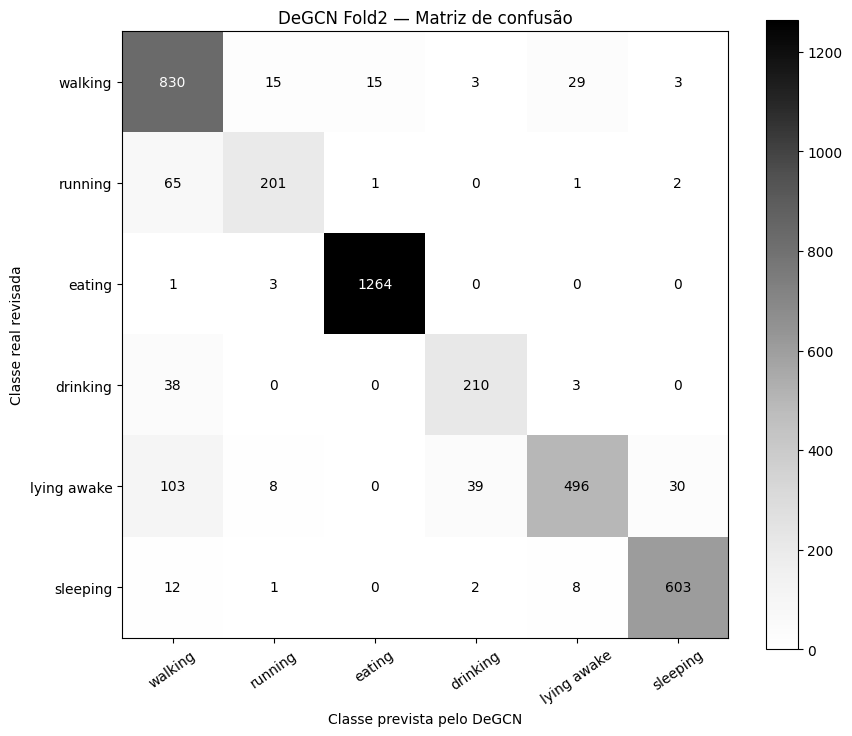

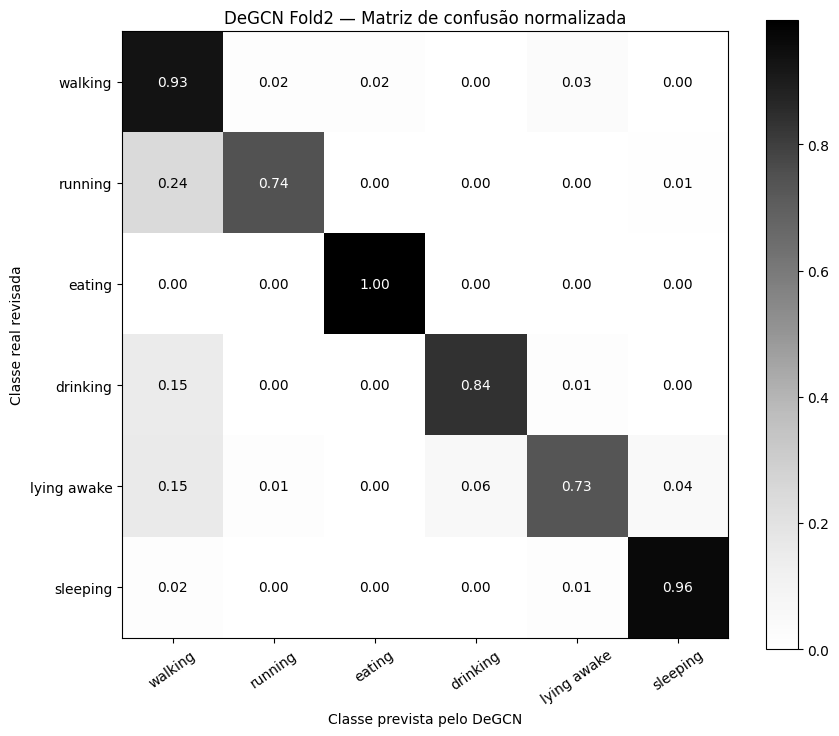


AVALIAÇÃO CONCLUÍDA
Amostras avaliadas: 3986
Macro-F1: 0.8761
Accuracy: 0.9042

Resultados salvos em:
F:\Doutorado\anotador_suinos\Anotações\consolidadas unificado3\anotacoes_suinos_20261107_154403\reavaliacao_DeGCN_fold2


In [18]:

# ================================================================
# REAVALIAÇÃO DeGCN FOLD2 — UNIFICADOS3
# 414 clipes revisados | 6 classes | T=15 | 9 keypoints
# Ground truth: comportamento final revisado
# ================================================================

from pathlib import Path
from collections import Counter
from datetime import datetime
import sys
import json

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ================================================================
# 1. CAMINHOS
# ================================================================

BASE = Path(r"F:\Doutorado\anotador_suinos")

JSON_ANOTACOES = (
    BASE / "Anotações" /
    "consolidadas unificado3" /
    "anotacoes_suinos_20261107_154403" /
    "anotacoes_consolidadas.json"
)

CHECKPOINT = (
    BASE / "modelos" / "degcn" /
    "degcn_yolo_fold02.pth"
)

CODIGO_DEGCN = Path(
    r"F:\Doutorado\DeGCN_pytorch-main\DeGCN_pytorch-main"
)

SAIDA = (
    JSON_ANOTACOES.parent /
    "reavaliacao_DeGCN_fold2"
)

CLASSES = [
    "walking",
    "running",
    "eating",
    "drinking",
    "lying awake",
    "sleeping"
]

T = 15
V = 9
BATCH_SIZE = 64
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

for arquivo in [
    JSON_ANOTACOES,
    CHECKPOINT,
    CODIGO_DEGCN / "graph" / "pig.py",
    CODIGO_DEGCN / "model" / "degcn.py"
]:
    if not arquivo.is_file():
        raise FileNotFoundError(arquivo)

print("Dispositivo:", DEVICE)
print("Checkpoint:", CHECKPOINT)

# ================================================================
# 2. LER ANOTAÇÕES REVISADAS
# ================================================================

with JSON_ANOTACOES.open(
    "r", encoding="utf-8-sig"
) as f:
    dados = json.load(f)

clipes = dados["clipes"]

print("\nClipes no conjunto:", len(clipes))

if len(clipes) != 414:
    raise ValueError(
        f"Esperados 414 clipes; encontrados {len(clipes)}"
    )

# ================================================================
# 3. CARREGAR GRAFO E CHECKPOINT ORIGINAL
# ================================================================

sys.path.insert(0, str(CODIGO_DEGCN))

from graph.pig import Graph
from model.degcn import Model as DeGCN

graph = Graph(strategy="spatial", center=1)

pais = [-1] * V

for filho, pai in graph.inward:
    pais[filho] = pai

ESPERADO_PAIS = [1, -1, 1, 4, 1, 4, 1, 1, 1]

if pais != ESPERADO_PAIS:
    raise ValueError(
        f"Grafo incompatível: {pais}"
    )

ckpt = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

for campo, valor in [
    ("num_classes", 6),
    ("V", 9),
    ("C", 4),
    ("M", 1),
    ("center", 1),
    ("use_bone", 1)
]:
    if int(ckpt[campo]) != valor:
        raise ValueError(
            f"Checkpoint incompatível: {campo}"
        )

if ckpt["graph_strategy"] != "spatial":
    raise ValueError("Estratégia do grafo incompatível")

modelo = DeGCN(
    num_class=6,
    num_point=9,
    num_person=1,
    k=2,
    eta=int(ckpt["eta"]),
    num_stream=1,
    graph="graph.pig.Graph",
    graph_args={
        "strategy": "spatial",
        "center": 1
    },
    in_channels=4,
    drop_out=0
)

modelo.load_state_dict(
    ckpt["model"],
    strict=True
)

modelo.to(DEVICE).eval()

print("\nCheckpoint DeGCN fold2 carregado.")

# ================================================================
# 4. CONSTRUIR AMOSTRAS A PARTIR DOS KEYPOINTS
# ================================================================

entradas = []
verdadeiros = []
metadados = []

excluidos = Counter()
rotulos_invalidos = []
amostras_lidas = 0

for clipe in clipes:

    video = Path(str(clipe["video"])).name
    frames = clipe.get("frames", [])

    if len(frames) != T:
        raise ValueError(
            f"{video}: esperado 15 frames"
        )

    largura = float(clipe["width"])
    altura = float(clipe["height"])

    if largura <= 0 or altura <= 0:
        raise ValueError(
            f"{video}: dimensões inválidas"
        )

    # Verificar IDs do primeiro frame
    ids = [
        int(a["track_id"])
        for a in frames[0]["animals"]
    ]

    if len(ids) != len(set(ids)):
        raise ValueError(
            f"{video}: IDs repetidos no primeiro frame"
        )

    for tid in ids:

        amostras_lidas += 1

        pontos = np.zeros(
            (T, V, 2), dtype=np.float32
        )

        rotulos = []
        rotulos_auto = []

        for t, frame in enumerate(frames):

            encontrados = [
                a for a in frame["animals"]
                if int(a["track_id"]) == tid
            ]

            if len(encontrados) != 1:
                raise ValueError(
                    f"{video}, ID {tid}, frame {t}: "
                    "animal ausente ou duplicado"
                )

            animal = encontrados[0]

            pts = np.asarray(
                animal["keypoints"],
                dtype=np.float32
            )

            if pts.shape != (V, 2):
                raise ValueError(
                    f"{video}, ID {tid}: "
                    f"keypoints com shape {pts.shape}"
                )

            pontos[t] = pts

            # Rótulo final corrigido manualmente
            rotulos.append(
                animal.get("behavior")
            )

            rotulos_auto.append(
                animal.get(
                    "behavior_auto",
                    animal.get("behavior")
                )
            )

        # Não permitir mudança de classe dentro da janela
        if len(set(rotulos)) != 1:
            raise ValueError(
                f"{video}, ID {tid}: "
                f"rótulos diferentes nos 15 frames: "
                f"{set(rotulos)}"
            )

        classe_real = rotulos[0]

        if classe_real == "lying":
            classe_real = "lying awake"

        if classe_real == "exploring":
            excluidos["exploring"] += 1
            continue

        if classe_real not in CLASSES:
            rotulos_invalidos.append(
                (video, tid, classe_real)
            )
            continue

        if not np.isfinite(pontos).all():
            raise ValueError(
                f"{video}, ID {tid}: coordenadas não finitas"
            )

        # ----------------------------------------
        # Posição normalizada: (2, 15, 9, 1)
        # ----------------------------------------

        pos = np.zeros(
            (2, T, V, 1), dtype=np.float32
        )

        pos[0, :, :, 0] = (
            pontos[:, :, 0] / largura
        )
        pos[1, :, :, 0] = (
            pontos[:, :, 1] / altura
        )

        # ----------------------------------------
        # Vetores ósseos: mesmo grafo do treinamento
        # ----------------------------------------

        bone = np.zeros_like(pos)

        for j, pai in enumerate(pais):
            if pai >= 0:
                bone[:, :, j, :] = (
                    pos[:, :, j, :] -
                    pos[:, :, pai, :]
                )

        # Entrada DeGCN: (4, 15, 9, 1)
        X = np.concatenate(
            [pos, bone],
            axis=0
        )

        entradas.append(X)
        verdadeiros.append(
            CLASSES.index(classe_real)
        )

        metadados.append({
            "arquivo": video,
            "track_id": tid,
            "classe_real": classe_real,
            "classe_automatica_exportada": (
                rotulos_auto[0]
            ),
            "status_clipe": clipe.get(
                "review_status", ""
            )
        })

if rotulos_invalidos:
    print("\nRÓTULOS INCOMPATÍVEIS:")
    for item in rotulos_invalidos[:30]:
        print(item)

    raise ValueError(
        "Existem classes incompatíveis com o DeGCN 6c."
    )

if not entradas:
    raise RuntimeError(
        "Nenhuma amostra válida para avaliação"
    )

X = np.stack(
    entradas,
    axis=0
).astype(np.float32)

y_true = np.asarray(
    verdadeiros,
    dtype=np.int64
)

print("\n" + "=" * 65)
print("AMOSTRAS PARA REAVALIAÇÃO")
print("=" * 65)

print("Instâncias encontradas:", amostras_lidas)
print("Instâncias avaliadas:", len(y_true))
print("Excluídas (exploring):", excluidos["exploring"])
print("Entrada:", X.shape)

print("\nDistribuição das classes:")
for i, classe in enumerate(CLASSES):
    print(
        f"{classe:15}: "
        f"{np.sum(y_true == i)}"
    )

# ================================================================
# 5. EXECUTAR INFERÊNCIA DO FOLD2
# ================================================================

predicoes = []
probabilidades = []

print("\nExecutando DeGCN fold2...")

with torch.inference_mode():

    for inicio in range(
        0, len(X), BATCH_SIZE
    ):

        fim = min(
            inicio + BATCH_SIZE,
            len(X)
        )

        batch = torch.from_numpy(
            X[inicio:fim]
        ).to(DEVICE)

        logits = modelo(batch)

        if isinstance(logits, (tuple, list)):
            if len(logits) != 1:
                raise ValueError(
                    "DeGCN retornou múltiplas saídas"
                )
            logits = logits[0]

        if logits.ndim != 2 or logits.shape[1] != 6:
            raise ValueError(
                f"Logits incompatíveis: {logits.shape}"
            )

        probs = torch.softmax(
            logits,
            dim=1
        ).cpu().numpy()

        probabilidades.append(probs)

        predicoes.extend(
            probs.argmax(axis=1).tolist()
        )

probs = np.concatenate(
    probabilidades,
    axis=0
)

y_pred = np.asarray(
    predicoes,
    dtype=np.int64
)

assert len(y_true) == len(y_pred)

# ================================================================
# 6. MÉTRICAS
# ================================================================

acc = accuracy_score(y_true, y_pred)

precision, recall, f1, suporte = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(6),
        zero_division=0
    )
)

macro_f1 = float(np.mean(f1))
macro_p = float(np.mean(precision))
macro_r = float(np.mean(recall))

print("\n" + "=" * 65)
print("RESULTADOS — DeGCN FOLD2")
print("=" * 65)

print(f"Accuracy:         {acc:.4f}")
print(f"Macro-Precision:  {macro_p:.4f}")
print(f"Macro-Recall:     {macro_r:.4f}")
print(f"Macro-F1:         {macro_f1:.4f}")

relatorio = pd.DataFrame({
    "classe": CLASSES,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "suporte": suporte
})

display(relatorio.round(4))

print("\nRELATÓRIO COMPLETO:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(6),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

# ================================================================
# 7. MATRIZES DE CONFUSÃO
# ================================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(6)
)

cm_norm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(6),
    normalize="true"
)

def desenhar_matriz(matriz, titulo, formato, caminho):
    fig, ax = plt.subplots(figsize=(9, 7.5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASSES
    )

    disp.plot(
        ax=ax,
        cmap="Greys",
        values_format=formato,
        colorbar=True,
        xticks_rotation=35
    )

    ax.set_title(titulo)
    ax.set_xlabel("Classe prevista pelo DeGCN")
    ax.set_ylabel("Classe real revisada")

    fig.tight_layout()

    fig.savefig(
        caminho,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ================================================================
# 8. SALVAR RESULTADOS
# ================================================================

SAIDA.mkdir(
    parents=True,
    exist_ok=True
)

desenhar_matriz(
    cm,
    "DeGCN Fold2 — Matriz de confusão",
    "d",
    SAIDA / "matriz_confusao_absoluta.png"
)

desenhar_matriz(
    cm_norm,
    "DeGCN Fold2 — Matriz de confusão normalizada",
    ".2f",
    SAIDA / "matriz_confusao_normalizada.png"
)

pd.DataFrame(
    cm,
    index=CLASSES,
    columns=CLASSES
).to_csv(
    SAIDA / "matriz_confusao.csv",
    encoding="utf-8-sig"
)

relatorio.to_csv(
    SAIDA / "metricas_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

resultado_individual = pd.DataFrame(
    metadados
)

resultado_individual["classe_prevista"] = [
    CLASSES[i] for i in y_pred
]

resultado_individual["correto"] = (
    y_true == y_pred
)

resultado_individual["confianca_fold2"] = (
    probs.max(axis=1)
)

for j, classe in enumerate(CLASSES):
    resultado_individual[
        f"prob_{classe.replace(' ', '_')}"
    ] = probs[:, j]

resultado_individual.to_csv(
    SAIDA / "predicoes_por_animal.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo = pd.DataFrame([{
    "checkpoint": str(CHECKPOINT),
    "total_clipes": len(clipes),
    "instancias_encontradas": amostras_lidas,
    "instancias_avaliadas": len(y_true),
    "excluidas_exploring": excluidos["exploring"],
    "accuracy": acc,
    "macro_precision": macro_p,
    "macro_recall": macro_r,
    "macro_f1": macro_f1
}])

resumo.to_csv(
    SAIDA / "metricas_globais.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 65)
print("AVALIAÇÃO CONCLUÍDA")
print("=" * 65)

print("Amostras avaliadas:", len(y_true))
print("Macro-F1:", round(macro_f1, 4))
print("Accuracy:", round(acc, 4))

print("\nResultados salvos em:")
print(SAIDA)


### Step 08 — Final DeGCN six-class re-evaluation — revised annotations

**Purpose.** Repeats DeGCN inference with the final manually reviewed JSON dated 2026-11-10, producing the six-class metrics used in the comparison.

**Inputs and dependencies.** Revised annotation JSON, YOLO-derived keypoints and the preselected DeGCN fold2 checkpoint.

**Expected outputs.** Final six-class prediction CSVs, per-class metrics, summary statistics and grayscale confusion matrices.

**Reproducibility and interpretation.** Selection is based on original validation only; the independent labels must not be reused for fitting or checkpoint selection.



Dispositivo: cuda
Checkpoint: F:\Doutorado\anotador_suinos\modelos\degcn\degcn_yolo_fold02.pth

Clipes no conjunto: 414

Checkpoint DeGCN fold2 carregado.

AMOSTRAS PARA REAVALIAÇÃO
Instâncias encontradas: 5180
Instâncias avaliadas: 3969
Excluídas (exploring): 1211
Entrada: (3969, 4, 15, 9, 1)

Distribuição das classes:
walking        : 885
running        : 270
eating         : 1268
drinking       : 252
lying awake    : 640
sleeping       : 654

Executando DeGCN fold2...

RESULTADOS — DeGCN FOLD2
Accuracy:         0.8917
Macro-Precision:  0.8777
Macro-Recall:     0.8521
Macro-F1:         0.8620


,classe,precision,recall,f1,suporte
0,walking,0.7907,0.9266,0.8533,885
1,running,0.8816,0.7444,0.8072,270
2,eating,0.9875,0.9968,0.9922,1268
3,drinking,0.8300,0.8333,0.8317,252
4,lying awake,0.8518,0.7094,0.7741,640
5,sleeping,0.9248,0.9021,0.9133,654



RELATÓRIO COMPLETO:
              precision    recall  f1-score   support

     walking     0.7907    0.9266    0.8533       885
     running     0.8816    0.7444    0.8072       270
      eating     0.9875    0.9968    0.9922      1268
    drinking     0.8300    0.8333    0.8317       252
 lying awake     0.8518    0.7094    0.7741       640
    sleeping     0.9248    0.9021    0.9133       654

    accuracy                         0.8917      3969
   macro avg     0.8777    0.8521    0.8620      3969
weighted avg     0.8942    0.8917    0.8903      3969



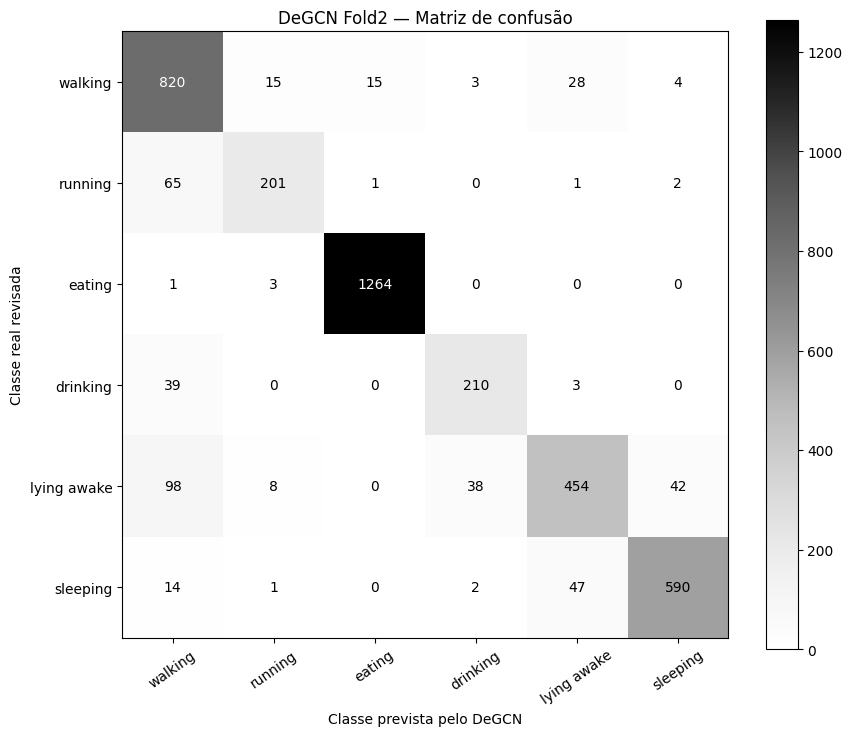

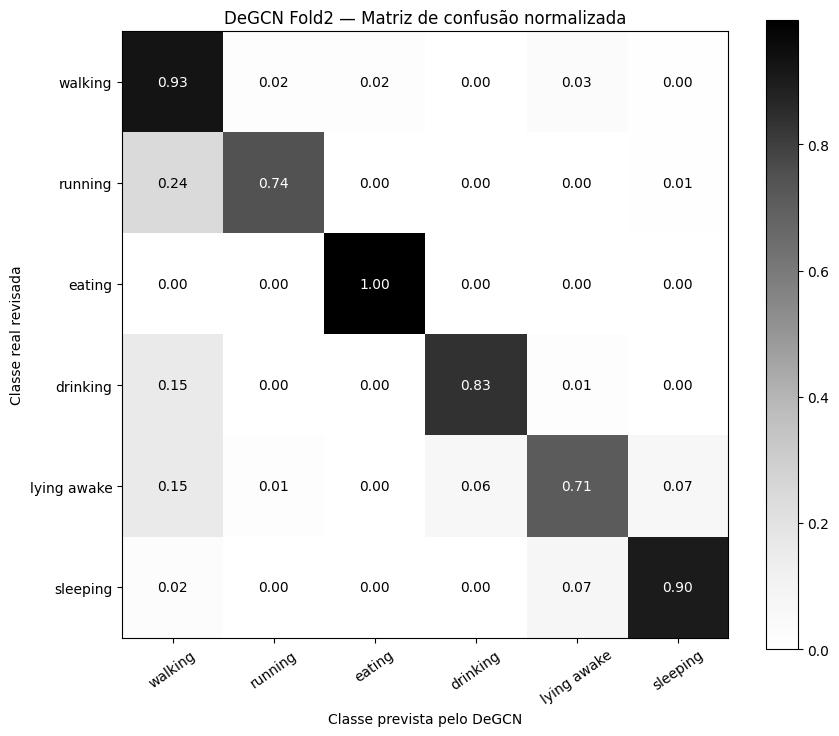


AVALIAÇÃO CONCLUÍDA
Amostras avaliadas: 3969
Macro-F1: 0.862
Accuracy: 0.8917

Resultados salvos em:
F:\Doutorado\anotador_suinos\Anotações\consolidadas unificado3\anotacoes_suinos_20261110_211312\reavaliacao_DeGCN_fold2


In [27]:

# ================================================================
# REAVALIAÇÃO DeGCN FOLD2 — UNIFICADOS3
# 414 clipes revisados | 6 classes | T=15 | 9 keypoints
# Ground truth: comportamento final revisado
# ================================================================

from pathlib import Path
from collections import Counter
from datetime import datetime
import sys
import json

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ================================================================
# 1. CAMINHOS
# ================================================================

BASE = Path(r"F:\Doutorado\anotador_suinos")

JSON_ANOTACOES = (
    BASE / "Anotações" /
    "consolidadas unificado3" /
    "anotacoes_suinos_20261110_211312" /
    "anotacoes_consolidadas.json"
)

CHECKPOINT = (
    BASE / "modelos" / "degcn" /
    "degcn_yolo_fold02.pth"
)

CODIGO_DEGCN = Path(
    r"F:\Doutorado\DeGCN_pytorch-main\DeGCN_pytorch-main"
)

SAIDA = (
    JSON_ANOTACOES.parent /
    "reavaliacao_DeGCN_fold2"
)

CLASSES = [
    "walking",
    "running",
    "eating",
    "drinking",
    "lying awake",
    "sleeping"
]

T = 15
V = 9
BATCH_SIZE = 64
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

for arquivo in [
    JSON_ANOTACOES,
    CHECKPOINT,
    CODIGO_DEGCN / "graph" / "pig.py",
    CODIGO_DEGCN / "model" / "degcn.py"
]:
    if not arquivo.is_file():
        raise FileNotFoundError(arquivo)

print("Dispositivo:", DEVICE)
print("Checkpoint:", CHECKPOINT)

# ================================================================
# 2. LER ANOTAÇÕES REVISADAS
# ================================================================

with JSON_ANOTACOES.open(
    "r", encoding="utf-8-sig"
) as f:
    dados = json.load(f)

clipes = dados["clipes"]

print("\nClipes no conjunto:", len(clipes))

if len(clipes) != 414:
    raise ValueError(
        f"Esperados 414 clipes; encontrados {len(clipes)}"
    )

# ================================================================
# 3. CARREGAR GRAFO E CHECKPOINT ORIGINAL
# ================================================================

sys.path.insert(0, str(CODIGO_DEGCN))

from graph.pig import Graph
from model.degcn import Model as DeGCN

graph = Graph(strategy="spatial", center=1)

pais = [-1] * V

for filho, pai in graph.inward:
    pais[filho] = pai

ESPERADO_PAIS = [1, -1, 1, 4, 1, 4, 1, 1, 1]

if pais != ESPERADO_PAIS:
    raise ValueError(
        f"Grafo incompatível: {pais}"
    )

ckpt = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

for campo, valor in [
    ("num_classes", 6),
    ("V", 9),
    ("C", 4),
    ("M", 1),
    ("center", 1),
    ("use_bone", 1)
]:
    if int(ckpt[campo]) != valor:
        raise ValueError(
            f"Checkpoint incompatível: {campo}"
        )

if ckpt["graph_strategy"] != "spatial":
    raise ValueError("Estratégia do grafo incompatível")

modelo = DeGCN(
    num_class=6,
    num_point=9,
    num_person=1,
    k=2,
    eta=int(ckpt["eta"]),
    num_stream=1,
    graph="graph.pig.Graph",
    graph_args={
        "strategy": "spatial",
        "center": 1
    },
    in_channels=4,
    drop_out=0
)

modelo.load_state_dict(
    ckpt["model"],
    strict=True
)

modelo.to(DEVICE).eval()

print("\nCheckpoint DeGCN fold2 carregado.")

# ================================================================
# 4. CONSTRUIR AMOSTRAS A PARTIR DOS KEYPOINTS
# ================================================================

entradas = []
verdadeiros = []
metadados = []

excluidos = Counter()
rotulos_invalidos = []
amostras_lidas = 0

for clipe in clipes:

    video = Path(str(clipe["video"])).name
    frames = clipe.get("frames", [])

    if len(frames) != T:
        raise ValueError(
            f"{video}: esperado 15 frames"
        )

    largura = float(clipe["width"])
    altura = float(clipe["height"])

    if largura <= 0 or altura <= 0:
        raise ValueError(
            f"{video}: dimensões inválidas"
        )

    # Verificar IDs do primeiro frame
    ids = [
        int(a["track_id"])
        for a in frames[0]["animals"]
    ]

    if len(ids) != len(set(ids)):
        raise ValueError(
            f"{video}: IDs repetidos no primeiro frame"
        )

    for tid in ids:

        amostras_lidas += 1

        pontos = np.zeros(
            (T, V, 2), dtype=np.float32
        )

        rotulos = []
        rotulos_auto = []

        for t, frame in enumerate(frames):

            encontrados = [
                a for a in frame["animals"]
                if int(a["track_id"]) == tid
            ]

            if len(encontrados) != 1:
                raise ValueError(
                    f"{video}, ID {tid}, frame {t}: "
                    "animal ausente ou duplicado"
                )

            animal = encontrados[0]

            pts = np.asarray(
                animal["keypoints"],
                dtype=np.float32
            )

            if pts.shape != (V, 2):
                raise ValueError(
                    f"{video}, ID {tid}: "
                    f"keypoints com shape {pts.shape}"
                )

            pontos[t] = pts

            # Rótulo final corrigido manualmente
            rotulos.append(
                animal.get("behavior")
            )

            rotulos_auto.append(
                animal.get(
                    "behavior_auto",
                    animal.get("behavior")
                )
            )

        # Não permitir mudança de classe dentro da janela
        if len(set(rotulos)) != 1:
            raise ValueError(
                f"{video}, ID {tid}: "
                f"rótulos diferentes nos 15 frames: "
                f"{set(rotulos)}"
            )

        classe_real = rotulos[0]

        if classe_real == "lying":
            classe_real = "lying awake"

        if classe_real == "exploring":
            excluidos["exploring"] += 1
            continue

        if classe_real not in CLASSES:
            rotulos_invalidos.append(
                (video, tid, classe_real)
            )
            continue

        if not np.isfinite(pontos).all():
            raise ValueError(
                f"{video}, ID {tid}: coordenadas não finitas"
            )

        # ----------------------------------------
        # Posição normalizada: (2, 15, 9, 1)
        # ----------------------------------------

        pos = np.zeros(
            (2, T, V, 1), dtype=np.float32
        )

        pos[0, :, :, 0] = (
            pontos[:, :, 0] / largura
        )
        pos[1, :, :, 0] = (
            pontos[:, :, 1] / altura
        )

        # ----------------------------------------
        # Vetores ósseos: mesmo grafo do treinamento
        # ----------------------------------------

        bone = np.zeros_like(pos)

        for j, pai in enumerate(pais):
            if pai >= 0:
                bone[:, :, j, :] = (
                    pos[:, :, j, :] -
                    pos[:, :, pai, :]
                )

        # Entrada DeGCN: (4, 15, 9, 1)
        X = np.concatenate(
            [pos, bone],
            axis=0
        )

        entradas.append(X)
        verdadeiros.append(
            CLASSES.index(classe_real)
        )

        metadados.append({
            "arquivo": video,
            "track_id": tid,
            "classe_real": classe_real,
            "classe_automatica_exportada": (
                rotulos_auto[0]
            ),
            "status_clipe": clipe.get(
                "review_status", ""
            )
        })

if rotulos_invalidos:
    print("\nRÓTULOS INCOMPATÍVEIS:")
    for item in rotulos_invalidos[:30]:
        print(item)

    raise ValueError(
        "Existem classes incompatíveis com o DeGCN 6c."
    )

if not entradas:
    raise RuntimeError(
        "Nenhuma amostra válida para avaliação"
    )

X = np.stack(
    entradas,
    axis=0
).astype(np.float32)

y_true = np.asarray(
    verdadeiros,
    dtype=np.int64
)

print("\n" + "=" * 65)
print("AMOSTRAS PARA REAVALIAÇÃO")
print("=" * 65)

print("Instâncias encontradas:", amostras_lidas)
print("Instâncias avaliadas:", len(y_true))
print("Excluídas (exploring):", excluidos["exploring"])
print("Entrada:", X.shape)

print("\nDistribuição das classes:")
for i, classe in enumerate(CLASSES):
    print(
        f"{classe:15}: "
        f"{np.sum(y_true == i)}"
    )

# ================================================================
# 5. EXECUTAR INFERÊNCIA DO FOLD2
# ================================================================

predicoes = []
probabilidades = []

print("\nExecutando DeGCN fold2...")

with torch.inference_mode():

    for inicio in range(
        0, len(X), BATCH_SIZE
    ):

        fim = min(
            inicio + BATCH_SIZE,
            len(X)
        )

        batch = torch.from_numpy(
            X[inicio:fim]
        ).to(DEVICE)

        logits = modelo(batch)

        if isinstance(logits, (tuple, list)):
            if len(logits) != 1:
                raise ValueError(
                    "DeGCN retornou múltiplas saídas"
                )
            logits = logits[0]

        if logits.ndim != 2 or logits.shape[1] != 6:
            raise ValueError(
                f"Logits incompatíveis: {logits.shape}"
            )

        probs = torch.softmax(
            logits,
            dim=1
        ).cpu().numpy()

        probabilidades.append(probs)

        predicoes.extend(
            probs.argmax(axis=1).tolist()
        )

probs = np.concatenate(
    probabilidades,
    axis=0
)

y_pred = np.asarray(
    predicoes,
    dtype=np.int64
)

assert len(y_true) == len(y_pred)

# ================================================================
# 6. MÉTRICAS
# ================================================================

acc = accuracy_score(y_true, y_pred)

precision, recall, f1, suporte = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(6),
        zero_division=0
    )
)

macro_f1 = float(np.mean(f1))
macro_p = float(np.mean(precision))
macro_r = float(np.mean(recall))

print("\n" + "=" * 65)
print("RESULTADOS — DeGCN FOLD2")
print("=" * 65)

print(f"Accuracy:         {acc:.4f}")
print(f"Macro-Precision:  {macro_p:.4f}")
print(f"Macro-Recall:     {macro_r:.4f}")
print(f"Macro-F1:         {macro_f1:.4f}")

relatorio = pd.DataFrame({
    "classe": CLASSES,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "suporte": suporte
})

display(relatorio.round(4))

print("\nRELATÓRIO COMPLETO:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(6),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

# ================================================================
# 7. MATRIZES DE CONFUSÃO
# ================================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(6)
)

cm_norm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(6),
    normalize="true"
)

def desenhar_matriz(matriz, titulo, formato, caminho):
    fig, ax = plt.subplots(figsize=(9, 7.5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASSES
    )

    disp.plot(
        ax=ax,
        cmap="Greys",
        values_format=formato,
        colorbar=True,
        xticks_rotation=35
    )

    ax.set_title(titulo)
    ax.set_xlabel("Classe prevista pelo DeGCN")
    ax.set_ylabel("Classe real revisada")

    fig.tight_layout()

    fig.savefig(
        caminho,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ================================================================
# 8. SALVAR RESULTADOS
# ================================================================

SAIDA.mkdir(
    parents=True,
    exist_ok=True
)

desenhar_matriz(
    cm,
    "DeGCN Fold2 — Matriz de confusão",
    "d",
    SAIDA / "matriz_confusao_absoluta.png"
)

desenhar_matriz(
    cm_norm,
    "DeGCN Fold2 — Matriz de confusão normalizada",
    ".2f",
    SAIDA / "matriz_confusao_normalizada.png"
)

pd.DataFrame(
    cm,
    index=CLASSES,
    columns=CLASSES
).to_csv(
    SAIDA / "matriz_confusao.csv",
    encoding="utf-8-sig"
)

relatorio.to_csv(
    SAIDA / "metricas_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

resultado_individual = pd.DataFrame(
    metadados
)

resultado_individual["classe_prevista"] = [
    CLASSES[i] for i in y_pred
]

resultado_individual["correto"] = (
    y_true == y_pred
)

resultado_individual["confianca_fold2"] = (
    probs.max(axis=1)
)

for j, classe in enumerate(CLASSES):
    resultado_individual[
        f"prob_{classe.replace(' ', '_')}"
    ] = probs[:, j]

resultado_individual.to_csv(
    SAIDA / "predicoes_por_animal.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo = pd.DataFrame([{
    "checkpoint": str(CHECKPOINT),
    "total_clipes": len(clipes),
    "instancias_encontradas": amostras_lidas,
    "instancias_avaliadas": len(y_true),
    "excluidas_exploring": excluidos["exploring"],
    "accuracy": acc,
    "macro_precision": macro_p,
    "macro_recall": macro_r,
    "macro_f1": macro_f1
}])

resumo.to_csv(
    SAIDA / "metricas_globais.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 65)
print("AVALIAÇÃO CONCLUÍDA")
print("=" * 65)

print("Amostras avaliadas:", len(y_true))
print("Macro-F1:", round(macro_f1, 4))
print("Accuracy:", round(acc, 4))

print("\nResultados salvos em:")
print(SAIDA)



# Avaliação DeCGN 4 classes melhor modelo

### Step 12 — DeGCN trained directly for four classes

**Purpose.** Runs the independently selected four-class DeGCN checkpoint on the same revised animal–clip instances, using four-class ground-truth labels.

**Inputs and dependencies.** Final annotation JSON, DeGCN 4c checkpoint, original class-map JSON and model source files.

**Expected outputs.** Four-class accuracy, macro precision/recall/F1, predictions and confusion matrices.

**Reproducibility and interpretation.** A directly trained four-class classifier is distinct from aggregating predictions of a six-class model.



Classes do treinamento (ordem e índice): {0: 'deslocando', 1: 'eating', 2: 'drinking', 3: 'deitado'}
Classes usadas nos relatórios: ['locomotion', 'eating', 'drinking', 'lying']
Checkpoint: F:\Doutorado\anotador_suinos\modelos\melhores_modelos\DeGCN_4classes\degcn_fold2.pth
Dispositivo: cuda
Clipes: 414 | Instâncias: 3969 | Exploring excluídos: 1211
Entrada DeGCN: (3969, 4, 15, 9, 1)
Distribuição: {'locomotion': 1155, 'eating': 1268, 'drinking': 252, 'lying': 1294}

DeGCN YOLO 4 CLASSES — FOLD02 (TESTE REVISADO)
Accuracy: 0.8833
Macro-Precision: 0.8396
Macro-Recall: 0.8530
Macro-F1: 0.8447
              precision    recall  f1-score   support

  locomotion     0.8889    0.7965    0.8402      1155
      eating     0.9684    0.9669    0.9676      1268
    drinking     0.6516    0.7421    0.6939       252
       lying     0.8494    0.9065    0.8770      1294

    accuracy                         0.8833      3969
   macro avg     0.8396    0.8530    0.8447      3969
weighted avg     0.8863

,classe,precision,recall,f1,suporte
0,locomotion,0.8889,0.7965,0.8402,1155
1,eating,0.9684,0.9669,0.9676,1268
2,drinking,0.6516,0.7421,0.6939,252
3,lying,0.8494,0.9065,0.8770,1294


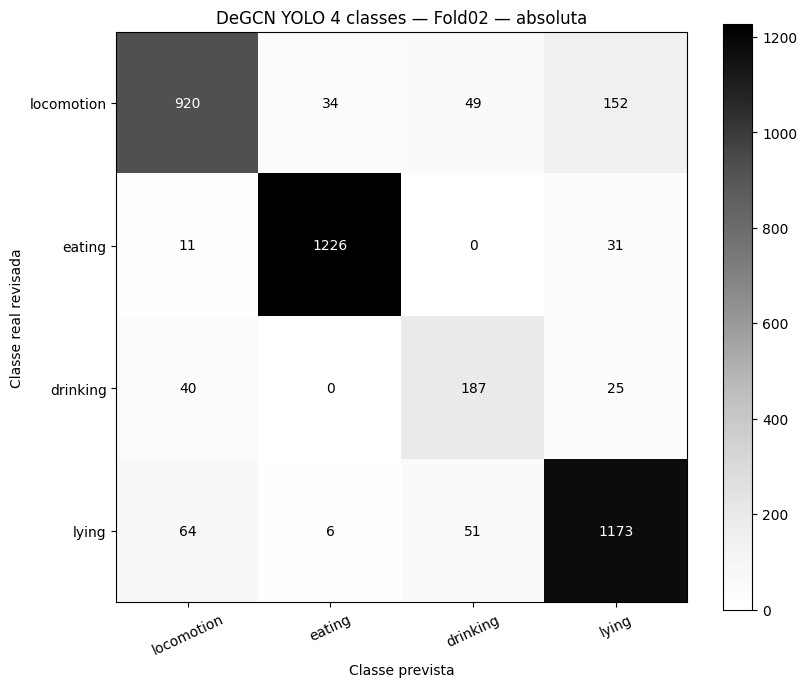

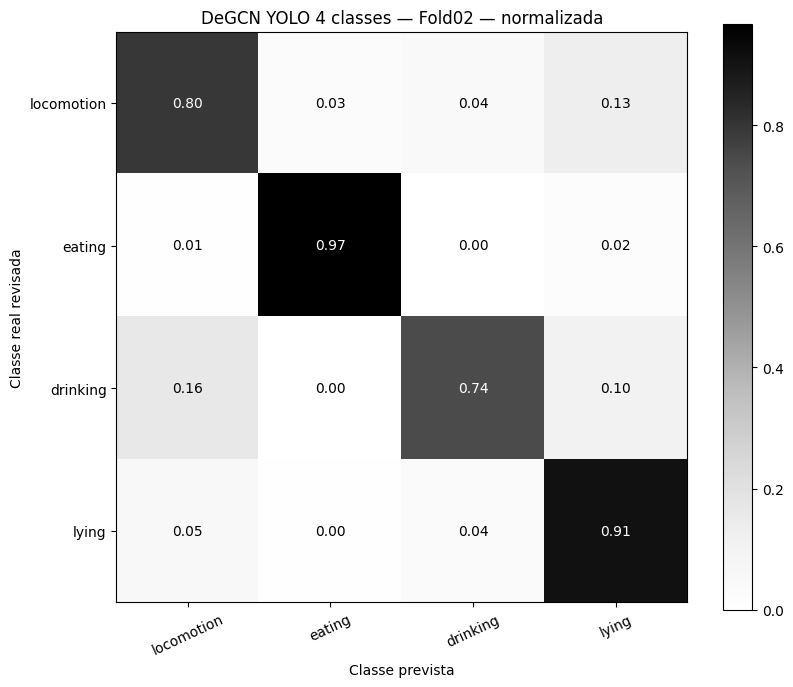


AVALIAÇÃO CONCLUÍDA. Pasta de resultados: F:\Doutorado\anotador_suinos\Anotações\consolidadas unificado3\anotacoes_suinos_20261110_211312\reavaliacao_DeGCN_4classes_fold2


In [22]:
# -*- coding: utf-8 -*-
"""Reavaliação DeGCN YOLO T=15 / 4 classes / fold02 sobre unificados3 revisado."""
from pathlib import Path
from collections import Counter
import json
import sys
import hashlib

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# 1. Arquivos: checkpoint já copiado à pasta de melhores modelos
BASE = Path(r"F:\Doutorado\anotador_suinos")
MODELOS = BASE / "modelos" / "melhores_modelos"
CHECKPOINT = MODELOS / "DeGCN_4classes" / "degcn_fold2.pth"
ORIGINAL = Path(r"F:\Doutorado\experimentos\degcn\experiments\degcn_yolo_T15_4cls_5fold\fold02.pth")
CODIGO_DEGCN = Path(r"F:\Doutorado\DeGCN_pytorch-main\DeGCN_pytorch-main")
MAPA_CLASSES = Path(r"F:\meus_dados_degcn_yolo_T15\merged_4classes\labels_map_4cls.json")
JSON_ANOTACOES = (BASE / "Anotações" / "consolidadas unificado3" /
                  "anotacoes_suinos_20261110_211312" / "anotacoes_consolidadas.json")
SAIDA = JSON_ANOTACOES.parent / "reavaliacao_DeGCN_4classes_fold2"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T, V, BATCH_SIZE = 15, 9, 64

for item in [JSON_ANOTACOES, CODIGO_DEGCN / "graph" / "pig.py",
             CODIGO_DEGCN / "model" / "degcn.py", MAPA_CLASSES]:
    if not item.is_file():
        raise FileNotFoundError(f"Arquivo obrigatório ausente: {item}")
if not CHECKPOINT.is_file():
    if ORIGINAL.is_file():
        print("[AVISO] Modelo ainda não encontrado em melhores_modelos; usando origem:", ORIGINAL)
        CHECKPOINT = ORIGINAL
    else:
        raise FileNotFoundError(f"Checkpoint ausente em ambos os caminhos: {CHECKPOINT} / {ORIGINAL}")

# 2. Usar mapa de índices original do experimento, sem pressupor ordem.
with MAPA_CLASSES.open("r", encoding="utf-8-sig") as f:
    mapa_bruto = json.load(f)
if "idx_to_class" in mapa_bruto:
    idx_para_classe = {int(k): str(v) for k, v in mapa_bruto["idx_to_class"].items()}
if "idx_to_class" not in mapa_bruto:
    if "class_to_idx" in mapa_bruto:
        idx_para_classe = {int(v): str(k) for k, v in mapa_bruto["class_to_idx"].items()}
    else:
        idx_para_classe = {int(k): str(v) for k, v in mapa_bruto.items()}
if sorted(idx_para_classe) != list(range(4)):
    raise ValueError(f"Mapa de classes não tem índices 0..3: {idx_para_classe}")
NOMES_ORIGINAIS = [idx_para_classe[i] for i in range(4)]
CANON = {"deslocando":"locomotion", "locomotion":"locomotion",
         "eating":"eating", "drinking":"drinking",
         "deitado":"lying", "lying":"lying"}
CLASSES = [CANON.get(s.strip().lower()) for s in NOMES_ORIGINAIS]
if set(CLASSES) != {"locomotion", "eating", "drinking", "lying"}:
    raise ValueError(f"Classes incompatíveis com o protocolo: {NOMES_ORIGINAIS} -> {CLASSES}")
INDICE = {classe: i for i, classe in enumerate(CLASSES)}
print("Classes do treinamento (ordem e índice):", idx_para_classe)
print("Classes usadas nos relatórios:", CLASSES)
print("Checkpoint:", CHECKPOINT)
print("Dispositivo:", DEVICE)

# 3. Carregar arquitetura, grafo e pesos, mantendo configuração de treinamento
if str(CODIGO_DEGCN) not in sys.path:
    sys.path.insert(0, str(CODIGO_DEGCN))
from graph.pig import Graph
from model.degcn import Model as DeGCN

graph = Graph(strategy="spatial", center=1)
pais = [-1] * V
for filho, pai in graph.inward:
    pais[int(filho)] = int(pai)
if pais != [1, -1, 1, 4, 1, 4, 1, 1, 1]:
    raise ValueError(f"Grafo de keypoints incompatível: {pais}")

ckpt = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
if not isinstance(ckpt, dict) or not isinstance(ckpt.get("model"), dict):
    raise ValueError("Esperado checkpoint DeGCN com dicionário de pesos 'model'.")
for chave, valor in {"num_classes":4,"V":9,"C":4,"M":1,"center":1,"use_bone":1}.items():
    if chave not in ckpt or int(ckpt[chave]) != valor:
        raise ValueError(f"Metadado {chave} incompatível/ausente: {ckpt.get(chave)} (esperado {valor})")
if ckpt.get("graph_strategy") != "spatial":
    raise ValueError(f"Estratégia de grafo inesperada: {ckpt.get('graph_strategy')}")

modelo = DeGCN(num_class=4, num_point=9, num_person=1, k=2,
               eta=int(ckpt["eta"]), num_stream=1,
               graph="graph.pig.Graph", graph_args={"strategy":"spatial", "center":1},
               in_channels=4, drop_out=0)
modelo.load_state_dict(ckpt["model"], strict=True)
modelo = modelo.to(DEVICE).eval()

# 4. Montar amostras por animal-clipe; GT é a classe revisada.
with JSON_ANOTACOES.open("r", encoding="utf-8-sig") as f:
    dados = json.load(f)
clipes = dados["clipes"]
if len(clipes) != 414:
    raise ValueError(f"Esperados 414 clipes; encontrados {len(clipes)}")

def agrupar(nome):
    nome = str(nome).strip().lower()
    if nome in ("walking", "running", "locomotion", "deslocando"):
        return "locomotion"
    if nome in ("lying awake", "sleeping", "lying", "deitado"):
        return "lying"
    if nome in ("eating", "drinking", "exploring"):
        return nome
    raise ValueError(f"Comportamento não reconhecido: {nome!r}")

entradas, verdadeiros, metadados = [], [], []
excluidos = Counter()
chaves = set()
for clipe in clipes:
    nome_video = Path(str(clipe["video"])).name
    frames = clipe.get("frames", [])
    if len(frames) != T:
        raise ValueError(f"{nome_video}: {len(frames)} frames em vez de 15")
    largura, altura = float(clipe["width"]), float(clipe["height"])
    if largura <= 0 or altura <= 0:
        raise ValueError(f"{nome_video}: dimensões inválidas")
    mapas = []
    for t, frame in enumerate(frames):
        mapa = {}
        for animal in frame["animals"]:
            tid = int(animal["track_id"])
            if tid in mapa:
                raise ValueError(f"{nome_video} frame {t}: track duplicado {tid}")
            mapa[tid] = animal
        mapas.append(mapa)
    ids = set(mapas[0])
    if any(set(m) != ids for m in mapas[1:]):
        raise ValueError(f"{nome_video}: track_ids variam entre frames")
    for tid in sorted(ids):
        chave = (nome_video.lower(), tid)
        if chave in chaves:
            raise ValueError(f"Instância duplicada: {chave}")
        chaves.add(chave)
        pts = np.zeros((T, V, 2), dtype=np.float32)
        rotulos = []
        for t, mapa in enumerate(mapas):
            animal = mapa[tid]
            arr = np.asarray(animal["keypoints"], dtype=np.float32)
            if arr.shape != (V, 2) or not np.isfinite(arr).all():
                raise ValueError(f"{nome_video}, ID {tid}, frame {t}: keypoints inválidos")
            pts[t] = arr
            rotulos.append(agrupar(animal.get("behavior")))
        if len(set(rotulos)) != 1:
            raise ValueError(f"{nome_video}, ID {tid}: rótulos diferentes: {set(rotulos)}")
        classe_real = rotulos[0]
        if classe_real == "exploring":
            excluidos["exploring"] += 1
            continue
        pos = np.zeros((2, T, V, 1), dtype=np.float32)
        pos[0, :, :, 0] = pts[:, :, 0] / largura
        pos[1, :, :, 0] = pts[:, :, 1] / altura
        bone = np.zeros_like(pos)
        for j, pai in enumerate(pais):
            if pai >= 0:
                bone[:, :, j, :] = pos[:, :, j, :] - pos[:, :, pai, :]
        x = np.concatenate([pos, bone], axis=0)
        if x.shape != (4, 15, 9, 1):
            raise ValueError(f"Formato de entrada incorreto: {x.shape}")
        entradas.append(x)
        verdadeiros.append(INDICE[classe_real])
        metadados.append({"arquivo":nome_video, "track_id":tid,
                          "classe_real":classe_real,
                          "status_clipe":clipe.get("review_status", "")})
if not entradas:
    raise RuntimeError("Nenhuma amostra válida")
X = np.stack(entradas).astype(np.float32)
y_true = np.asarray(verdadeiros, dtype=np.int64)
print(f"Clipes: {len(clipes)} | Instâncias: {len(X)} | Exploring excluídos: {excluidos['exploring']}")
print("Entrada DeGCN:", X.shape)
print("Distribuição:", {c:int((y_true == i).sum()) for i,c in enumerate(CLASSES)})

# 5. Predição
probs_partes = []
with torch.inference_mode():
    for inicio in range(0, len(X), BATCH_SIZE):
        fim = min(inicio + BATCH_SIZE, len(X))
        batch = torch.from_numpy(X[inicio:fim]).to(DEVICE)
        logits = modelo(batch)
        if isinstance(logits, (list, tuple)):
            if len(logits) != 1:
                raise ValueError("Saídas múltiplas do modelo")
            logits = logits[0]
        if tuple(logits.shape) != (fim - inicio, 4):
            raise ValueError(f"Saída inesperada do DeGCN: {tuple(logits.shape)}")
        probs_partes.append(torch.softmax(logits, dim=1).cpu().numpy())
probs = np.concatenate(probs_partes, axis=0)
y_pred = probs.argmax(axis=1)

# 6. Métricas, resultados individuais
acc = accuracy_score(y_true, y_pred)
precision, recall, f1, suporte = precision_recall_fscore_support(
    y_true, y_pred, labels=np.arange(4), zero_division=0)
macro_f1 = float(np.mean(f1))
macro_p, macro_r = float(np.mean(precision)), float(np.mean(recall))
relatorio = pd.DataFrame({"classe":CLASSES,"precision":precision,"recall":recall,
                          "f1":f1,"suporte":suporte})
print("\n" + "="*65 + "\nDeGCN YOLO 4 CLASSES — FOLD02 (TESTE REVISADO)\n" + "="*65)
print(f"Accuracy: {acc:.4f}\nMacro-Precision: {macro_p:.4f}\nMacro-Recall: {macro_r:.4f}\nMacro-F1: {macro_f1:.4f}")
print(classification_report(y_true, y_pred, labels=np.arange(4),
                            target_names=CLASSES, digits=4, zero_division=0))
try:
    display(relatorio.round(4))
except NameError:
    print(relatorio.round(4).to_string(index=False))

SAIDA.mkdir(parents=True, exist_ok=True)
cm = confusion_matrix(y_true, y_pred, labels=np.arange(4))
cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(4), normalize="true")
for matriz, nome, formato in [(cm,"absoluta","d"), (cm_norm,"normalizada",".2f")]:
    fig, ax = plt.subplots(figsize=(8.5, 7.0))
    ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=CLASSES).plot(
        ax=ax, cmap="Greys", values_format=formato, colorbar=True, xticks_rotation=25)
    ax.set_title(f"DeGCN YOLO 4 classes — Fold02 — {nome}")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real revisada")
    fig.tight_layout()
    fig.savefig(SAIDA / f"matriz_confusao_{nome}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    pd.DataFrame(matriz,index=CLASSES,columns=CLASSES).to_csv(
        SAIDA / f"matriz_confusao_{nome}.csv", encoding="utf-8-sig")

relatorio.to_csv(SAIDA / "metricas_por_classe.csv", index=False, encoding="utf-8-sig")
predicoes = pd.DataFrame(metadados)
predicoes["classe_prevista"] = [CLASSES[i] for i in y_pred]
predicoes["correto"] = y_pred == y_true
predicoes["confianca_degcn"] = probs.max(axis=1)
for j, classe in enumerate(CLASSES):
    predicoes[f"prob_{classe}"] = probs[:, j]
predicoes.to_csv(SAIDA / "predicoes_por_animal.csv",index=False,encoding="utf-8-sig")

resumo = pd.DataFrame([{"modelo":"DeGCN YOLO T15 4c", "fold":2,
    "checkpoint":str(CHECKPOINT), "mapa_classes":str(MAPA_CLASSES),
    "clipes":len(clipes), "instancias":len(y_true),
    "excluidas_exploring":excluidos["exploring"],
    "accuracy":acc,"macro_precision":macro_p,"macro_recall":macro_r,"macro_f1":macro_f1,
    "macro_f1_original_fold2":0.924479}])
resumo.to_csv(SAIDA / "metricas_globais.csv",index=False,encoding="utf-8-sig")
with (SAIDA / "configuracao_avaliacao.json").open("w",encoding="utf-8") as f:
    json.dump({"checkpoint":str(CHECKPOINT), "classes_originais":NOMES_ORIGINAIS,
               "classes_relatorio":CLASSES,"anotacoes":str(JSON_ANOTACOES),
               "total_clipes":len(clipes), "n_instancias":len(y_true),
               "exploring_excluidos":excluidos["exploring"]}, f,indent=2,ensure_ascii=False)
print("\nAVALIAÇÃO CONCLUÍDA. Pasta de resultados:", SAIDA)


### Step 13 — DeGCN six-class predictions aggregated to four classes

**Purpose.** Reads saved DeGCN six-class predictions and maps walking + running to locomotion and lying awake + sleeping to lying; no new neural-network inference occurs.

**Inputs and dependencies.** Final six-class per-animal predictions CSV created by the revised DeGCN cell.

**Expected outputs.** Aggregated four-class metrics and confusion matrices with exactly the same sample identities.

**Reproducibility and interpretation.** The result is **6c → 4c**, not a model trained directly with four classes; check that the CSV refers to the final annotation revision.



DeGCN FOLD2 — 6 CLASSES CONVERTIDO PARA 4
Instâncias: 3969
Accuracy original 6c: 0.8917
Accuracy agrupada 4c: 0.9342
Macro-Precision 4c:    0.9139
Macro-Recall 4c:       0.9148
Macro-F1 4c:           0.9133


,classe,precision,recall,f1,suporte
0,locomotion,0.8704,0.9532,0.9099,1155
1,eating,0.9875,0.9968,0.9922,1268
2,drinking,0.8300,0.8333,0.8317,252
3,lying,0.9675,0.8756,0.9193,1294



RELATÓRIO COMPLETO
              precision    recall  f1-score   support

  locomotion     0.8704    0.9532    0.9099      1155
      eating     0.9875    0.9968    0.9922      1268
    drinking     0.8300    0.8333    0.8317       252
       lying     0.9675    0.8756    0.9193      1294

    accuracy                         0.9342      3969
   macro avg     0.9139    0.9148    0.9133      3969
weighted avg     0.9369    0.9342    0.9343      3969


ACERTOS RECUPERADOS PELO AGRUPAMENTO
Total: 169
Previsto 6c  lying awake  running  sleeping  walking
Real 6c                                             
lying awake            0        0        42        0
running                0        0         0       65
sleeping              47        0         0        0
walking                0       15         0        0

Diferença de acurácia: 4.26 pontos percentuais


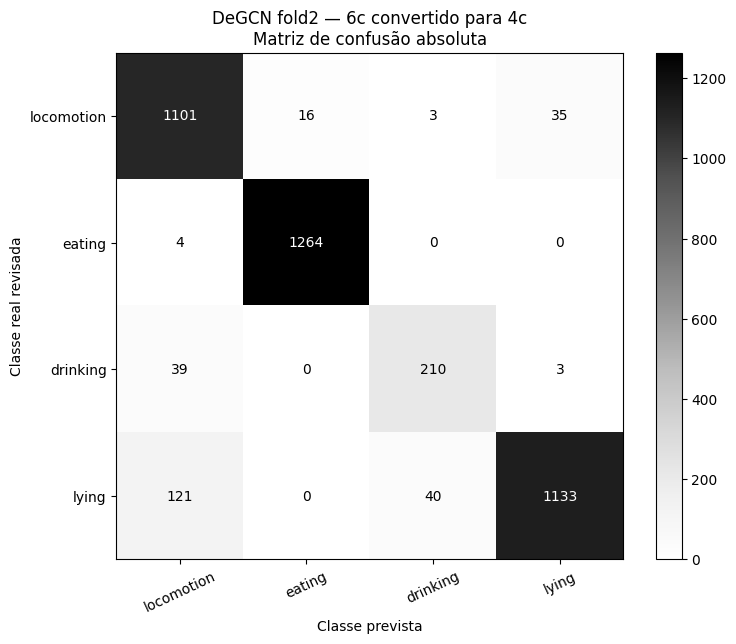

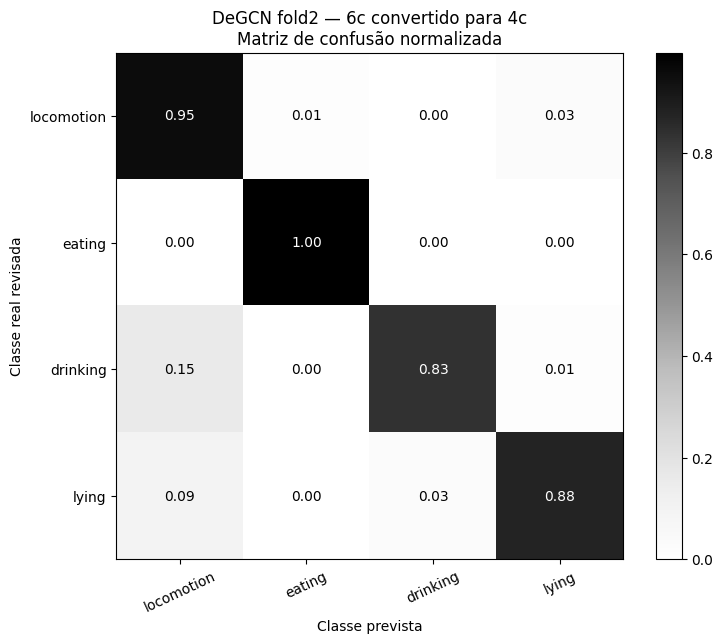


Arquivos salvos em:
F:\Doutorado\anotador_suinos\Anotações\consolidadas unificado3\anotacoes_suinos_20261110_211312\reavaliacao_DeGCN_6c_convertido_4c


In [30]:

# ============================================================
# DeGCN 6c -> 4c | AGRUPAMENTO DAS PREDIÇÕES
# Mesmo checkpoint, mesmas 3969 instâncias
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

BASE = Path(
    r"F:\Doutorado\anotador_suinos\Anotações"
    r"\consolidadas unificado3"
    r"\anotacoes_suinos_20261110_211312"
)

# Se a avaliação atualizada foi salva em outra pasta,
# altere somente este caminho.
ARQUIVO_6C = (
    BASE / "reavaliacao_DeGCN_fold2"
    / "predicoes_por_animal.csv"
)

SAIDA = BASE / "reavaliacao_DeGCN_6c_convertido_4c"

if not ARQUIVO_6C.is_file():
    raise FileNotFoundError(
        f"Localize o CSV atualizado do DeGCN 6c:\n{ARQUIVO_6C}"
    )

CLASSES_6C = [
    "walking", "running", "eating",
    "drinking", "lying awake", "sleeping"
]

CLASSES_4C = [
    "locomotion", "eating", "drinking", "lying"
]

MAPA = {
    "walking": "locomotion",
    "running": "locomotion",
    "eating": "eating",
    "drinking": "drinking",
    "lying awake": "lying",
    "sleeping": "lying"
}

df = pd.read_csv(ARQUIVO_6C)

obrigatorias = [
    "arquivo", "track_id",
    "classe_real", "classe_prevista"
]

faltantes = [c for c in obrigatorias if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")

if len(df) != 3969:
    raise ValueError(
        f"Esperadas 3969 instâncias; CSV possui {len(df)}. "
        "Confira se é a execução atualizada."
    )

if df.duplicated(["arquivo", "track_id"]).any():
    raise ValueError("Existem instâncias duplicadas.")

for coluna in ["classe_real", "classe_prevista"]:
    df[coluna] = df[coluna].replace({
        "lying": "lying awake"
    })

    invalidas = set(df[coluna].dropna()) - set(CLASSES_6C)
    if invalidas or df[coluna].isna().any():
        raise ValueError(
            f"Rótulos inválidos em {coluna}: {invalidas}"
        )

# Agrupar tanto o ground truth como as predições
df["classe_real_4c"] = df["classe_real"].map(MAPA)
df["classe_prevista_4c"] = df["classe_prevista"].map(MAPA)

y6_real = df["classe_real"].to_numpy()
y6_pred = df["classe_prevista"].to_numpy()

y4_real = df["classe_real_4c"].to_numpy()
y4_pred = df["classe_prevista_4c"].to_numpy()

# ------------------------------------------------------------
# MÉTRICAS
# ------------------------------------------------------------

acc6 = accuracy_score(y6_real, y6_pred)
acc4 = accuracy_score(y4_real, y4_pred)

if acc4 + 1e-12 < acc6:
    raise AssertionError(
        "Erro: agrupar classes não pode reduzir a acurácia."
    )

p, r, f1, suporte = precision_recall_fscore_support(
    y4_real,
    y4_pred,
    labels=CLASSES_4C,
    zero_division=0
)

macro_f1 = float(np.mean(f1))

print("=" * 70)
print("DeGCN FOLD2 — 6 CLASSES CONVERTIDO PARA 4")
print("=" * 70)

print("Instâncias:", len(df))
print(f"Accuracy original 6c: {acc6:.4f}")
print(f"Accuracy agrupada 4c: {acc4:.4f}")
print(f"Macro-Precision 4c:    {np.mean(p):.4f}")
print(f"Macro-Recall 4c:       {np.mean(r):.4f}")
print(f"Macro-F1 4c:           {macro_f1:.4f}")

relatorio = pd.DataFrame({
    "classe": CLASSES_4C,
    "precision": p,
    "recall": r,
    "f1": f1,
    "suporte": suporte
})

display(relatorio.round(4))

print("\nRELATÓRIO COMPLETO")
print(classification_report(
    y4_real, y4_pred,
    labels=CLASSES_4C,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# VERIFICAR ERROS QUE VIRARAM ACERTOS
# ------------------------------------------------------------

correto6 = y6_real == y6_pred
correto4 = y4_real == y4_pred

ganhos = (~correto6) & correto4

print("\nACERTOS RECUPERADOS PELO AGRUPAMENTO")
print("Total:", int(ganhos.sum()))

print(pd.crosstab(
    pd.Series(y6_real[ganhos], name="Real 6c"),
    pd.Series(y6_pred[ganhos], name="Previsto 6c")
))

print(
    "\nDiferença de acurácia:",
    f"{(acc4 - acc6)*100:.2f} pontos percentuais"
)

# ------------------------------------------------------------
# MATRIZES DE CONFUSÃO
# ------------------------------------------------------------

SAIDA.mkdir(parents=True, exist_ok=True)

cm = confusion_matrix(
    y4_real, y4_pred,
    labels=CLASSES_4C
)

cm_norm = confusion_matrix(
    y4_real, y4_pred,
    labels=CLASSES_4C,
    normalize="true"
)

for nome, matriz, formato in [
    ("absoluta", cm, "d"),
    ("normalizada", cm_norm, ".2f")
]:
    fig, ax = plt.subplots(figsize=(8, 6.5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASSES_4C
    )

    disp.plot(
        ax=ax,
        cmap="Greys",
        values_format=formato,
        xticks_rotation=25,
        colorbar=True
    )

    ax.set_title(
        "DeGCN fold2 — 6c convertido para 4c\n"
        f"Matriz de confusão {nome}"
    )
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real revisada")

    fig.tight_layout()
    fig.savefig(
        SAIDA / f"matriz_confusao_{nome}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    pd.DataFrame(
        matriz,
        index=CLASSES_4C,
        columns=CLASSES_4C
    ).to_csv(
        SAIDA / f"matriz_confusao_{nome}.csv",
        encoding="utf-8-sig"
    )

relatorio.to_csv(
    SAIDA / "metricas_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

df["correto_6c"] = correto6
df["correto_4c"] = correto4
df["acerto_recuperado"] = ganhos

df.to_csv(
    SAIDA / "predicoes_6c_agrupadas_4c.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame([{
    "modelo": "DeGCN 6c fold2 convertido para 4c",
    "n": len(df),
    "accuracy_6c": acc6,
    "accuracy_4c": acc4,
    "macro_precision_4c": np.mean(p),
    "macro_recall_4c": np.mean(r),
    "macro_f1_4c": macro_f1,
    "acertos_recuperados": int(ganhos.sum())
}]).to_csv(
    SAIDA / "metricas_globais.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArquivos salvos em:")
print(SAIDA)


# Avaliação KPTCN 6 classes melhor modelo

### Step 16 — KP-TCN six-class inference

**Purpose.** Constructs T=15 feature vectors from nine normalized keypoints and their velocities (36 features per frame), then runs the six-class KP-TCN checkpoint.

**Inputs and dependencies.** Final annotation JSON, compatible TorchScript architecture and fold1 weights selected by original validation.

**Expected outputs.** Six-class predictions, aggregate and class-level scores, and confusion matrices.

**Reproducibility and interpretation.** The sequence feature order and normalization must match those used during training; evaluation must be inference only.



REAVALIAÇÃO KP-TCN — 6 CLASSES
Dispositivo: cuda
Checkpoint fold1: F:\Doutorado\anotador_suinos\modelos\kptcn\fold1\tcn_best.pt
Arquitetura TorchScript: F:\Doutorado\anotador_suinos\modelos\kptcn\kptcn_6classes_torchscript.pt

Clipes encontrados: 414
Pesos do fold1 carregados corretamente.
Época: 51 | melhor F1 de validação: 0.7229533193809611

KP-TCN carregado corretamente.
Entrada esperada: (N, 15, 36)
Saída esperada:   (N, 6)

DADOS DA REAVALIAÇÃO
Instâncias encontradas: 5180
Instâncias avaliadas:   3969
Exploring excluídos:    1211
Formato de entrada:    (3969, 15, 36)

Distribuição das classes:
walking        : 885
running        : 270
eating         : 1268
drinking       : 252
lying awake    : 640
sleeping       : 654

Executando inferência KP-TCN...
Processadas 3969/3969 instâncias
Inferência concluída.

RESULTADOS — KP-TCN FOLD1 (6 CLASSES)
Accuracy:        0.7720
Macro-Precision: 0.7384
Macro-Recall:    0.7217
Macro-F1:        0.7244


,classe,precision,recall,f1,suporte
0,walking,0.8256,0.6847,0.7486,885
1,running,0.8434,0.6185,0.7137,270
2,eating,0.9646,0.9882,0.9762,1268
3,drinking,0.5863,0.7143,0.6440,252
4,lying awake,0.4887,0.5734,0.5277,640
5,sleeping,0.7221,0.7508,0.7361,654



CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     walking     0.8256    0.6847    0.7486       885
     running     0.8434    0.6185    0.7137       270
      eating     0.9646    0.9882    0.9762      1268
    drinking     0.5863    0.7143    0.6440       252
 lying awake     0.4887    0.5734    0.5277       640
    sleeping     0.7221    0.7508    0.7361       654

    accuracy                         0.7720      3969
   macro avg     0.7384    0.7217    0.7244      3969
weighted avg     0.7846    0.7720    0.7746      3969



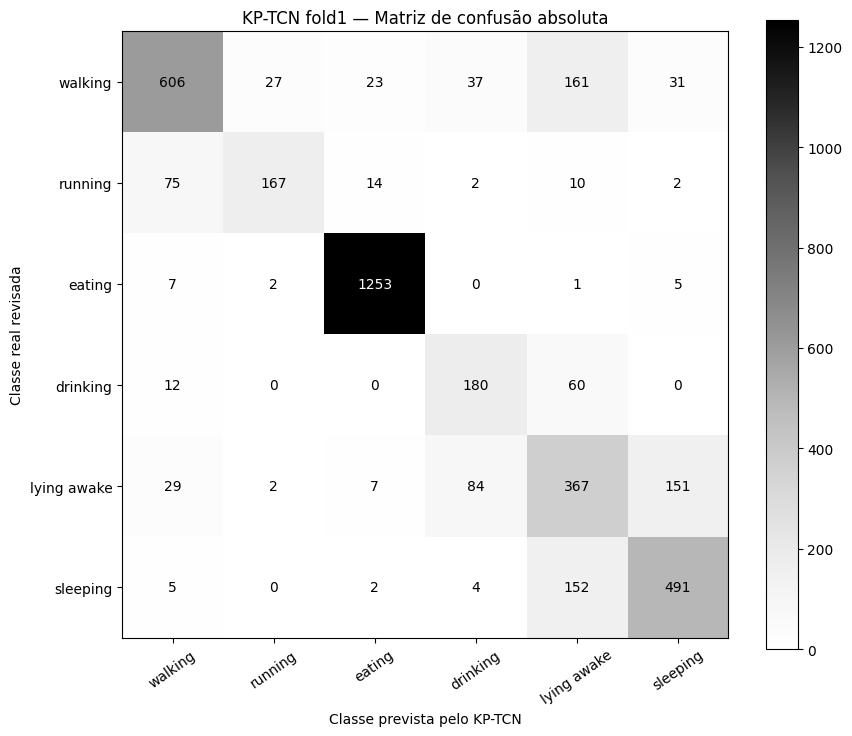

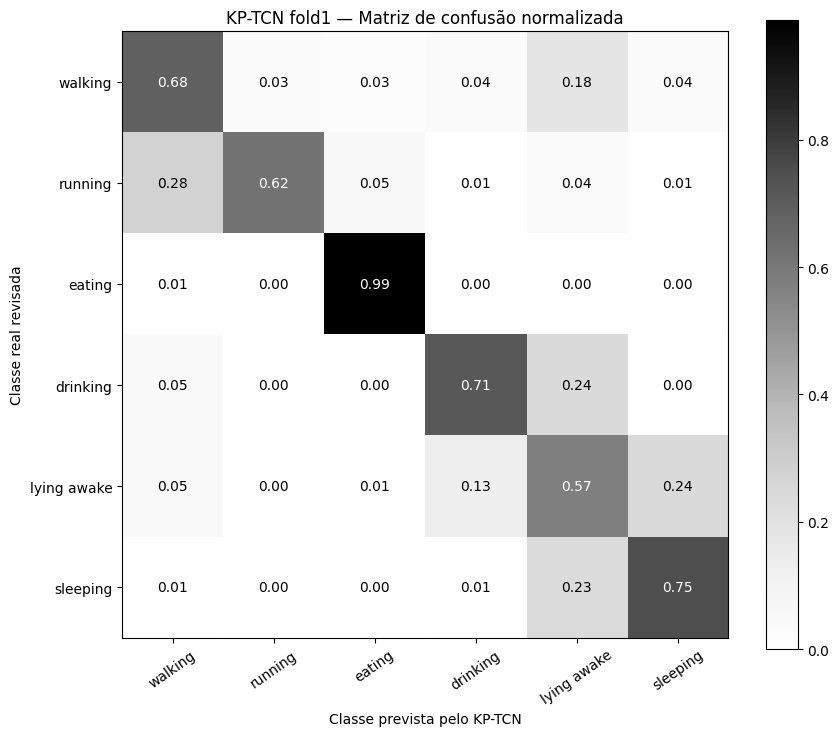


Comparação com DeGCN não realizada: arquivo de predições não encontrado.

REAVALIAÇÃO KP-TCN FOLD1 CONCLUÍDA
Checkpoint: tcn_best.pt
Clipes: 414
Instâncias avaliadas: 3969
Exploring excluídos: 1211
Accuracy: 0.7720
Macro-F1: 0.7244

Resultados salvos em:
F:\Doutorado\anotador_suinos\Anotações\consolidadas unificado3\anotacoes_suinos_20261110_211312\reavaliacao_KPTCN_fold1_6classes


In [12]:

# ================================================================
# REAVALIAÇÃO KP-TCN — UNIFICADOS3
#
# 414 clipes revisados
# 6 classes | T=15 | 9 keypoints
# Entrada: (N, 15, 36) — posição + velocidade
#
# Referência: comportamento final revisado
# Modelo: KP-TCN fold1 (pesos do checkpoint de treinamento)
# ================================================================

from pathlib import Path
from collections import Counter
from datetime import datetime
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ================================================================
# 1. CONFIGURAÇÕES
# ================================================================

BASE = Path(r"F:\Doutorado\anotador_suinos")

JSON_ANOTACOES = (
    BASE / "Anotações" /
    "consolidadas unificado3" /
    "anotacoes_suinos_20261110_211312" /
    "anotacoes_consolidadas.json"
)

CHECKPOINT = (
    BASE / "modelos" / "kptcn" / "fold1" / "tcn_best.pt"
)

ARQUITETURA_TORCHSCRIPT = (
    BASE / "modelos" / "kptcn" / "kptcn_6classes_torchscript.pt"
)

SAIDA = (
    JSON_ANOTACOES.parent /
    "reavaliacao_KPTCN_fold1_6classes"
)

CLASSES = [
    "walking",
    "running",
    "eating",
    "drinking",
    "lying awake",
    "sleeping"
]

T = 15
V = 9
BATCH_SIZE = 64

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if not JSON_ANOTACOES.is_file():
    raise FileNotFoundError(JSON_ANOTACOES)

if not CHECKPOINT.is_file():
    raise FileNotFoundError(CHECKPOINT)
if not ARQUITETURA_TORCHSCRIPT.is_file():
    raise FileNotFoundError(ARQUITETURA_TORCHSCRIPT)

print("=" * 70)
print("REAVALIAÇÃO KP-TCN — 6 CLASSES")
print("=" * 70)

print("Dispositivo:", DEVICE)
print("Checkpoint fold1:", CHECKPOINT)
print("Arquitetura TorchScript:", ARQUITETURA_TORCHSCRIPT)

# ================================================================
# 2. CARREGAR ANOTAÇÕES
# ================================================================

with JSON_ANOTACOES.open(
    "r", encoding="utf-8-sig"
) as f:
    dados = json.load(f)

clipes = dados["clipes"]

print("\nClipes encontrados:", len(clipes))

if len(clipes) != 414:
    raise ValueError(
        f"Esperados 414 clipes; encontrados {len(clipes)}"
    )

# ================================================================
# 3. CARREGAR MODELO KP-TCN
# ================================================================

# O checkpoint fold1 é um state_dict, não um arquivo TorchScript.
# Utilizar a arquitetura TorchScript idêntica à do experimento.
modelo = torch.jit.load(
    str(ARQUITETURA_TORCHSCRIPT), map_location="cpu"
)

ckpt = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=True
)

for campo, esperado in (
    ("fold", 1), ("input_dim", 36),
    ("num_classes", 6), ("hidden_dim", 64)
):
    if int(ckpt[campo]) != esperado:
        raise ValueError(
            f"Checkpoint incompatível: {campo}="
            f"{ckpt[campo]} (esperado {esperado})"
        )

estado = ckpt["model_state_dict"]
base_estado = modelo.state_dict()

if set(estado) != set(base_estado):
    raise ValueError(
        "Arquitetura TorchScript incompatível com fold1. "
        f"Ausentes: {sorted(set(base_estado)-set(estado))[:10]}; "
        f"extras: {sorted(set(estado)-set(base_estado))[:10]}"
    )

for nome in estado:
    if estado[nome].shape != base_estado[nome].shape:
        raise ValueError(
            f"Parâmetro incompatível: {nome}, "
            f"fold1={tuple(estado[nome].shape)} "
            f"arquitetura={tuple(base_estado[nome].shape)}"
        )

modelo.load_state_dict(estado, strict=True)
modelo.to(DEVICE).eval()
print("Pesos do fold1 carregados corretamente.")
print("Época:", ckpt["epoch"],
      "| melhor F1 de validação:", ckpt["best_val_f1"])

# Validar dimensões de entrada e saída
with torch.inference_mode():
    teste = torch.zeros(
        (1, T, 36),
        dtype=torch.float32,
        device=DEVICE
    )

    saida_teste = modelo(teste)

    if isinstance(saida_teste, (list, tuple)):
        if len(saida_teste) != 1:
            raise ValueError(
                "Modelo retornou múltiplas saídas"
            )
        saida_teste = saida_teste[0]

    if tuple(saida_teste.shape) != (1, 6):
        raise ValueError(
            "Saída incompatível: "
            f"{tuple(saida_teste.shape)}"
        )

print("\nKP-TCN carregado corretamente.")
print("Entrada esperada: (N, 15, 36)")
print("Saída esperada:   (N, 6)")

# ================================================================
# 4. EXTRAIR AMOSTRAS REVISADAS
# ================================================================

entradas = []
verdadeiros = []
metadados = []

excluidos = Counter()
amostras_lidas = 0
rotulos_invalidos = []

for clipe in clipes:

    video = Path(str(clipe["video"])).name
    frames = clipe.get("frames", [])

    if len(frames) != T:
        raise ValueError(
            f"{video}: esperado 15 frames"
        )

    largura = float(clipe["width"])
    altura = float(clipe["height"])

    if largura <= 0 or altura <= 0:
        raise ValueError(
            f"{video}: dimensões inválidas"
        )

    ids = [
        int(a["track_id"])
        for a in frames[0]["animals"]
    ]

    if len(ids) != len(set(ids)):
        raise ValueError(
            f"{video}: IDs duplicados"
        )

    for tid in ids:

        amostras_lidas += 1

        pontos = np.zeros(
            (T, V, 2),
            dtype=np.float32
        )

        rotulos = []
        rotulos_auto = []

        for t, frame in enumerate(frames):

            encontrados = [
                a for a in frame["animals"]
                if int(a["track_id"]) == tid
            ]

            if len(encontrados) != 1:
                raise ValueError(
                    f"{video}, ID {tid}, frame {t}: "
                    "animal ausente ou duplicado"
                )

            animal = encontrados[0]

            pts = np.asarray(
                animal["keypoints"],
                dtype=np.float32
            )

            if pts.shape != (V, 2):
                raise ValueError(
                    f"{video}, ID {tid}: "
                    f"keypoints inválidos {pts.shape}"
                )

            pontos[t] = pts

            rotulos.append(
                animal.get("behavior")
            )

            rotulos_auto.append(
                animal.get(
                    "behavior_auto",
                    animal.get("behavior")
                )
            )

        # Uma classe por animal-clipe
        if len(set(rotulos)) != 1:
            raise ValueError(
                f"{video}, ID {tid}: "
                f"rótulos inconsistentes {set(rotulos)}"
            )

        classe_real = rotulos[0]

        # Compatibilidade com anotação anterior
        if classe_real == "lying":
            classe_real = "lying awake"

        # Exploring não pertence às 6 classes do modelo
        if classe_real == "exploring":
            excluidos["exploring"] += 1
            continue

        if classe_real not in CLASSES:
            rotulos_invalidos.append(
                (video, tid, classe_real)
            )
            continue

        if not np.isfinite(pontos).all():
            raise ValueError(
                f"{video}, ID {tid}: "
                "coordenadas não finitas"
            )

        # ====================================================
        # 4.1 POSIÇÕES NORMALIZADAS
        #
        # Formato por frame:
        # x0...x8, y0...y8
        # ====================================================

        xy = np.zeros(
            (T, 2, V),
            dtype=np.float32
        )

        xy[:, 0, :] = (
            pontos[:, :, 0] / largura
        )

        xy[:, 1, :] = (
            pontos[:, :, 1] / altura
        )

        pos = xy.reshape(T, 18)

        # ====================================================
        # 4.2 VELOCIDADES NORMALIZADAS
        #
        # vx0...vx8, vy0...vy8
        #
        # Diferença entre frames consecutivos
        # ====================================================

        velocidade = np.zeros_like(xy)

        velocidade[1:] = (
            xy[1:] - xy[:-1]
        )

        vel = velocidade.reshape(T, 18)

        # ====================================================
        # 4.3 ENTRADA FINAL: (15, 36)
        # ====================================================

        X = np.concatenate(
            [pos, vel],
            axis=1
        ).astype(np.float32)

        if X.shape != (15, 36):
            raise ValueError(
                f"Entrada incorreta: {X.shape}"
            )

        entradas.append(X)

        verdadeiros.append(
            CLASSES.index(classe_real)
        )

        metadados.append({
            "arquivo": video,
            "track_id": tid,
            "classe_real": classe_real,
            "classe_automatica_exportada": rotulos_auto[0],
            "status_clipe": clipe.get(
                "review_status", ""
            )
        })

if rotulos_invalidos:
    print("\nRÓTULOS INVÁLIDOS:")
    for item in rotulos_invalidos[:30]:
        print(item)

    raise ValueError(
        "Existem comportamentos incompatíveis "
        "com o KP-TCN 6 classes."
    )

if not entradas:
    raise RuntimeError(
        "Nenhuma amostra válida"
    )

X = np.stack(
    entradas,
    axis=0
).astype(np.float32)

y_true = np.asarray(
    verdadeiros,
    dtype=np.int64
)

print("\n" + "=" * 70)
print("DADOS DA REAVALIAÇÃO")
print("=" * 70)

print("Instâncias encontradas:", amostras_lidas)
print("Instâncias avaliadas:  ", len(y_true))
print("Exploring excluídos:   ", excluidos["exploring"])
print("Formato de entrada:   ", X.shape)

print("\nDistribuição das classes:")

for i, classe in enumerate(CLASSES):
    print(
        f"{classe:15}: "
        f"{np.sum(y_true == i)}"
    )

# ================================================================
# 5. INFERÊNCIA KP-TCN
# ================================================================

predicoes = []
probabilidades = []

print("\nExecutando inferência KP-TCN...")

with torch.inference_mode():

    for inicio in range(
        0,
        len(X),
        BATCH_SIZE
    ):

        fim = min(
            inicio + BATCH_SIZE,
            len(X)
        )

        batch = torch.from_numpy(
            X[inicio:fim]
        ).to(DEVICE)

        logits = modelo(batch)

        if isinstance(logits, (list, tuple)):
            if len(logits) != 1:
                raise ValueError(
                    "Modelo retornou múltiplas saídas"
                )
            logits = logits[0]

        if (
            logits.ndim != 2
            or tuple(logits.shape) != (fim - inicio, 6)
        ):
            raise ValueError(
                f"Logits incompatíveis: "
                f"{tuple(logits.shape)}"
            )

        probs_batch = torch.softmax(
            logits,
            dim=1
        ).cpu().numpy()

        probabilidades.append(probs_batch)

        predicoes.extend(
            probs_batch.argmax(axis=1).tolist()
        )

        print(
            f"Processadas {fim}/{len(X)} instâncias",
            end="\r"
        )

probs = np.concatenate(
    probabilidades,
    axis=0
)

y_pred = np.asarray(
    predicoes,
    dtype=np.int64
)

assert len(y_pred) == len(y_true)

print("\nInferência concluída.")

# ================================================================
# 6. MÉTRICAS GLOBAIS E POR CLASSE
# ================================================================

acc = accuracy_score(
    y_true,
    y_pred
)

precision, recall, f1, suporte = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(6),
        zero_division=0
    )
)

macro_p = float(np.mean(precision))
macro_r = float(np.mean(recall))
macro_f1 = float(np.mean(f1))

print("\n" + "=" * 70)
print("RESULTADOS — KP-TCN FOLD1 (6 CLASSES)")
print("=" * 70)

print(f"Accuracy:        {acc:.4f}")
print(f"Macro-Precision: {macro_p:.4f}")
print(f"Macro-Recall:    {macro_r:.4f}")
print(f"Macro-F1:        {macro_f1:.4f}")

relatorio = pd.DataFrame({
    "classe": CLASSES,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "suporte": suporte
})

display(relatorio.round(4))

print("\nCLASSIFICATION REPORT:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(6),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

# ================================================================
# 7. MATRIZES DE CONFUSÃO
# ================================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(6)
)

cm_norm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(6),
    normalize="true"
)

# ================================================================
# 8. PASTA DE RESULTADOS
# ================================================================

SAIDA.mkdir(
    parents=True,
    exist_ok=True
)

def desenhar_matriz(
    matriz,
    titulo,
    formato,
    caminho
):
    fig, ax = plt.subplots(
        figsize=(9, 7.5)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASSES
    )

    disp.plot(
        ax=ax,
        cmap="Greys",
        values_format=formato,
        colorbar=True,
        xticks_rotation=35
    )

    ax.set_title(titulo)
    ax.set_xlabel("Classe prevista pelo KP-TCN")
    ax.set_ylabel("Classe real revisada")

    fig.tight_layout()

    fig.savefig(
        caminho,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

desenhar_matriz(
    cm,
    "KP-TCN fold1 — Matriz de confusão absoluta",
    "d",
    SAIDA / "matriz_confusao_absoluta.png"
)

desenhar_matriz(
    cm_norm,
    "KP-TCN fold1 — Matriz de confusão normalizada",
    ".2f",
    SAIDA / "matriz_confusao_normalizada.png"
)

# ================================================================
# 9. EXPORTAR RESULTADOS
# ================================================================

pd.DataFrame(
    cm,
    index=CLASSES,
    columns=CLASSES
).to_csv(
    SAIDA / "matriz_confusao.csv",
    encoding="utf-8-sig"
)

pd.DataFrame(
    cm_norm,
    index=CLASSES,
    columns=CLASSES
).to_csv(
    SAIDA / "matriz_confusao_normalizada.csv",
    encoding="utf-8-sig"
)

relatorio.to_csv(
    SAIDA / "metricas_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

resultado_individual = pd.DataFrame(
    metadados
)

resultado_individual["classe_prevista"] = [
    CLASSES[i] for i in y_pred
]

resultado_individual["correto"] = (
    y_true == y_pred
)

resultado_individual["confianca_kptcn"] = (
    probs.max(axis=1)
)

for j, classe in enumerate(CLASSES):

    coluna = (
        "prob_" + classe.replace(" ", "_")
    )

    resultado_individual[coluna] = (
        probs[:, j]
    )

resultado_individual.to_csv(
    SAIDA / "predicoes_por_animal.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo = pd.DataFrame([{
    "checkpoint": str(CHECKPOINT),
    "fold": 1,
    "epoch": int(ckpt["epoch"]),
    "best_val_f1_checkpoint": float(ckpt["best_val_f1"]),
    "total_clipes": len(clipes),
    "instancias_encontradas": amostras_lidas,
    "instancias_avaliadas": len(y_true),
    "excluidas_exploring": excluidos["exploring"],
    "accuracy": acc,
    "macro_precision": macro_p,
    "macro_recall": macro_r,
    "macro_f1": macro_f1
}])

resumo.to_csv(
    SAIDA / "metricas_globais.csv",
    index=False,
    encoding="utf-8-sig"
)

# ================================================================
# 10. COMPARAÇÃO COM DEGCN FOLD2
# ================================================================

arquivo_degcn = (
    JSON_ANOTACOES.parent /
    "reavaliacao_DeGCN_fold2" /
    "predicoes_por_animal.csv"
)

if arquivo_degcn.is_file():

    df_degcn = pd.read_csv(arquivo_degcn)

    chave = ["arquivo", "track_id"]

    comparacao = resultado_individual[
        chave + ["classe_real", "classe_prevista"]
    ].rename(
        columns={
            "classe_prevista": "pred_kptcn"
        }
    ).merge(
        df_degcn[
            chave + ["classe_real", "classe_prevista"]
        ].rename(
            columns={
                "classe_real": "classe_real_degcn",
                "classe_prevista": "pred_degcn"
            }
        ),
        on=chave,
        how="inner",
        validate="one_to_one"
    )

    if len(comparacao) != len(resultado_individual):
        raise ValueError(
            "DeGCN e KP-TCN não avaliaram o "
            "mesmo conjunto de instâncias."
        )

    if not (
        comparacao["classe_real"] ==
        comparacao["classe_real_degcn"]
    ).all():
        raise ValueError(
            "Ground truth diferente entre modelos."
        )

    comparacao["kptcn_correto"] = (
        comparacao["pred_kptcn"] ==
        comparacao["classe_real"]
    )

    comparacao["degcn_correto"] = (
        comparacao["pred_degcn"] ==
        comparacao["classe_real"]
    )

    comparacao.to_csv(
        SAIDA / "comparacao_KPTCN_vs_DeGCN.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\n" + "=" * 70)
    print("COMPARAÇÃO KP-TCN × DeGCN FOLD2")
    print("=" * 70)

    for nome, coluna in [
        ("KP-TCN", "pred_kptcn"),
        ("DeGCN", "pred_degcn")
    ]:

        acuracia = (
            comparacao[coluna] ==
            comparacao["classe_real"]
        ).mean()

        p, r, f, s = (
            precision_recall_fscore_support(
                comparacao["classe_real"],
                comparacao[coluna],
                labels=CLASSES,
                zero_division=0
            )
        )

        print(
            f"{nome:8} | "
            f"Accuracy = {acuracia:.4f} | "
            f"Macro-F1 = {np.mean(f):.4f}"
        )

    print("\nAcertos exclusivos:")

    somente_kptcn = (
        comparacao["kptcn_correto"] &
        ~comparacao["degcn_correto"]
    ).sum()

    somente_degcn = (
        comparacao["degcn_correto"] &
        ~comparacao["kptcn_correto"]
    ).sum()

    print("Apenas KP-TCN acertou:", somente_kptcn)
    print("Apenas DeGCN acertou: ", somente_degcn)

else:
    print(
        "\nComparação com DeGCN não realizada: "
        "arquivo de predições não encontrado."
    )

# ================================================================
# 11. RESUMO FINAL
# ================================================================

print("\n" + "=" * 70)
print("REAVALIAÇÃO KP-TCN FOLD1 CONCLUÍDA")
print("=" * 70)

print("Checkpoint:", CHECKPOINT.name)
print("Clipes:", len(clipes))
print("Instâncias avaliadas:", len(y_true))
print("Exploring excluídos:", excluidos["exploring"])
print(f"Accuracy: {acc:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

print("\nResultados salvos em:")
print(SAIDA)


# Avaliação KPTCN 4 classes

### Step 18 — KP-TCN trained directly for four classes

**Purpose.** Locates the original-validation-selected four-class checkpoint, assembles identical skeleton feature windows and evaluates the four-class model.

**Inputs and dependencies.** Revised annotations, original 4c model checkpoints, 4c TorchScript architecture and class map.

**Expected outputs.** Direct four-class metrics, individual predictions and confusion matrices.

**Reproducibility and interpretation.** The script may search for local checkpoints; verify the original-validation criterion, never the independent-test Macro-F1, determines selection.



CHECKPOINTS KP-TCN 4 CLASSES — RANKING DA VALIDAÇÃO ORIGINAL
 fold  epoch  best_val_f1                                                               arquivo
    2     35     0.924757 F:\Doutorado\anotador_suinos\modelos\kptcn_4classes\fold2\tcn_best.pt
    1     32     0.894334 F:\Doutorado\anotador_suinos\modelos\kptcn_4classes\fold1\tcn_best.pt
    3     51     0.885069 F:\Doutorado\anotador_suinos\modelos\kptcn_4classes\fold3\tcn_best.pt
    0     41     0.871554 F:\Doutorado\anotador_suinos\modelos\kptcn_4classes\fold0\tcn_best.pt
    4      3     0.236559 F:\Doutorado\anotador_suinos\modelos\kptcn_4classes\fold4\tcn_best.pt

SELECIONADO: fold=2 | validação Macro-F1=0.9248
Checkpoint: F:\Doutorado\anotador_suinos\modelos\kptcn_4classes\fold2\tcn_best.pt
Arquitetura e pesos carregados corretamente em cuda

CONJUNTO DE TESTE REVISADO
Clipes: 414
Instâncias avaliadas: 3969
Instâncias excluídas (exploring): 1211
Entrada: (3969, 15, 36)
  locomotion  : 1155
  eating      : 1268
  drinki

,classe,precision,recall,f1,suporte
0,locomotion,0.9658,0.6848,0.8014,1155
1,eating,0.9666,0.9826,0.9746,1268
2,drinking,0.5042,0.9603,0.6612,252
3,lying,0.8219,0.8771,0.8486,1294



              precision    recall  f1-score   support

  locomotion     0.9658    0.6848    0.8014      1155
      eating     0.9666    0.9826    0.9746      1268
    drinking     0.5042    0.9603    0.6612       252
       lying     0.8219    0.8771    0.8486      1294

    accuracy                         0.8602      3969
   macro avg     0.8146    0.8762    0.8214      3969
weighted avg     0.8898    0.8602    0.8632      3969



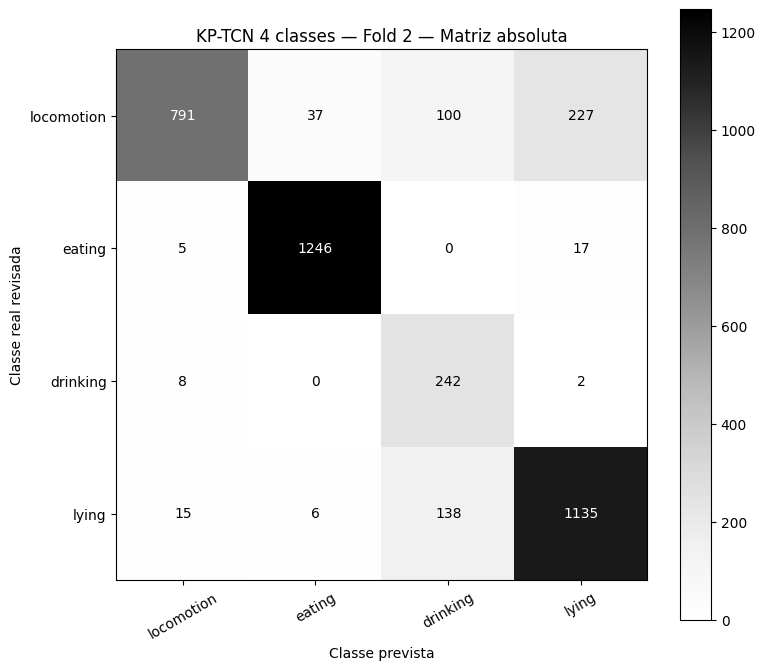

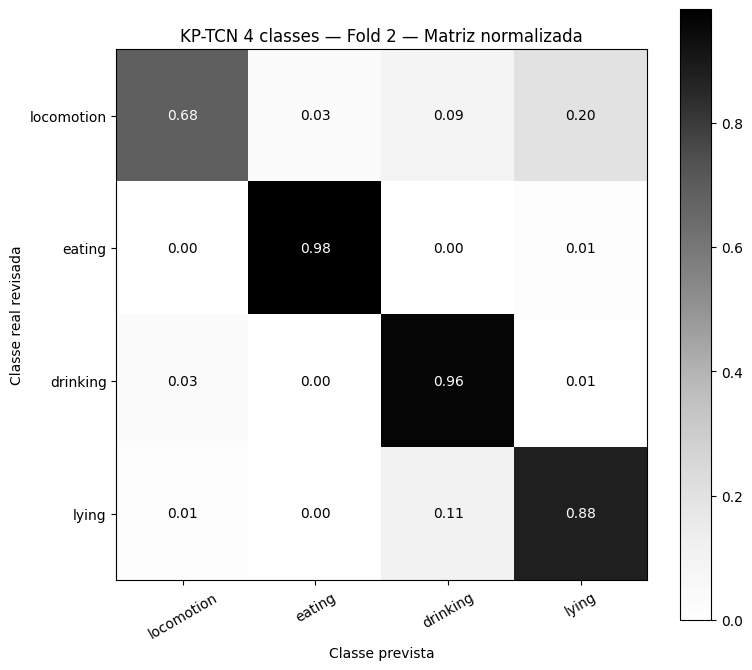


AVALIAÇÃO CONCLUÍDA
Checkpoint: F:\Doutorado\anotador_suinos\modelos\kptcn_4classes\fold2\tcn_best.pt
Resultados: F:\Doutorado\anotador_suinos\Anotações\consolidadas unificado3\anotacoes_suinos_20261110_211312\reavaliacao_KPTCN_melhor_4classes
Nota: comparação direta com DeGCN de 6 classes exige reagrupar as previsões
e usar exatamente as mesmas instâncias para uma comparação 4 classes.


In [35]:
# ================================================================
# REAVALIAÇÃO KP-TCN 4 CLASSES — MELHOR CHECKPOINT ORIGINAL
# Unificados3 | 414 clipes | 15 frames | 9 pontos | 36 atributos
# Seleção do checkpoint: best_val_f1 da validação original
# Não escolhe o modelo pelo desempenho no conjunto independente.
# ================================================================
from pathlib import Path
from collections import Counter
import copy
import json
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

BASE = Path(r"F:\Doutorado\anotador_suinos")
JSON_ANOTACOES = (BASE / "Anotações" / "consolidadas unificado3" /
                  "anotacoes_suinos_20261110_211312" / "anotacoes_consolidadas.json")
PASTA_MODELOS = BASE / "modelos" / "kptcn_4classes"
ARQUITETURA_TORCHSCRIPT = PASTA_MODELOS / "kptcn_4classes_torchscript.pt"
SAIDA = JSON_ANOTACOES.parent / "reavaliacao_KPTCN_melhor_4classes"

# Preencha apenas se os arquivos estiverem em outro local.
# Ao deixar None, o código procura os checkpoints em PASTA_MODELOS.
CHECKPOINT_MANUAL = None

CLASSES = ["locomotion", "eating", "drinking", "lying"]
MAPA_CLASSES = {
    "walking": "locomotion", "running": "locomotion", "locomotion": "locomotion",
    "eating": "eating", "drinking": "drinking",
    "lying awake": "lying", "sleeping": "lying", "lying": "lying"
}
T = 15
V = 9
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def fold_do_caminho(p):
    matches = re.findall(r"fold[_-]?0?([0-4])(?=\D|$)", str(p).lower())
    return int(matches[-1]) if matches else None


def carregar_ckpt(p):
    ck = torch.load(p, map_location="cpu", weights_only=True)
    if not isinstance(ck, dict):
        raise ValueError(f"Checkpoint sem dicionário: {p}")
    for k in ("model_state_dict", "input_dim", "num_classes", "best_val_f1"):
        if k not in ck:
            raise ValueError(f"Checkpoint sem '{k}': {p}")
    if int(ck["input_dim"]) != 36 or int(ck["num_classes"]) != 4:
        raise ValueError(f"Checkpoint não é KP-TCN 4 classes, entrada 36: {p}")
    if not np.isfinite(float(ck["best_val_f1"])):
        raise ValueError(f"best_val_f1 inválido: {p}")
    if not isinstance(ck["model_state_dict"], dict):
        raise ValueError(f"state_dict inválido: {p}")
    return ck


# 1. Localização e seleção do melhor fold (pela validação original)
if not JSON_ANOTACOES.is_file():
    raise FileNotFoundError(JSON_ANOTACOES)
if not ARQUITETURA_TORCHSCRIPT.is_file():
    raise FileNotFoundError(
        f"Arquitetura TorchScript 4 classes não encontrada: {ARQUITETURA_TORCHSCRIPT}\n"
        "Ajuste ARQUITETURA_TORCHSCRIPT para o arquivo real. Não use o TorchScript 6 classes."
    )

if CHECKPOINT_MANUAL is None:
    if not PASTA_MODELOS.is_dir():
        raise FileNotFoundError(f"Pasta dos modelos 4 classes não encontrada: {PASTA_MODELOS}")
    candidatos = sorted(p for p in PASTA_MODELOS.rglob("*")
                        if p.is_file() and p.suffix.lower() in {".pt", ".pth", ".ckpt"}
                        and p != ARQUITETURA_TORCHSCRIPT
                        and "fold" in str(p).lower())
else:
    candidatos = [Path(CHECKPOINT_MANUAL)]

if not candidatos:
    raise FileNotFoundError(
        f"Nenhum checkpoint fold encontrado em {PASTA_MODELOS}. "
        "Ajuste PASTA_MODELOS ou CHECKPOINT_MANUAL."
    )

inventario, carregados, falhas = [], [], []
for p in candidatos:
    try:
        ck = carregar_ckpt(p)
        fold = int(ck["fold"]) if "fold" in ck else fold_do_caminho(p)
        inventario.append({
            "fold": fold, "epoch": ck.get("epoch", None),
            "best_val_f1": float(ck["best_val_f1"]), "arquivo": str(p)
        })
        carregados.append((p, ck, fold))
    except Exception as e:
        falhas.append((str(p), str(e)))

if not carregados:
    print("Arquivos encontrados, mas nenhum checkpoint 4 classes compatível:")
    for arq, erro in falhas:
        print(" -", arq, "|", erro)
    raise RuntimeError("Não foi possível identificar checkpoints KP-TCN 4 classes.")

ranking_validacao = pd.DataFrame(inventario).sort_values(
    ["best_val_f1", "fold"], ascending=[False, True], na_position="last"
).reset_index(drop=True)
print("=" * 72)
print("CHECKPOINTS KP-TCN 4 CLASSES — RANKING DA VALIDAÇÃO ORIGINAL")
print("=" * 72)
print(ranking_validacao.to_string(index=False))
if falhas:
    print("\nArquivos ignorados (formato incompatível):")
    for arq, erro in falhas[:20]:
        print(" -", arq, "|", erro[:160])

melhor_path = Path(ranking_validacao.iloc[0]["arquivo"])
ckpt = next(ck for p, ck, fold in carregados if p == melhor_path)
melhor_fold = int(ckpt["fold"]) if "fold" in ckpt else fold_do_caminho(melhor_path)
print(f"\nSELECIONADO: fold={melhor_fold} | validação Macro-F1={float(ckpt['best_val_f1']):.4f}")
print("Checkpoint:", melhor_path)

# 2. Carregar arquitetura original e pesos rigorosamente
modelo = torch.jit.load(str(ARQUITETURA_TORCHSCRIPT), map_location="cpu")
base_estado = modelo.state_dict()
estado = ckpt["model_state_dict"]
if set(estado) != set(base_estado):
    raise RuntimeError(
        "Parâmetros do checkpoint e TorchScript 4 classes não coincidem.\n"
        f"Faltando: {sorted(set(base_estado)-set(estado))[:12]}\n"
        f"Extras: {sorted(set(estado)-set(base_estado))[:12]}"
    )
formas_incompativeis = [(k, tuple(estado[k].shape), tuple(base_estado[k].shape))
                       for k in estado if estado[k].shape != base_estado[k].shape]
if formas_incompativeis:
    raise RuntimeError(f"Dimensões incompatíveis: {formas_incompativeis[:12]}")
modelo.load_state_dict(estado, strict=True)
modelo = modelo.to(DEVICE).eval()
with torch.inference_mode():
    saida_teste = modelo(torch.zeros(1, T, 36, device=DEVICE))
    if isinstance(saida_teste, (list, tuple)) and len(saida_teste) == 1:
        saida_teste = saida_teste[0]
    if not isinstance(saida_teste, torch.Tensor) or tuple(saida_teste.shape) != (1, 4):
        raise RuntimeError(f"Saída incompatível para 4 classes: {getattr(saida_teste, 'shape', type(saida_teste))}")
print("Arquitetura e pesos carregados corretamente em", DEVICE)

# 3. Extrair mesmos animais dos 414 clipes, com mapeamento das 4 classes
with JSON_ANOTACOES.open("r", encoding="utf-8-sig") as f:
    dados = json.load(f)
clipes = dados["clipes"]
if len(clipes) != 414:
    raise ValueError(f"Esperados 414 clipes, encontrados {len(clipes)}")

entradas, y_true, metadados = [], [], []
excluidos = Counter()
conjunto_chaves = set()

for clipe in clipes:
    video = Path(str(clipe["video"])).name
    frames = clipe.get("frames", [])
    if len(frames) != T:
        raise ValueError(f"{video}: {len(frames)} frames, esperado {T}")
    w, h = float(clipe["width"]), float(clipe["height"])
    if w <= 0 or h <= 0:
        raise ValueError(f"{video}: largura/altura inválidas")
    mapas = []
    for t, frame in enumerate(frames):
        mapa = {}
        for a in frame["animals"]:
            tid = int(a["track_id"])
            if tid in mapa:
                raise ValueError(f"{video}: ID {tid} duplicado no frame {t}")
            mapa[tid] = a
        mapas.append(mapa)
    ids = sorted(mapas[0])
    if any(set(m) != set(ids) for m in mapas[1:]):
        raise ValueError(f"{video}: conjunto de IDs muda entre frames")

    for tid in ids:
        ch = (video.lower(), tid)
        if ch in conjunto_chaves:
            raise ValueError(f"Instância repetida: {ch}")
        conjunto_chaves.add(ch)
        pontos = np.zeros((T, V, 2), dtype=np.float32)
        rotulos = []
        for t in range(T):
            animal = mapas[t][tid]
            pts = np.asarray(animal["keypoints"], dtype=np.float32)
            if pts.shape != (V, 2) or not np.isfinite(pts).all():
                raise ValueError(f"{video} ID {tid}, frame {t}: keypoints inválidos")
            pontos[t] = pts
            rotulos.append(animal.get("behavior"))
        if len(set(rotulos)) != 1:
            raise ValueError(f"{video} ID {tid}: comportamento inconsistente: {set(rotulos)}")
        rotulo_6c = rotulos[0]
        if rotulo_6c == "exploring":
            excluidos["exploring"] += 1
            continue
        if rotulo_6c not in MAPA_CLASSES:
            raise ValueError(f"{video} ID {tid}: classe inesperada: {rotulo_6c!r}")
        classe_4c = MAPA_CLASSES[rotulo_6c]

        # Mesma ordem usada no pipeline: x0..x8,y0..y8,vx0..vx8,vy0..vy8
        xy = np.zeros((T, 2, V), dtype=np.float32)
        xy[:, 0, :] = pontos[:, :, 0] / w
        xy[:, 1, :] = pontos[:, :, 1] / h
        pos = xy.reshape(T, 18)
        vel = np.zeros_like(xy)
        vel[1:] = xy[1:] - xy[:-1]
        X = np.concatenate([pos, vel.reshape(T, 18)], axis=1).astype(np.float32)
        assert X.shape == (15, 36)
        entradas.append(X)
        y_true.append(CLASSES.index(classe_4c))
        metadados.append({
            "arquivo": video, "track_id": tid, "classe_real_6c": rotulo_6c,
            "classe_real": classe_4c, "status_clipe": clipe.get("review_status", "")
        })

if not entradas:
    raise RuntimeError("Nenhuma amostra avaliável")
X = np.stack(entradas).astype(np.float32)
y_true = np.asarray(y_true, dtype=np.int64)
print("\n=" * 1 + "=" * 71)
print("CONJUNTO DE TESTE REVISADO")
print("=" * 72)
print("Clipes:", len(clipes))
print("Instâncias avaliadas:", len(y_true))
print("Instâncias excluídas (exploring):", excluidos["exploring"])
print("Entrada:", X.shape)
for j, classe in enumerate(CLASSES):
    print(f"  {classe:<12}: {int((y_true == j).sum())}")

# 4. Inferência
probs_list = []
with torch.inference_mode():
    for inicio in range(0, len(X), BATCH_SIZE):
        fim = min(inicio + BATCH_SIZE, len(X))
        logits = modelo(torch.from_numpy(X[inicio:fim]).to(DEVICE))
        if isinstance(logits, (tuple, list)) and len(logits) == 1:
            logits = logits[0]
        if not isinstance(logits, torch.Tensor) or tuple(logits.shape) != (fim - inicio, 4):
            raise RuntimeError(f"Saída inválida no batch {inicio}: {getattr(logits, 'shape', type(logits))}")
        probs_list.append(torch.softmax(logits, dim=1).cpu().numpy())
probs = np.concatenate(probs_list)
y_pred = probs.argmax(axis=1)
assert len(y_pred) == len(y_true)

# 5. Métricas e matrizes
acc = accuracy_score(y_true, y_pred)
p, r, f1, suporte = precision_recall_fscore_support(
    y_true, y_pred, labels=np.arange(4), zero_division=0)
macro_p, macro_r, macro_f1 = map(float, [p.mean(), r.mean(), f1.mean()])
relatorio = pd.DataFrame({
    "classe": CLASSES, "precision": p, "recall": r, "f1": f1, "suporte": suporte
})
cm = confusion_matrix(y_true, y_pred, labels=np.arange(4))
cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(4), normalize="true")

print("\n" + "=" * 72)
print(f"RESULTADOS — KP-TCN 4 CLASSES — FOLD {melhor_fold}")
print("=" * 72)
print(f"Accuracy:        {acc:.4f}")
print(f"Macro-Precision: {macro_p:.4f}")
print(f"Macro-Recall:    {macro_r:.4f}")
print(f"Macro-F1:        {macro_f1:.4f}")
try:
    display(relatorio.round(4))
except NameError:
    print(relatorio.round(4).to_string(index=False))
print("\n" + classification_report(y_true, y_pred, labels=np.arange(4),
                                   target_names=CLASSES, digits=4, zero_division=0))

SAIDA.mkdir(parents=True, exist_ok=True)
for tipo, matriz, formato in [("absoluta", cm, "d"), ("normalizada", cm_norm, ".2f")]:
    fig, ax = plt.subplots(figsize=(8, 7))
    disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=CLASSES)
    disp.plot(ax=ax, cmap="Greys", values_format=formato, colorbar=True,
              xticks_rotation=30)
    ax.set_title(f"KP-TCN 4 classes — Fold {melhor_fold} — Matriz {tipo}")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real revisada")
    fig.tight_layout()
    fig.savefig(SAIDA / f"matriz_confusao_{tipo}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    pd.DataFrame(matriz, index=CLASSES, columns=CLASSES).to_csv(
        SAIDA / f"matriz_confusao_{tipo}.csv", encoding="utf-8-sig")

relatorio.to_csv(SAIDA / "metricas_por_classe.csv", index=False, encoding="utf-8-sig")
ranking_validacao.to_csv(SAIDA / "ranking_validacao_original.csv", index=False,
                         encoding="utf-8-sig")

pred = pd.DataFrame(metadados)
pred["classe_prevista"] = [CLASSES[j] for j in y_pred]
pred["correto"] = y_pred == y_true
pred["confianca_kptcn"] = probs.max(axis=1)
for j, classe in enumerate(CLASSES):
    pred["prob_" + classe] = probs[:, j]
pred.to_csv(SAIDA / "predicoes_por_animal.csv", index=False, encoding="utf-8-sig")

resumo = pd.DataFrame([{
    "checkpoint": str(melhor_path), "fold": melhor_fold,
    "epoch": ckpt.get("epoch"), "best_val_f1_checkpoint": float(ckpt["best_val_f1"]),
    "total_clipes": len(clipes), "instancias_avaliadas": len(y_true),
    "excluidas_exploring": excluidos["exploring"], "accuracy": acc,
    "macro_precision": macro_p, "macro_recall": macro_r, "macro_f1": macro_f1,
}])
resumo.to_csv(SAIDA / "metricas_globais.csv", index=False, encoding="utf-8-sig")
print("\nAVALIAÇÃO CONCLUÍDA")
print("Checkpoint:", melhor_path)
print("Resultados:", SAIDA)
print("Nota: comparação direta com DeGCN de 6 classes exige reagrupar as previsões")
print("e usar exatamente as mesmas instâncias para uma comparação 4 classes.")


# KPTCN 6 classes classificando 4 classes

### Step 20 — KP-TCN six-class predictions aggregated to four classes

**Purpose.** Reuses the six-class KP-TCN prediction CSV and maps six ground-truth/predicted categories to four behavioral groups.

**Inputs and dependencies.** Saved KP-TCN 6c inference predictions for the revised independent set.

**Expected outputs.** Aggregated four-class scores and diagnostic confusion matrices.

**Reproducibility and interpretation.** This is post-processing of six-class predictions; do not compare it as a separately trained model.



KP-TCN FOLD1 — 6 CLASSES CONVERTIDO PARA 4
Instâncias avaliadas: 3969

RESULTADOS ORIGINAIS — 6 CLASSES
Accuracy:  0.7720
Macro-F1:  0.7244

RESULTADOS AGRUPADOS — 4 CLASSES
Accuracy:         0.8740
Macro-Precision:  0.8253
Macro-Recall:     0.8393
Macro-F1:         0.8277

DIFERENÇAS
Accuracy: +10.20 pontos percentuais
Macro-F1: +10.33 pontos percentuais

F1 POR CLASSE — KP-TCN 6c -> 4c


,classe,precision,recall,f1,suporte
0,locomotion,0.9388,0.7576,0.8385,1155
1,eating,0.9646,0.9882,0.9762,1268
2,drinking,0.5863,0.7143,0.6440,252
3,lying,0.8113,0.8972,0.8521,1294



RELATÓRIO COMPLETO
              precision    recall  f1-score   support

  locomotion     0.9388    0.7576    0.8385      1155
      eating     0.9646    0.9882    0.9762      1268
    drinking     0.5863    0.7143    0.6440       252
       lying     0.8113    0.8972    0.8521      1294

    accuracy                         0.8740      3969
   macro avg     0.8253    0.8393    0.8277      3969
weighted avg     0.8831    0.8740    0.8746      3969


ACERTOS RECUPERADOS PELO AGRUPAMENTO
Instâncias recuperadas: 405

Confusões originais recuperadas:


Classe prevista 6c,lying awake,running,sleeping,walking
Classe real 6c,,,,
lying awake,0,0,151,0
running,0,0,0,75
sleeping,152,0,0,0
walking,0,27,0,0


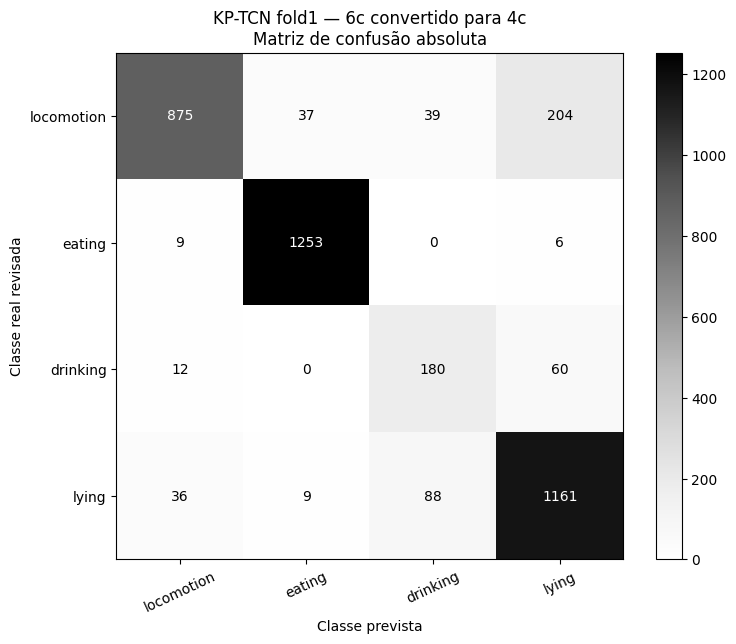

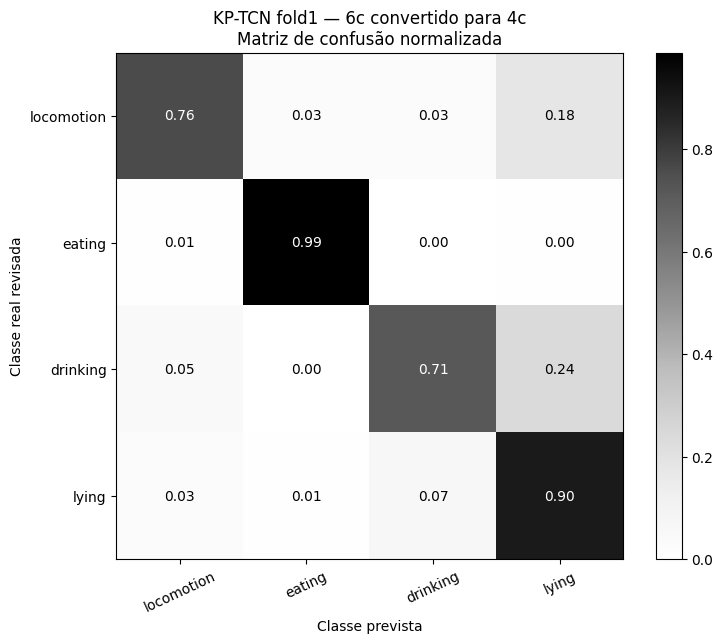


AVALIAÇÃO KP-TCN 6c -> 4c CONCLUÍDA


,instancias,accuracy_6c,macro_f1_6c,accuracy_4c,macro_f1_4c,acertos_recuperados
0,3969,0.772,0.7244,0.874,0.8277,405



Resultados salvos em:
F:\Doutorado\anotador_suinos\Anotações\consolidadas unificado3\anotacoes_suinos_20261110_211312\reavaliacao_KPTCN_fold1_6c_convertido_4c


In [33]:

# ================================================================
# REAVALIAÇÃO KP-TCN FOLD1 — 6 CLASSES CONVERTIDO PARA 4
#
# Mesmo modelo 6c, mesmas previsões, novos rótulos agrupados.
# Dataset atualizado: 414 clipes, 3969 instâncias avaliáveis.
#
# Não executa nova inferência e não altera os dados originais.
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ================================================================
# 1. CAMINHOS
# ================================================================

BASE = Path(
    r"F:\Doutorado\anotador_suinos\Anotações"
    r"\consolidadas unificado3"
    r"\anotacoes_suinos_20261110_211312"
)

# Predições da reavaliação KP-TCN 6c FOLD1
ARQUIVO_6C = (
    BASE
    / "reavaliacao_KPTCN_fold1_6classes"
    / "predicoes_por_animal.csv"
)

# Nova pasta exclusiva para o experimento 6c -> 4c
SAIDA = (
    BASE / "reavaliacao_KPTCN_fold1_6c_convertido_4c"
)

if not ARQUIVO_6C.is_file():
    raise FileNotFoundError(
        "Não foi encontrado o CSV atualizado do "
        "KP-TCN fold1 de 6 classes:\n"
        f"{ARQUIVO_6C}\n"
        "Confira a pasta da reavaliação de 6 classes."
    )

# ================================================================
# 2. CLASSES E MAPA DE AGRUPAMENTO
# ================================================================

CLASSES_6C = [
    "walking",
    "running",
    "eating",
    "drinking",
    "lying awake",
    "sleeping"
]

CLASSES_4C = [
    "locomotion",
    "eating",
    "drinking",
    "lying"
]

MAPA = {
    "walking": "locomotion",
    "running": "locomotion",
    "eating": "eating",
    "drinking": "drinking",
    "lying awake": "lying",
    "sleeping": "lying"
}

# ================================================================
# 3. LER E VALIDAR PREDIÇÕES DO KP-TCN
# ================================================================

df = pd.read_csv(ARQUIVO_6C)

colunas_obrigatorias = [
    "arquivo",
    "track_id",
    "classe_real",
    "classe_prevista"
]

faltantes = [
    c for c in colunas_obrigatorias
    if c not in df.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

if len(df) != 3969:
    raise ValueError(
        f"CSV contém {len(df)} instâncias, "
        "mas o conjunto atualizado deve possuir 3969. "
        "Verifique se utilizou a avaliação mais recente."
    )

if df.duplicated(["arquivo", "track_id"]).any():
    raise ValueError(
        "Existem instâncias duplicadas no CSV."
    )

for coluna in ["classe_real", "classe_prevista"]:

    df[coluna] = df[coluna].replace({
        "lying": "lying awake"
    })

    invalidas = (
        set(df[coluna].dropna()) - set(CLASSES_6C)
    )

    if invalidas or df[coluna].isna().any():
        raise ValueError(
            f"Rótulos inválidos em {coluna}: {invalidas}"
        )

# ================================================================
# 4. AGRUPAR CLASSES
# ================================================================

df["classe_real_4c"] = (
    df["classe_real"].map(MAPA)
)

df["classe_prevista_4c"] = (
    df["classe_prevista"].map(MAPA)
)

y6_real = df["classe_real"].to_numpy()
y6_pred = df["classe_prevista"].to_numpy()

y4_real = df["classe_real_4c"].to_numpy()
y4_pred = df["classe_prevista_4c"].to_numpy()

# ================================================================
# 5. MÉTRICAS ORIGINAIS E AGRUPADAS
# ================================================================

acc6 = accuracy_score(y6_real, y6_pred)
acc4 = accuracy_score(y4_real, y4_pred)

p6, r6, f6, s6 = precision_recall_fscore_support(
    y6_real,
    y6_pred,
    labels=CLASSES_6C,
    zero_division=0
)

p4, r4, f4, suporte4 = (
    precision_recall_fscore_support(
        y4_real,
        y4_pred,
        labels=CLASSES_4C,
        zero_division=0
    )
)

macro_f1_6c = float(np.mean(f6))
macro_f1_4c = float(np.mean(f4))

if acc4 + 1e-12 < acc6:
    raise AssertionError(
        "O agrupamento não pode diminuir a acurácia."
    )

print("=" * 72)
print("KP-TCN FOLD1 — 6 CLASSES CONVERTIDO PARA 4")
print("=" * 72)

print("Instâncias avaliadas:", len(df))

print("\nRESULTADOS ORIGINAIS — 6 CLASSES")
print(f"Accuracy:  {acc6:.4f}")
print(f"Macro-F1:  {macro_f1_6c:.4f}")

print("\nRESULTADOS AGRUPADOS — 4 CLASSES")
print(f"Accuracy:         {acc4:.4f}")
print(f"Macro-Precision:  {np.mean(p4):.4f}")
print(f"Macro-Recall:     {np.mean(r4):.4f}")
print(f"Macro-F1:         {macro_f1_4c:.4f}")

print("\nDIFERENÇAS")
print(
    "Accuracy:",
    f"{(acc4 - acc6)*100:+.2f} pontos percentuais"
)
print(
    "Macro-F1:",
    f"{(macro_f1_4c - macro_f1_6c)*100:+.2f} pontos percentuais"
)

# ================================================================
# 6. MÉTRICAS POR CLASSE
# ================================================================

relatorio = pd.DataFrame({
    "classe": CLASSES_4C,
    "precision": p4,
    "recall": r4,
    "f1": f4,
    "suporte": suporte4
})

print("\nF1 POR CLASSE — KP-TCN 6c -> 4c")
display(relatorio.round(4))

print("\nRELATÓRIO COMPLETO")
print(
    classification_report(
        y4_real,
        y4_pred,
        labels=CLASSES_4C,
        digits=4,
        zero_division=0
    )
)

# ================================================================
# 7. ERROS QUE SE TORNARAM ACERTOS
# ================================================================

correto6 = y6_real == y6_pred
correto4 = y4_real == y4_pred

recuperados = (~correto6) & correto4

total_recuperados = int(
    recuperados.sum()
)

print("\n" + "=" * 72)
print("ACERTOS RECUPERADOS PELO AGRUPAMENTO")
print("=" * 72)

print(
    "Instâncias recuperadas:",
    total_recuperados
)

print("\nConfusões originais recuperadas:")

tabela_recuperadas = pd.crosstab(
    pd.Series(
        y6_real[recuperados],
        name="Classe real 6c"
    ),
    pd.Series(
        y6_pred[recuperados],
        name="Classe prevista 6c"
    )
)

display(tabela_recuperadas)

# ================================================================
# 8. MATRIZES DE CONFUSÃO
# ================================================================

SAIDA.mkdir(
    parents=True,
    exist_ok=True
)

cm = confusion_matrix(
    y4_real,
    y4_pred,
    labels=CLASSES_4C
)

cm_norm = confusion_matrix(
    y4_real,
    y4_pred,
    labels=CLASSES_4C,
    normalize="true"
)

for nome, matriz, formato in [
    ("absoluta", cm, "d"),
    ("normalizada", cm_norm, ".2f")
]:

    fig, ax = plt.subplots(
        figsize=(8, 6.5)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASSES_4C
    )

    disp.plot(
        ax=ax,
        cmap="Greys",
        values_format=formato,
        xticks_rotation=25,
        colorbar=True
    )

    ax.set_title(
        "KP-TCN fold1 — 6c convertido para 4c\n"
        f"Matriz de confusão {nome}"
    )

    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real revisada")

    fig.tight_layout()

    fig.savefig(
        SAIDA / f"matriz_confusao_{nome}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    pd.DataFrame(
        matriz,
        index=CLASSES_4C,
        columns=CLASSES_4C
    ).to_csv(
        SAIDA / f"matriz_confusao_{nome}.csv",
        encoding="utf-8-sig"
    )

# ================================================================
# 9. EXPORTAR RESULTADOS
# ================================================================

relatorio.to_csv(
    SAIDA / "metricas_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

df["correto_6c"] = correto6
df["correto_4c"] = correto4
df["acerto_recuperado"] = recuperados

df.to_csv(
    SAIDA / "predicoes_6c_agrupadas_4c.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo = pd.DataFrame([{
    "modelo": "KP-TCN fold1 6c convertido para 4c",
    "instancias": len(df),
    "accuracy_6c": acc6,
    "macro_f1_6c": macro_f1_6c,
    "accuracy_4c": acc4,
    "macro_precision_4c": float(np.mean(p4)),
    "macro_recall_4c": float(np.mean(r4)),
    "macro_f1_4c": macro_f1_4c,
    "acertos_recuperados": total_recuperados
}])

resumo.to_csv(
    SAIDA / "metricas_globais.csv",
    index=False,
    encoding="utf-8-sig"
)

# ================================================================
# 10. RESUMO FINAL
# ================================================================

print("\n" + "=" * 72)
print("AVALIAÇÃO KP-TCN 6c -> 4c CONCLUÍDA")
print("=" * 72)

display(
    resumo[[
        "instancias",
        "accuracy_6c",
        "macro_f1_6c",
        "accuracy_4c",
        "macro_f1_4c",
        "acertos_recuperados"
    ]].round(4)
)

print("\nResultados salvos em:")
print(SAIDA)


# Preparação Slow fast e vitam Slow Fast

### Step 24 — SlowFast RGB baseline — six classes

**Purpose.** Loads the published SlowFast R50 checkpoint and the RGB animal crops, resamples 15 source frames into slow/fast pathways, and evaluates six classes plus aggregated four-class predictions.

**Inputs and dependencies.** Precomputed 224×224 RGB crops, the final six-class CSV, PyTorchVideo and original fold3 weights.

**Expected outputs.** Six-class and six-to-four-class evaluation reports, probability CSVs and grayscale confusion matrices.

**Reproducibility and interpretation.** RGB inputs retain visual texture and coat color; use original normalization and temporal sampling. GPU memory constraints may require batch size 1.



Mapa de classes conferido: {'walking': 0, 'running': 1, 'eating': 2, 'drinking': 3, 'lying awake': 4, 'sleeping': 5}
Checkpoint do artigo: F:\slowfast_dataset_degcn_aligned_5300xml\slowfast_runs_5fold\fold3\best.pt
Dispositivo: cuda
Instâncias: 3969 | distribuição: {'eating': 1268, 'walking': 885, 'sleeping': 654, 'lying awake': 640, 'running': 270, 'drinking': 252}
SlowFast carregado com strict=True
Inferência: 250/3969
Inferência: 500/3969
Inferência: 750/3969
Inferência: 1000/3969
Inferência: 1250/3969
Inferência: 1500/3969
Inferência: 1750/3969
Inferência: 2000/3969
Inferência: 2250/3969
Inferência: 2500/3969
Inferência: 2750/3969
Inferência: 3000/3969
Inferência: 3250/3969
Inferência: 3500/3969
Inferência: 3750/3969
Inferência: 3969/3969

SlowFast artigo — fold3 — 6 classes
Accuracy=0.5586 | Macro-Precision=0.5960 | Macro-Recall=0.4629 | Macro-F1=0.4554
              precision    recall  f1-score   support

     walking     0.6054    0.3537    0.4465       885
     running     0.7

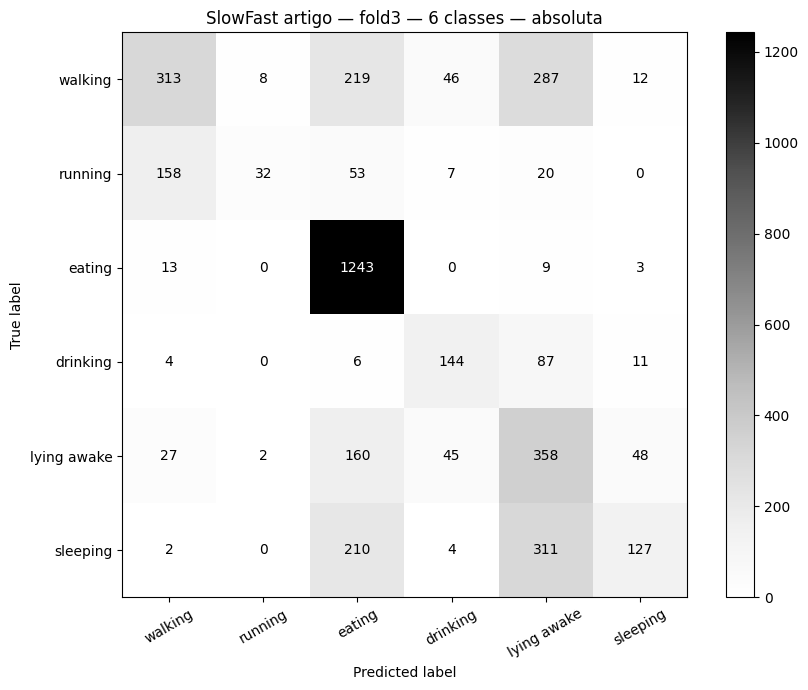

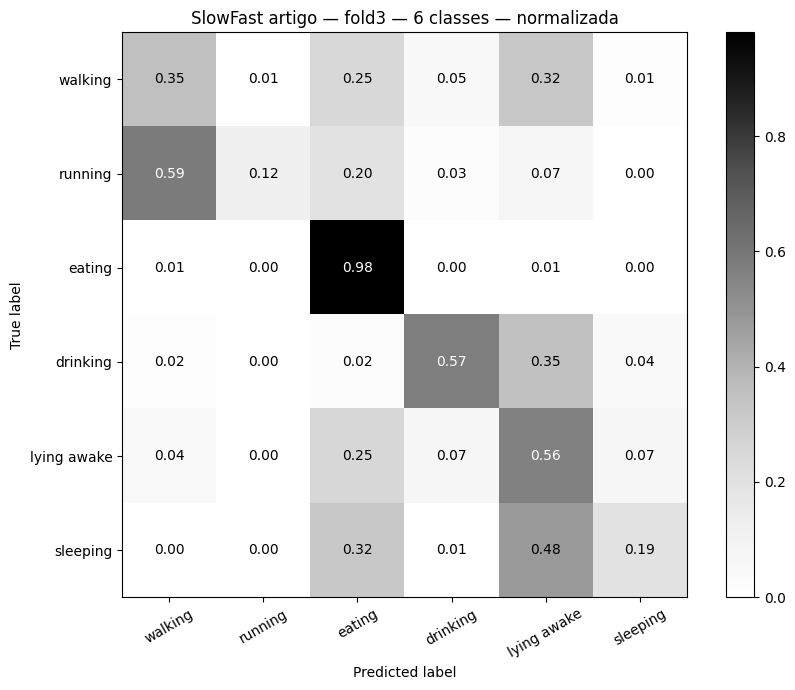


SlowFast artigo — fold3 — 6c agrupado em 4c
Accuracy=0.6909 | Macro-Precision=0.7050 | Macro-Recall=0.6616 | Macro-F1=0.6548
              precision    recall  f1-score   support

  locomotion     0.9141    0.4424    0.5963      1155
      eating     0.6573    0.9803    0.7870      1268
    drinking     0.5854    0.5714    0.5783       252
       lying     0.6630    0.6522    0.6576      1294

    accuracy                         0.6909      3969
   macro avg     0.7050    0.6616    0.6548      3969
weighted avg     0.7293    0.6909    0.6760      3969

    classe  precision   recall       f1  suporte
locomotion   0.914132 0.442424 0.596266     1155
    eating   0.657324 0.980284 0.786958     1268
  drinking   0.585366 0.571429 0.578313      252
     lying   0.663001 0.652241 0.657577     1294


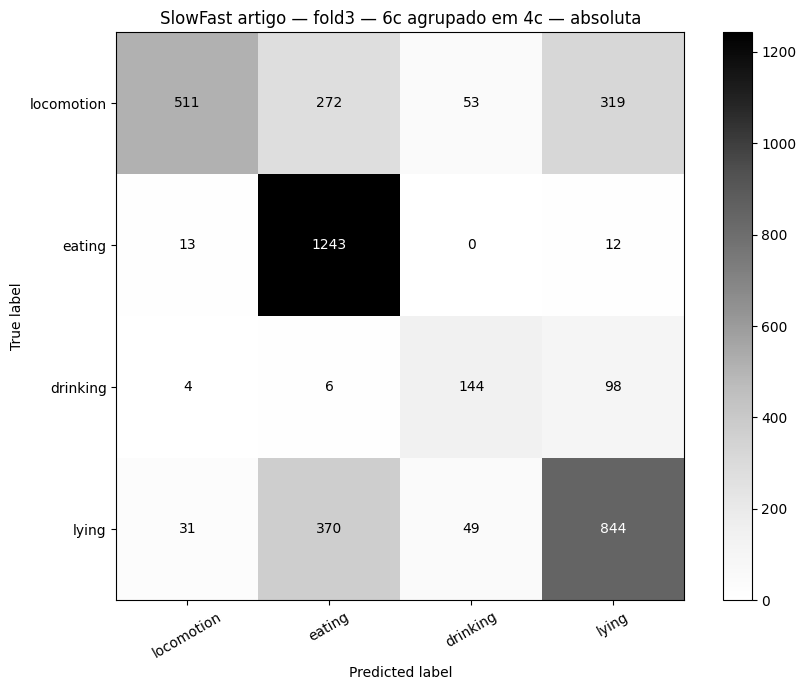

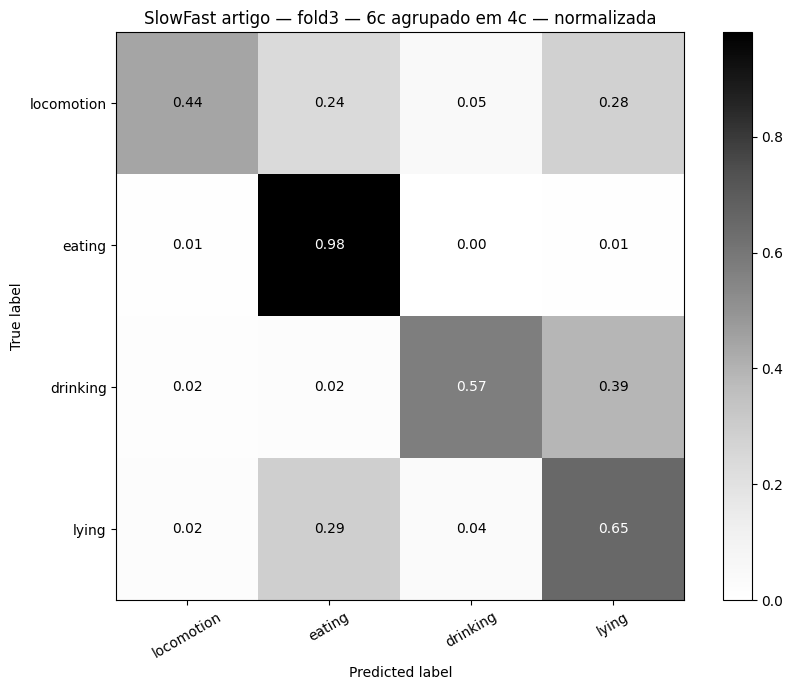

Acertos recuperados por agrupamento: 525

Avaliação concluída. Resultados em: F:\Doutorado\anotador_suinos\datasets_avaliacao\rgb_unificados3_20261110\avaliacao_SlowFast_artigo_6c_fold3


In [18]:
# ================================================================
# SlowFast 6c — experimento do ARTIGO, fold3 — teste independente
# Fonte da arquitetura e do pré-processamento: SlowFast(2).ipynb
# Não treina nem altera o checkpoint original.
# ================================================================
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, classification_report,
                             precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay)

from pytorchvideo.models.hub import slowfast_r50

ROOT = Path(r"F:\slowfast_dataset_degcn_aligned_5300xml")
DATASET_ROOT = Path(r"F:\Doutorado\anotador_suinos\datasets_avaliacao\rgb_unificados3_20261110")
CSV = DATASET_ROOT / "teste_rgb_6classes.csv"
CLASS_MAP_DATASET = DATASET_ROOT / "labels_map_6classes.json"
EXPERIMENT_ROOT = ROOT / "slowfast_runs_5fold"
CLASS_NAMES_TREINO = EXPERIMENT_ROOT / "class_names.json"
CHECKPOINT_ORIGINAL = EXPERIMENT_ROOT / "fold3" / "best.pt"
CHECKPOINT_COPIA = Path(r"F:\Doutorado\anotador_suinos\modelos\melhores_modelos\SlowFast_6classes\slowfast_6classes_fold3_artigo.pt")
SAIDA = DATASET_ROOT / "avaliacao_SlowFast_artigo_6c_fold3"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 1  # adequado para GPU com 8 GB; aumente apenas se houver memória
NUM_WORKERS = 0  # Windows / Jupyter
IMG_SIZE, SRC_FRAMES, FAST_FRAMES, SLOW_FRAMES = 224, 15, 32, 8
CLASSES_6 = ["walking", "running", "eating", "drinking", "lying awake", "sleeping"]
CLASSES_4 = ["locomotion", "eating", "drinking", "lying"]
MAPA_4 = {"walking":"locomotion", "running":"locomotion",
          "eating":"eating", "drinking":"drinking",
          "lying awake":"lying", "sleeping":"lying"}

for arquivo in [CSV, CLASS_MAP_DATASET, CLASS_NAMES_TREINO, CHECKPOINT_ORIGINAL]:
    if not arquivo.is_file():
        raise FileNotFoundError(arquivo)
checkpoint = CHECKPOINT_COPIA if CHECKPOINT_COPIA.is_file() else CHECKPOINT_ORIGINAL

def hash_file(p):
    h = hashlib.sha256()
    with p.open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()
if checkpoint != CHECKPOINT_ORIGINAL and hash_file(checkpoint) != hash_file(CHECKPOINT_ORIGINAL):
    raise ValueError("A cópia do checkpoint não coincide com o fold3 do artigo")

with CLASS_MAP_DATASET.open(encoding="utf-8") as f:
    dmap = json.load(f)
with CLASS_NAMES_TREINO.open(encoding="utf-8") as f:
    tmap = json.load(f)

def to_class_to_idx(obj):
    if "class_to_idx" in obj:
        return {str(k):int(v) for k,v in obj["class_to_idx"].items()}
    if "idx_to_class" in obj:
        return {str(v):int(k) for k,v in obj["idx_to_class"].items()}
    if all(str(k).isdigit() for k in obj):
        return {str(v):int(k) for k,v in obj.items()}
    return {str(k):int(v) for k,v in obj.items()}

mapa_dados, mapa_treino = to_class_to_idx(dmap), to_class_to_idx(tmap)
if mapa_treino != mapa_dados:
    raise ValueError(f"Mapa de classes incompatível!\nTreino={mapa_treino}\nTeste={mapa_dados}")
if set(mapa_treino) != set(CLASSES_6) or set(mapa_treino.values()) != set(range(6)):
    raise ValueError(f"Mapa de classes inesperado: {mapa_treino}")
nomes_indice = [next(n for n,i in mapa_treino.items() if i == k) for k in range(6)]
print("Mapa de classes conferido:", mapa_treino)
print("Checkpoint do artigo:", checkpoint)
print("Dispositivo:", DEVICE)

class TestSlowFastDataset(Dataset):
    def __init__(self, csv):
        self.df = pd.read_csv(csv, encoding="utf-8-sig").reset_index(drop=True)
        self.fast_idx = np.linspace(0, SRC_FRAMES-1, FAST_FRAMES).round().astype(int)
        self.slow_idx = np.linspace(0, FAST_FRAMES-1, SLOW_FRAMES).round().astype(int)
        required = {"clip_dir", "label_idx", "label_name", "arquivo", "track_id"}
        if missing := required.difference(self.df.columns):
            raise ValueError(f"Colunas ausentes no CSV: {missing}")
        if len(self.df) != 3969:
            raise ValueError(f"Esperadas 3969 instâncias atualizadas; encontradas {len(self.df)}")
        if self.df.duplicated(["arquivo", "track_id"]).any():
            raise ValueError("Há instâncias duplicadas por arquivo/track_id")
        for row in self.df.itertuples():
            if row.label_name not in mapa_treino or int(row.label_idx) != mapa_treino[row.label_name]:
                raise ValueError(f"Rótulo divergente no CSV: {row.label_name}, {row.label_idx}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        clip_dir = Path(row["clip_dir"])
        frames=[]
        for t in range(SRC_FRAMES):
            p = clip_dir / f"img_{t:03d}.jpg"
            img = cv2.imread(str(p), cv2.IMREAD_COLOR)
            if img is None:
                raise FileNotFoundError(f"Imagem ausente/ilegível: {p}")
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            if img.shape[:2] != (IMG_SIZE, IMG_SIZE):
                img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
            img = img.astype(np.float32)/255.0
            img = (img - 0.45)/0.225
            frames.append(img.transpose(2, 0, 1))
        src_clip = np.stack(frames)
        fast = src_clip[self.fast_idx].transpose(1,0,2,3).copy()
        slow = fast[:,self.slow_idx,:,:].copy()
        return [torch.from_numpy(slow), torch.from_numpy(fast)], int(row["label_idx"]), idx

def collate(batch):
    slow = torch.stack([v[0][0] for v in batch])
    fast = torch.stack([v[0][1] for v in batch])
    y = torch.tensor([v[1] for v in batch], dtype=torch.long)
    ids = [v[2] for v in batch]
    return [slow,fast],y,ids

ds=TestSlowFastDataset(CSV)
dl=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,
              pin_memory=DEVICE.type=="cuda",collate_fn=collate)
print("Instâncias:",len(ds), "| distribuição:",ds.df.label_name.value_counts().to_dict())

model = slowfast_r50(pretrained=False)
in_features = model.blocks[-1].proj.in_features
model.blocks[-1].proj = nn.Linear(in_features,6)
raw = torch.load(checkpoint,map_location="cpu",weights_only=True)
if not isinstance(raw,dict):
    raise TypeError(f"Checkpoint inesperado: {type(raw)}")
if all(isinstance(v,torch.Tensor) for v in raw.values()):
    state = raw
else:
    state = raw.get("model_state_dict",raw.get("state_dict",raw.get("model")))
    if not isinstance(state,dict):
        raise ValueError(f"Checkpoint sem state_dict: {list(raw)[:20]}")
model.load_state_dict(state,strict=True)
model.to(DEVICE).eval()
print("SlowFast carregado com strict=True")

predicoes=[]
probabilidades=[]
indices=[]
with torch.inference_mode():
    for batch_idx,(x,y,idxs) in enumerate(dl,1):
        x=[t.to(DEVICE,non_blocking=True) for t in x]
        logits = model(x)
        if tuple(logits.shape) != (len(idxs),6):
            raise RuntimeError(f"Saída inesperada: {tuple(logits.shape)}")
        prob = torch.softmax(logits,dim=1).cpu().numpy()
        probabilidades.append(prob)
        predicoes.extend(prob.argmax(1).tolist())
        indices.extend(idxs)
        if batch_idx % 250 == 0 or batch_idx == len(dl):
            print(f"Inferência: {len(indices)}/{len(ds)}")

probs=np.concatenate(probabilidades)
yp=np.asarray(predicoes,dtype=int)
if indices != list(range(len(ds))):
    raise RuntimeError("Ordem das amostras alterada na inferência")
yt=ds.df.label_idx.to_numpy(dtype=int)

SAIDA.mkdir(parents=True,exist_ok=True)
pred_df=ds.df[["arquivo","track_id","clip_name","clip_dir","label_name","label_idx"]].copy()
pred_df=pred_df.rename(columns={"label_name":"classe_real", "label_idx":"indice_real"})
pred_df["indice_previsto"]=yp
pred_df["classe_prevista"]=[nomes_indice[i] for i in yp]
pred_df["correto_6c"]=yt==yp
pred_df["confianca_6c"]=probs.max(1)
for k,name in enumerate(nomes_indice):
    pred_df["prob_"+name.replace(" ","_")]=probs[:,k]


def avaliar(y_real,y_prev,classes,nome,prefix):
    p,r,f,s=precision_recall_fscore_support(y_real,y_prev,labels=classes,zero_division=0)
    acc=accuracy_score(y_real,y_prev)
    print("\n"+"="*68+f"\n{nome}\n"+"="*68)
    print(f"Accuracy={acc:.4f} | Macro-Precision={p.mean():.4f} | Macro-Recall={r.mean():.4f} | Macro-F1={f.mean():.4f}")
    print(classification_report(y_real,y_prev,labels=classes,zero_division=0,digits=4))
    class_df=pd.DataFrame({"classe":classes,"precision":p,"recall":r,"f1":f,"suporte":s})
    display(class_df.round(4)) if "display" in globals() else print(class_df.to_string(index=False))
    class_df.to_csv(SAIDA/f"{prefix}_metricas_por_classe.csv",index=False,encoding="utf-8-sig")
    for tipo,normalizacao,fmt in [("absoluta",None,"d"),("normalizada","true",".2f")]:
        cm=confusion_matrix(y_real,y_prev,labels=classes,normalize=normalizacao)
        pd.DataFrame(cm,index=classes,columns=classes).to_csv(
            SAIDA/f"{prefix}_matriz_{tipo}.csv",encoding="utf-8-sig")
        fig,ax=plt.subplots(figsize=(9,7))
        disp=ConfusionMatrixDisplay(cm,display_labels=classes)
        disp.plot(ax=ax,cmap="Greys",values_format=fmt,xticks_rotation=30,colorbar=True)
        ax.set_title(f"{nome} — {tipo}")
        fig.tight_layout()
        fig.savefig(SAIDA/f"{prefix}_matriz_{tipo}.png",dpi=300,bbox_inches="tight")
        plt.show()
        plt.close(fig)
    return {"modelo":nome,"n":len(y_real),"accuracy":acc,"macro_precision":float(p.mean()),
            "macro_recall":float(r.mean()),"macro_f1":float(f.mean())}

res6=avaliar(pred_df.classe_real,pred_df.classe_prevista,CLASSES_6,
             "SlowFast artigo — fold3 — 6 classes", "6c")
pred_df["classe_real_4c"]=pred_df.classe_real.map(MAPA_4)
pred_df["classe_prevista_4c"]=pred_df.classe_prevista.map(MAPA_4)
pred_df["correto_4c"]=pred_df.classe_real_4c==pred_df.classe_prevista_4c
res4=avaliar(pred_df.classe_real_4c,pred_df.classe_prevista_4c,CLASSES_4,
             "SlowFast artigo — fold3 — 6c agrupado em 4c", "6c_para_4c")
if res4["accuracy"]+1e-12<res6["accuracy"]:
    raise AssertionError("Agrupamento não pode diminuir a acurácia")
print("Acertos recuperados por agrupamento:",int((~pred_df.correto_6c & pred_df.correto_4c).sum()))
pred_df.to_csv(SAIDA/"predicoes_por_animal.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([res6,res4]).to_csv(SAIDA/"metricas_globais.csv",index=False,encoding="utf-8-sig")
with (SAIDA/"protocolo.json").open("w",encoding="utf-8") as f:
    json.dump({"checkpoint":str(checkpoint),"checkpoint_sha256":hash_file(checkpoint),
               "dataset":str(CSV),"dataset_sha256":hash_file(CSV),
               "familia_experimento":"slowfast_runs_5fold (reproduz artigo)","fold":3,
               "img_size":IMG_SIZE,"source_frames":SRC_FRAMES,
               "fast_frames":FAST_FRAMES,"slow_frames":SLOW_FRAMES,
               "normalizacao":{"mean":[0.45]*3,"std":[0.225]*3},
               "class_to_idx":mapa_treino,"n":len(ds)},f,ensure_ascii=False,indent=2)
print("\nAvaliação concluída. Resultados em:",SAIDA)


### Step 26 — SlowFast RGB baseline — directly trained four classes

**Purpose.** Evaluates the separately trained four-class SlowFast R50 checkpoint using the same independent animal-crop instances.

**Inputs and dependencies.** RGB test CSV with four-class indices, original training class names and fold3 weights.

**Expected outputs.** Direct four-class performance summary, predicted probabilities and confusion matrices.

**Reproducibility and interpretation.** This run is distinct from six-to-four grouping; verify that its original training lineage is the one intended for manuscript comparison.



Mapa de classes conferido: {'deslocando': 0, 'eating': 1, 'drinking': 2, 'deitado': 3}
Checkpoint do artigo: F:\Doutorado\anotador_suinos\modelos\melhores_modelos\SlowFast_4classes\slowfast_4classes_fold3.pt
Dispositivo: cuda
Instâncias: 3969 | distribuição: {'deitado': 1294, 'eating': 1268, 'deslocando': 1155, 'drinking': 252}
SlowFast carregado com strict=True
Inferência: 250/3969
Inferência: 500/3969
Inferência: 750/3969
Inferência: 1000/3969
Inferência: 1250/3969
Inferência: 1500/3969
Inferência: 1750/3969
Inferência: 2000/3969
Inferência: 2250/3969
Inferência: 2500/3969
Inferência: 2750/3969
Inferência: 3000/3969
Inferência: 3250/3969
Inferência: 3500/3969
Inferência: 3750/3969
Inferência: 3969/3969

SlowFast 4 classes — fold3 — teste revisado
Accuracy=0.8284 | Macro-Precision=0.7788 | Macro-Recall=0.7846 | Macro-F1=0.7798
              precision    recall  f1-score   support

  locomotion     0.8457    0.7688    0.8054      1155
      eating     0.8531    0.9756    0.9102      12

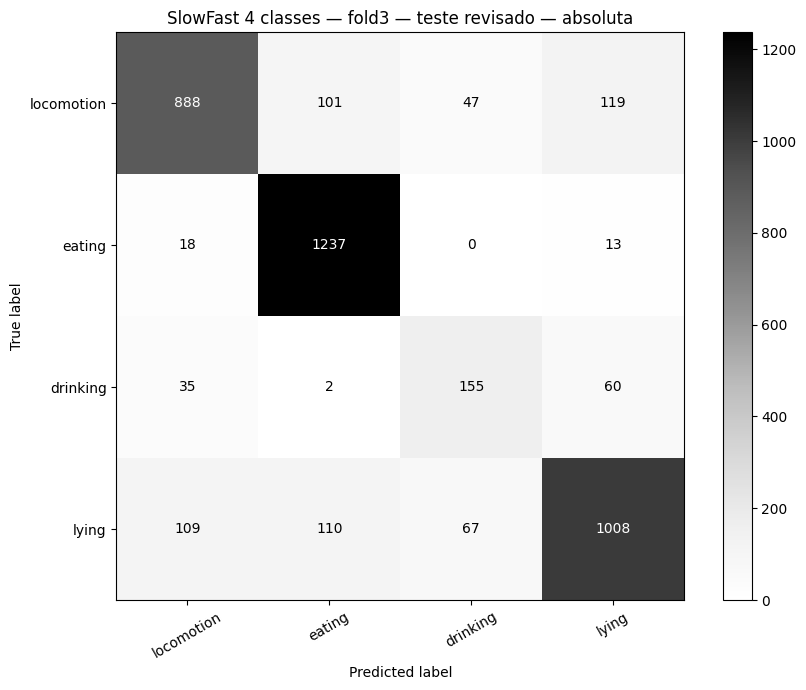

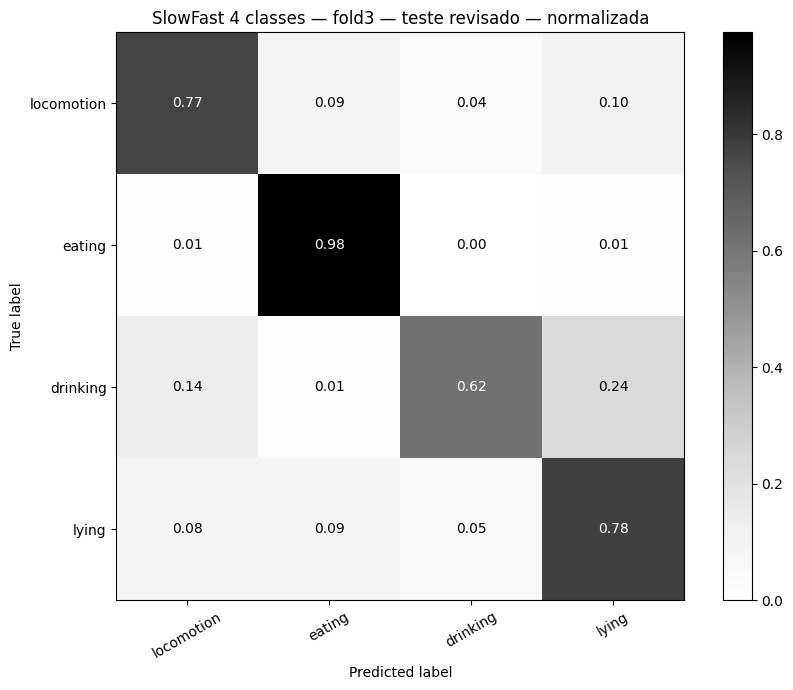


Avaliação concluída. Resultados em: F:\Doutorado\anotador_suinos\datasets_avaliacao\rgb_unificados3_20261110\avaliacao_SlowFast_4c_fold3


In [23]:
# ================================================================
# SlowFast 4c — fold3 — teste independente (treinado diretamente em 4 classes)
# Fonte da arquitetura e do pré-processamento: SlowFast(2).ipynb
# Não treina nem altera o checkpoint original.
# ================================================================
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, classification_report,
                             precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay)

from pytorchvideo.models.hub import slowfast_r50

ROOT = Path(r"F:\slowfast_dataset_degcn_aligned_5300xml")
DATASET_ROOT = Path(r"F:\Doutorado\anotador_suinos\datasets_avaliacao\rgb_unificados3_20261110")
CSV = DATASET_ROOT / "teste_rgb_4classes.csv"
CLASS_MAP_DATASET = DATASET_ROOT / "labels_map_4classes.json"
EXPERIMENT_ROOT = ROOT / "merged_4classes" / "slowfast_runs_4cls_5fold"
CLASS_NAMES_TREINO = EXPERIMENT_ROOT / "class_names.json"
CHECKPOINT_ORIGINAL = EXPERIMENT_ROOT / "fold3" / "best.pt"
CHECKPOINT_COPIA = Path(r"F:\Doutorado\anotador_suinos\modelos\melhores_modelos\SlowFast_4classes\slowfast_4classes_fold3.pt")
SAIDA = DATASET_ROOT / "avaliacao_SlowFast_4c_fold3"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 1  # adequado para GPU com 8 GB; aumente apenas se houver memória
NUM_WORKERS = 0  # Windows / Jupyter
IMG_SIZE, SRC_FRAMES, FAST_FRAMES, SLOW_FRAMES = 224, 15, 32, 8
CLASSES_4_TREINO = ["deslocando", "eating", "drinking", "deitado"]
CLASSES_4_DISPLAY = ["locomotion", "eating", "drinking", "lying"]

for arquivo in [CSV, CLASS_MAP_DATASET, CLASS_NAMES_TREINO, CHECKPOINT_ORIGINAL]:
    if not arquivo.is_file():
        raise FileNotFoundError(arquivo)
checkpoint = CHECKPOINT_COPIA if CHECKPOINT_COPIA.is_file() else CHECKPOINT_ORIGINAL

def hash_file(p):
    h = hashlib.sha256()
    with p.open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()
if checkpoint != CHECKPOINT_ORIGINAL and hash_file(checkpoint) != hash_file(CHECKPOINT_ORIGINAL):
    raise ValueError("A cópia do checkpoint não coincide com o fold3 da execução 4 classes")

with CLASS_MAP_DATASET.open(encoding="utf-8") as f:
    dmap = json.load(f)
with CLASS_NAMES_TREINO.open(encoding="utf-8") as f:
    tmap = json.load(f)

def to_class_to_idx(obj):
    if "class_to_idx" in obj:
        return {str(k):int(v) for k,v in obj["class_to_idx"].items()}
    if "idx_to_class" in obj:
        return {str(v):int(k) for k,v in obj["idx_to_class"].items()}
    if all(str(k).isdigit() for k in obj):
        return {str(v):int(k) for k,v in obj.items()}
    return {str(k):int(v) for k,v in obj.items()}

mapa_dados, mapa_treino = to_class_to_idx(dmap), to_class_to_idx(tmap)
if mapa_treino != mapa_dados:
    raise ValueError(f"Mapa de classes incompatível!\nTreino={mapa_treino}\nTeste={mapa_dados}")
if set(mapa_treino) != set(CLASSES_4_TREINO) or set(mapa_treino.values()) != set(range(4)):
    raise ValueError(f"Mapa de classes inesperado: {mapa_treino}")
nomes_indice = [next(n for n,i in mapa_treino.items() if i == k) for k in range(4)]
if nomes_indice != CLASSES_4_TREINO:
    raise ValueError(f"Ordem inesperada no treinamento: {nomes_indice}")
print("Mapa de classes conferido:", mapa_treino)
print("Checkpoint do artigo:", checkpoint)
print("Dispositivo:", DEVICE)

class TestSlowFastDataset(Dataset):
    def __init__(self, csv):
        self.df = pd.read_csv(csv, encoding="utf-8-sig").reset_index(drop=True)
        self.fast_idx = np.linspace(0, SRC_FRAMES-1, FAST_FRAMES).round().astype(int)
        self.slow_idx = np.linspace(0, FAST_FRAMES-1, SLOW_FRAMES).round().astype(int)
        required = {"clip_dir", "label_idx", "label_name", "arquivo", "track_id"}
        if missing := required.difference(self.df.columns):
            raise ValueError(f"Colunas ausentes no CSV: {missing}")
        if len(self.df) != 3969:
            raise ValueError(f"Esperadas 3969 instâncias atualizadas; encontradas {len(self.df)}")
        if self.df.duplicated(["arquivo", "track_id"]).any():
            raise ValueError("Há instâncias duplicadas por arquivo/track_id")
        for row in self.df.itertuples():
            if row.label_name not in mapa_treino or int(row.label_idx) != mapa_treino[row.label_name]:
                raise ValueError(f"Rótulo divergente no CSV: {row.label_name}, {row.label_idx}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        clip_dir = Path(row["clip_dir"])
        frames=[]
        for t in range(SRC_FRAMES):
            p = clip_dir / f"img_{t:03d}.jpg"
            img = cv2.imread(str(p), cv2.IMREAD_COLOR)
            if img is None:
                raise FileNotFoundError(f"Imagem ausente/ilegível: {p}")
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            if img.shape[:2] != (IMG_SIZE, IMG_SIZE):
                img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
            img = img.astype(np.float32)/255.0
            img = (img - 0.45)/0.225
            frames.append(img.transpose(2, 0, 1))
        src_clip = np.stack(frames)
        fast = src_clip[self.fast_idx].transpose(1,0,2,3).copy()
        slow = fast[:,self.slow_idx,:,:].copy()
        return [torch.from_numpy(slow), torch.from_numpy(fast)], int(row["label_idx"]), idx

def collate(batch):
    slow = torch.stack([v[0][0] for v in batch])
    fast = torch.stack([v[0][1] for v in batch])
    y = torch.tensor([v[1] for v in batch], dtype=torch.long)
    ids = [v[2] for v in batch]
    return [slow,fast],y,ids

ds=TestSlowFastDataset(CSV)
dl=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,
              pin_memory=DEVICE.type=="cuda",collate_fn=collate)
print("Instâncias:",len(ds), "| distribuição:",ds.df.label_name.value_counts().to_dict())

model = slowfast_r50(pretrained=False)
in_features = model.blocks[-1].proj.in_features
model.blocks[-1].proj = nn.Linear(in_features,4)
raw = torch.load(checkpoint,map_location="cpu",weights_only=True)
if not isinstance(raw,dict):
    raise TypeError(f"Checkpoint inesperado: {type(raw)}")
if all(isinstance(v,torch.Tensor) for v in raw.values()):
    state = raw
else:
    state = raw.get("model_state_dict",raw.get("state_dict",raw.get("model")))
    if not isinstance(state,dict):
        raise ValueError(f"Checkpoint sem state_dict: {list(raw)[:20]}")
model.load_state_dict(state,strict=True)
model.to(DEVICE).eval()
print("SlowFast carregado com strict=True")

predicoes=[]
probabilidades=[]
indices=[]
with torch.inference_mode():
    for batch_idx,(x,y,idxs) in enumerate(dl,1):
        x=[t.to(DEVICE,non_blocking=True) for t in x]
        logits = model(x)
        if tuple(logits.shape) != (len(idxs),4):
            raise RuntimeError(f"Saída inesperada: {tuple(logits.shape)}")
        prob = torch.softmax(logits,dim=1).cpu().numpy()
        probabilidades.append(prob)
        predicoes.extend(prob.argmax(1).tolist())
        indices.extend(idxs)
        if batch_idx % 250 == 0 or batch_idx == len(dl):
            print(f"Inferência: {len(indices)}/{len(ds)}")

probs=np.concatenate(probabilidades)
yp=np.asarray(predicoes,dtype=int)
if indices != list(range(len(ds))):
    raise RuntimeError("Ordem das amostras alterada na inferência")
yt=ds.df.label_idx.to_numpy(dtype=int)

SAIDA.mkdir(parents=True,exist_ok=True)
pred_df=ds.df[["arquivo","track_id","clip_name","clip_dir","label_name","label_idx"]].copy()
pred_df=pred_df.rename(columns={"label_name":"classe_real", "label_idx":"indice_real"})
pred_df["indice_previsto"]=yp
pred_df["classe_prevista"]=[nomes_indice[i] for i in yp]
pred_df["correto_4c"]=yt==yp
pred_df["confianca_4c"]=probs.max(1)
for k,name in enumerate(nomes_indice):
    pred_df["prob_"+name.replace(" ","_")]=probs[:,k]


def avaliar(y_real,y_prev,classes,nome,prefix):
    p,r,f,s=precision_recall_fscore_support(y_real,y_prev,labels=classes,zero_division=0)
    acc=accuracy_score(y_real,y_prev)
    print("\n"+"="*68+f"\n{nome}\n"+"="*68)
    print(f"Accuracy={acc:.4f} | Macro-Precision={p.mean():.4f} | Macro-Recall={r.mean():.4f} | Macro-F1={f.mean():.4f}")
    print(classification_report(y_real,y_prev,labels=classes,zero_division=0,digits=4))
    class_df=pd.DataFrame({"classe":classes,"precision":p,"recall":r,"f1":f,"suporte":s})
    display(class_df.round(4)) if "display" in globals() else print(class_df.to_string(index=False))
    class_df.to_csv(SAIDA/f"{prefix}_metricas_por_classe.csv",index=False,encoding="utf-8-sig")
    for tipo,normalizacao,fmt in [("absoluta",None,"d"),("normalizada","true",".2f")]:
        cm=confusion_matrix(y_real,y_prev,labels=classes,normalize=normalizacao)
        pd.DataFrame(cm,index=classes,columns=classes).to_csv(
            SAIDA/f"{prefix}_matriz_{tipo}.csv",encoding="utf-8-sig")
        fig,ax=plt.subplots(figsize=(9,7))
        disp=ConfusionMatrixDisplay(cm,display_labels=classes)
        disp.plot(ax=ax,cmap="Greys",values_format=fmt,xticks_rotation=30,colorbar=True)
        ax.set_title(f"{nome} — {tipo}")
        fig.tight_layout()
        fig.savefig(SAIDA/f"{prefix}_matriz_{tipo}.png",dpi=300,bbox_inches="tight")
        plt.show()
        plt.close(fig)
    return {"modelo":nome,"n":len(y_real),"accuracy":acc,"macro_precision":float(p.mean()),
            "macro_recall":float(r.mean()),"macro_f1":float(f.mean())}

# Classificador treinado diretamente em 4 classes.
# Converter apenas os nomes da apresentação, nunca os índices!
map_display = dict(zip(CLASSES_4_TREINO, CLASSES_4_DISPLAY))
pred_df["classe_real_ingles"] = pred_df["classe_real"].map(map_display)
pred_df["classe_prevista_ingles"] = pred_df["classe_prevista"].map(map_display)

resultado = avaliar(
    pred_df.classe_real_ingles,
    pred_df.classe_prevista_ingles,
    CLASSES_4_DISPLAY,
    "SlowFast 4 classes — fold3 — teste revisado",
    "4c_direto"
)

pred_df.to_csv(
    SAIDA / "predicoes_por_animal.csv", index=False, encoding="utf-8-sig"
)
pd.DataFrame([resultado]).to_csv(
    SAIDA / "metricas_globais.csv", index=False, encoding="utf-8-sig"
)
with (SAIDA / "protocolo.json").open("w", encoding="utf-8") as f:
    json.dump({
        "checkpoint": str(checkpoint),
        "checkpoint_sha256": hash_file(checkpoint),
        "dataset": str(CSV),
        "dataset_sha256": hash_file(CSV),
        "familia_experimento": "slowfast_runs_4cls_5fold",
        "fold": 3,
        "img_size": IMG_SIZE,
        "source_frames": SRC_FRAMES,
        "fast_frames": FAST_FRAMES,
        "slow_frames": SLOW_FRAMES,
        "normalizacao": {"mean": [0.45]*3, "std": [0.225]*3},
        "class_to_idx": mapa_treino,
        "n": len(ds)
    }, f, ensure_ascii=False, indent=2)
print("\nAvaliação concluída. Resultados em:", SAIDA)


# Preparação vitam slow fast

### Step 28 — ViTAM-SlowFast checkpoint inventory and integrity verification

**Purpose.** Copies the highest-scoring checkpoints selected from the original five-fold validation, then compares SHA-256 hashes of source and copy.

**Inputs and dependencies.** Original ViTAM six-class fold1 and four-class fold3 checkpoint files.

**Expected outputs.** Verified local checkpoint copies and an inventory CSV.

**Reproducibility and interpretation.** This cell **writes checkpoint copies** and creates folders; it is an optional preparation step and should only be run when local paths are correct.



In [28]:

# ============================================================
# COPIAR MELHORES MODELOS ViTAM-SLOWFAST
# 6 classes: Fold1
# 4 classes: Fold3
# Verificação de integridade SHA-256
# ============================================================

from pathlib import Path
import shutil
import hashlib
import pandas as pd

ROOT = Path(r"F:\slowfast_dataset_degcn_aligned_5300xml")

DESTINO_BASE = Path(
    r"F:\Doutorado\anotador_suinos"
    r"\modelos\melhores_modelos"
)

MODELOS = {
    "ViTAM_SlowFast_6classes": {
        "origem": (
            ROOT / "vitam_slowfast_runs_6cls_5fold"
            / "fold1" / "best.pt"
        ),
        "arquivo": "vitam_slowfast_6classes_fold1.pt",
        "fold": 1,
        "classes": 6,
        "macro_f1_validacao": 0.706790
    },

    "ViTAM_SlowFast_4classes": {
        "origem": (
            ROOT / "merged_4classes"
            / "vitam_slowfast_runs_4cls_5fold"
            / "fold3" / "best.pt"
        ),
        "arquivo": "vitam_slowfast_4classes_fold3.pt",
        "fold": 3,
        "classes": 4,
        "macro_f1_validacao": 0.860176
    }
}

def sha256(caminho):
    h = hashlib.sha256()

    with caminho.open("rb") as f:
        for bloco in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(bloco)

    return h.hexdigest()

registros = []

for nome, dados in MODELOS.items():

    origem = dados["origem"]
    destino = (
        DESTINO_BASE / nome / dados["arquivo"]
    )

    if not origem.is_file():
        raise FileNotFoundError(origem)

    destino.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    hash_origem = sha256(origem)

    if destino.exists():
        if sha256(destino) != hash_origem:
            raise FileExistsError(
                f"Arquivo diferente já existe:\n{destino}"
            )
        print("[JÁ EXISTE]", destino)
    else:
        shutil.copy2(origem, destino)
        print("[COPIADO]", destino)

    hash_destino = sha256(destino)

    if hash_origem != hash_destino:
        raise RuntimeError(
            f"Erro de integridade: {destino}"
        )

    registros.append({
        "modelo": nome,
        "fold": dados["fold"],
        "classes": dados["classes"],
        "macro_f1_validacao": dados["macro_f1_validacao"],
        "tamanho_MB": round(
            destino.stat().st_size / 1048576, 2
        ),
        "origem": str(origem),
        "destino": str(destino),
        "sha256": hash_destino,
        "integridade": "OK"
    })

df = pd.DataFrame(registros)

display(df[[
    "modelo",
    "fold",
    "classes",
    "macro_f1_validacao",
    "tamanho_MB",
    "integridade"
]])

df.to_csv(
    DESTINO_BASE / "inventario_vitam_slowfast.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nMODELOS ViTAM-SLOWFAST ORGANIZADOS.")
print("Pasta:", DESTINO_BASE)


[COPIADO] F:\Doutorado\anotador_suinos\modelos\melhores_modelos\ViTAM_SlowFast_6classes\vitam_slowfast_6classes_fold1.pt
[COPIADO] F:\Doutorado\anotador_suinos\modelos\melhores_modelos\ViTAM_SlowFast_4classes\vitam_slowfast_4classes_fold3.pt


,modelo,fold,classes,macro_f1_validacao,tamanho_MB,integridade
0,ViTAM_SlowFast_6classes,1,6,0.706790,20.24,OK
1,ViTAM_SlowFast_4classes,3,4,0.860176,4.82,OK



MODELOS ViTAM-SLOWFAST ORGANIZADOS.
Pasta: F:\Doutorado\anotador_suinos\modelos\melhores_modelos


### Step 29 — ViTAM-SlowFast six-class experiment — paths and architecture

**Purpose.** Defines RGB dataset and checkpoint locations, label mappings and the original six-class model components for independent evaluation.

**Inputs and dependencies.** Six-class crops and class labels, a 20 MB preselected ViTAM six-class checkpoint, and imported PyTorch dependencies.

**Expected outputs.** Model components and experiment configuration used by the following cells.

**Reproducibility and interpretation.** Run the next three cells in order: dataset class, checkpoint inference, then evaluation. This block is not a standalone evaluation.



In [30]:
# ================================================================
# ViTAM-SLOWFAST 6 CLASSES — FOLD1 — TESTE INDEPENDENTE
# Arquitetura e dataset extraídos do notebook original de treinamento
# 414 clipes revisados; 3969 instâncias; sem treino e sem seleção pelo teste
# Resultados: 6c e 6c->4c
# ================================================================
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

BASE = Path(r"F:\Doutorado\anotador_suinos")
DATASET = BASE / "datasets_avaliacao" / "rgb_unificados3_20261110"
CSV = DATASET / "teste_rgb_6classes.csv"
CHECKPOINT = (BASE / "modelos" / "melhores_modelos" / "ViTAM_SlowFast_6classes" /
              "vitam_slowfast_6classes_fold1.pt")
ORIGINAL = (Path(r"F:\slowfast_dataset_degcn_aligned_5300xml") /
            "vitam_slowfast_runs_6cls_5fold" / "fold1" / "best.pt")
SAIDA = DATASET / "avaliacao_ViTAM_SlowFast_6c_fold1"
CLASSES_6C = ["walking", "running", "eating", "drinking", "lying awake", "sleeping"]
CLASSES_4C = ["locomotion", "eating", "drinking", "lying"]
MAPA = {"walking":"locomotion", "running":"locomotion", "eating":"eating",
        "drinking":"drinking", "lying awake":"lying", "sleeping":"lying"}
MAPA_IDX_4C = np.array([0, 0, 1, 2, 3, 3], dtype=np.int64)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 1
NUM_WORKERS = 0

for arquivo in (CSV, CHECKPOINT, ORIGINAL):
    if not arquivo.is_file():
        raise FileNotFoundError(arquivo)

def hash_arquivo(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for bloco in iter(lambda:f.read(1048576), b''):
            h.update(bloco)
    return h.hexdigest()

if hash_arquivo(CHECKPOINT) != hash_arquivo(ORIGINAL):
    raise ValueError("Checkpoint copiado diverge do original.")

df = pd.read_csv(CSV)
assert len(df) == 3969, f"Esperadas 3969 amostras, encontradas {len(df)}"
assert df[["arquivo", "track_id"]].duplicated().sum() == 0
assert set(df["label_name"]).issubset(set(CLASSES_6C))
assert (df["label_idx"].to_numpy() == df["label_name"].map({c:i for i,c in enumerate(CLASSES_6C)}).to_numpy()).all()
assert all(Path(d).is_dir() for d in df["clip_dir"]), "Há pastas de recortes ausentes."
print("Dispositivo:", DEVICE)
print("Checkpoint:", CHECKPOINT)
print("Amostras:", len(df))
print("Distribuição:\n", df["label_name"].value_counts().to_string())


Dispositivo: cuda
Checkpoint: F:\Doutorado\anotador_suinos\modelos\melhores_modelos\ViTAM_SlowFast_6classes\vitam_slowfast_6classes_fold1.pt
Amostras: 3969
Distribuição:
 label_name
eating         1268
walking         885
sleeping        654
lying awake     640
running         270
drinking        252


### Step 30 — ViTAM-SlowFast six-class dataset and model classes

**Purpose.** Defines clip loading, 15→32 fast-frame sampling, 32→8 slow-frame sampling, RGB normalization, and the custom ViTAM-SlowFast model implementation.

**Inputs and dependencies.** RGB crop files named img_000.jpg through img_014.jpg, plus the CSV metadata loaded by the dataset constructor.

**Expected outputs.** Python class definitions for the data pipeline and neural network.

**Reproducibility and interpretation.** Do not alter the RGB channel order, (0.45, 0.225) normalization, architecture width or input resolution without corresponding retraining.



In [32]:
class PigSlowFastDataset(Dataset):
    def __init__(self, csv_path, src_frames=15, fast_frames=32, slow_frames=8, img_size=224):
        self.df = pd.read_csv(csv_path).reset_index(drop=True)
        self.src_frames = src_frames
        self.fast_frames = fast_frames
        self.slow_frames = slow_frames
        self.img_size = img_size

        self.fast_idx = np.linspace(0, self.src_frames - 1, self.fast_frames).round().astype(int)
        self.slow_idx = np.linspace(0, self.fast_frames - 1, self.slow_frames).round().astype(int)

    def __len__(self):
        return len(self.df)

    def _load_src_clip(self, clip_dir):
        frames = []
        clip_dir = Path(clip_dir)

        for t in range(self.src_frames):
            p = clip_dir / f"img_{t:03d}.jpg"
            img = cv2.imread(str(p))
            if img is None:
                raise ValueError(f"Erro ao ler: {p}")

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
            img = img.astype(np.float32) / 255.0

            mean = np.array([0.45, 0.45, 0.45], dtype=np.float32)
            std = np.array([0.225, 0.225, 0.225], dtype=np.float32)
            img = (img - mean) / std

            img = np.transpose(img, (2, 0, 1))  # HWC -> CHW
            frames.append(img)

        return np.stack(frames, axis=0)  # (T, C, H, W)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        src_clip = self._load_src_clip(row["clip_dir"])

        fast = src_clip[self.fast_idx]            # (32, C, H, W)
        fast = np.transpose(fast, (1, 0, 2, 3))  # (C, 32, H, W)
        slow = fast[:, self.slow_idx, :, :]      # (C, 8, H, W)

        slow = torch.tensor(slow, dtype=torch.float32)
        fast = torch.tensor(fast, dtype=torch.float32)
        y = int(row["label_idx"])

        meta = {
            "clip_name": row["clip_name"],
            "clip_idx": int(row["clip_idx"]),
            "track_id": int(row["track_id"]),
            "start_frame": int(row["start_frame"]),
            "label_name": row["label_name"],
        }

        return [slow, fast], y, meta

class TemporalAdaptiveModule(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.fc1 = nn.Linear(channels, hidden)
        self.fc2 = nn.Linear(hidden, channels)
        self.conv1 = nn.Conv1d(channels, channels, kernel_size=3, padding=1)

    def forward(self, x):
        # x: [B, C, T, H, W]
        xs = x.mean(dim=[3, 4])                        # [B, C, T]

        local_att = torch.sigmoid(self.conv1(xs))     # [B, C, T]
        local_att = local_att.unsqueeze(-1).unsqueeze(-1)

        xg = xs.mean(dim=2)                           # [B, C]
        g = F.relu(self.fc1(xg))
        g = torch.sigmoid(self.fc2(g))                # [B, C]
        g = g.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1)

        return x * local_att * g

class FastPathway(nn.Module):
    def __init__(self, in_channels=3, base_channels=32, out_dim=256):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(in_channels, base_channels, kernel_size=(3, 7, 7), stride=(1, 2, 2), padding=(1, 3, 3)),
            nn.BatchNorm3d(base_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(1, 2, 2), padding=(0, 1, 1)),
        )

        self.block1 = nn.Sequential(
            nn.Conv3d(base_channels, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
        )
        self.tam1 = TemporalAdaptiveModule(64)

        self.block2 = nn.Sequential(
            nn.Conv3d(64, 128, kernel_size=3, stride=(1, 2, 2), padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
        )
        self.tam2 = TemporalAdaptiveModule(128)

        self.block3 = nn.Sequential(
            nn.Conv3d(128, out_dim, kernel_size=3, stride=(1, 2, 2), padding=1),
            nn.BatchNorm3d(out_dim),
            nn.ReLU(inplace=True),
        )
        self.tam3 = TemporalAdaptiveModule(out_dim)

        self.pool = nn.AdaptiveAvgPool3d((1, 1, 1))

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.tam1(x)
        x = self.block2(x)
        x = self.tam2(x)
        x = self.block3(x)
        x = self.tam3(x)

        feat_map = x
        x = self.pool(x).flatten(1)
        return x, feat_map

class PatchEmbed3D(nn.Module):
    def __init__(self, in_channels=3, embed_dim=256, patch_size=(2, 16, 16)):
        super().__init__()
        self.proj = nn.Conv3d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        x = self.proj(x)                     # [B, E, T', H', W']
        b, e, t, h, w = x.shape
        x = x.flatten(2).transpose(1, 2)    # [B, N, E]
        return x, (t, h, w)

class SlowPathwayViT(nn.Module):
    def __init__(self, in_channels=3, embed_dim=256, depth=4, num_heads=8, mlp_ratio=4.0):
        super().__init__()

        self.patch_embed = PatchEmbed3D(in_channels, embed_dim, patch_size=(2, 16, 16))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        tokens, shape_3d = self.patch_embed(x)
        tokens = self.encoder(tokens)
        tokens = self.norm(tokens)
        feat = tokens.mean(dim=1)
        return feat, tokens, shape_3d

class LateralFusion(nn.Module):
    def __init__(self, fast_dim=256, slow_dim=256, out_dim=256):
        super().__init__()
        self.fast_proj = nn.Linear(fast_dim, out_dim)
        self.slow_proj = nn.Linear(slow_dim, out_dim)

    def forward(self, fast_feat, slow_feat):
        f = self.fast_proj(fast_feat)
        s = self.slow_proj(slow_feat)
        return torch.cat([s, f], dim=1)

class ViTAMSlowFastAdapted(nn.Module):
    def __init__(self, num_classes=6, slow_dim=256, fast_dim=256):
        super().__init__()

        self.slow_path = SlowPathwayViT(
            in_channels=3,
            embed_dim=slow_dim,
            depth=4,
            num_heads=8,
            mlp_ratio=4.0
        )

        self.fast_path = FastPathway(
            in_channels=3,
            base_channels=32,
            out_dim=fast_dim
        )

        self.fusion = LateralFusion(
            fast_dim=fast_dim,
            slow_dim=slow_dim,
            out_dim=256
        )

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        slow_x, fast_x = x
        slow_feat, slow_tokens, slow_shape = self.slow_path(slow_x)
        fast_feat, fast_map = self.fast_path(fast_x)
        fused = self.fusion(fast_feat, slow_feat)
        logits = self.classifier(fused)
        return logits

### Step 31 — ViTAM-SlowFast six-class checkpoint loading and inference

**Purpose.** Instantiates the six-class model, loads its saved state dictionary strictly, disables training behavior and computes per-instance class probabilities on the independent RGB set.

**Inputs and dependencies.** Classes and paths defined above, six-class pretrained checkpoint and the dataset class.

**Expected outputs.** Arrays of ground truth, predictions and softmax probabilities used for the reports below.

**Reproducibility and interpretation.** The checkpoint is loaded with strict=True. Do not derive model-selection decisions from independent-test scores.



In [34]:

# ================================================================
# ARQUITETURA ORIGINAL, CARREGAMENTO E INFERÊNCIA
# ================================================================

def collate_fn(batch):
    slow = torch.stack([b[0][0] for b in batch], dim=0)
    fast = torch.stack([b[0][1] for b in batch], dim=0)
    y = torch.tensor([b[1] for b in batch], dtype=torch.long)
    meta = [b[2] for b in batch]
    return [slow, fast], y, meta

modelo = ViTAMSlowFastAdapted(num_classes=6)
ckpt = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
if not isinstance(ckpt, dict):
    raise TypeError("Formato de checkpoint inesperado")
# O notebook original salva diretamente model.state_dict(), não um wrapper.
modelo.load_state_dict(ckpt, strict=True)
modelo.to(DEVICE).eval()

ds = PigSlowFastDataset(CSV, src_frames=15, fast_frames=32, slow_frames=8, img_size=224)
dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                collate_fn=collate_fn, pin_memory=(DEVICE.type=="cuda"))

ys, ps, probabilidades = [], [], []
with torch.inference_mode():
    for i, (x, y, _) in enumerate(dl):
        x = [z.to(DEVICE, non_blocking=True) for z in x]
        logits = modelo(x)
        if tuple(logits.shape) != (len(y), 6):
            raise ValueError(f"Shape de saída inválido: {tuple(logits.shape)}")
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        probabilidades.append(probs)
        ys.extend(y.numpy().tolist())
        ps.extend(probs.argmax(axis=1).tolist())
        if (i+1)%100==0 or (i+1)==len(dl):
            print(f"Processadas {min((i+1)*BATCH_SIZE,len(ds))}/{len(ds)}", end="\r")

print("\nInferência concluída.")
y_true=np.asarray(ys,dtype=int)
y_pred=np.asarray(ps,dtype=int)
probs=np.concatenate(probabilidades)
assert len(y_true)==len(df)
assert np.array_equal(y_true,df["label_idx"].to_numpy()), "Ordem de amostras alterada!"


C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\torch\nn\modules\transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Processadas 3969/3969
Inferência concluída.


### Step 32 — ViTAM-SlowFast six-class and aggregated four-class reports

**Purpose.** Computes class-wise and global classification metrics, exports predicted probabilities and creates grayscale confusion matrices for six classes and grouped four-class predictions.

**Inputs and dependencies.** The six-class inference outputs computed immediately above.

**Expected outputs.** Metric tables, saved confusion matrices and per-animal predictions for both reporting scenarios.

**Reproducibility and interpretation.** The grouped four-class evaluation reuses six-class predictions: it is not a separately trained four-class model.




6 classes
Accuracy=0.6143 | Macro-Precision=0.5753 | Macro-Recall=0.5632 | Macro-F1=0.5506
              precision    recall  f1-score   support

     walking     0.5659    0.4655    0.5108       885
     running     0.5316    0.3741    0.4391       270
      eating     0.8423    0.8975    0.8690      1268
    drinking     0.4227    0.6944    0.5255       252
 lying awake     0.3861    0.5563    0.4558       640
    sleeping     0.7033    0.3914    0.5029       654

    accuracy                         0.6143      3969
   macro avg     0.5753    0.5632    0.5506      3969
weighted avg     0.6364    0.6143    0.6112      3969



,classe,precision,recall,f1,suporte
0,walking,0.5659,0.4655,0.5108,885
1,running,0.5316,0.3741,0.4391,270
2,eating,0.8423,0.8975,0.8690,1268
3,drinking,0.4227,0.6944,0.5255,252
4,lying awake,0.3861,0.5562,0.4558,640
5,sleeping,0.7033,0.3914,0.5029,654


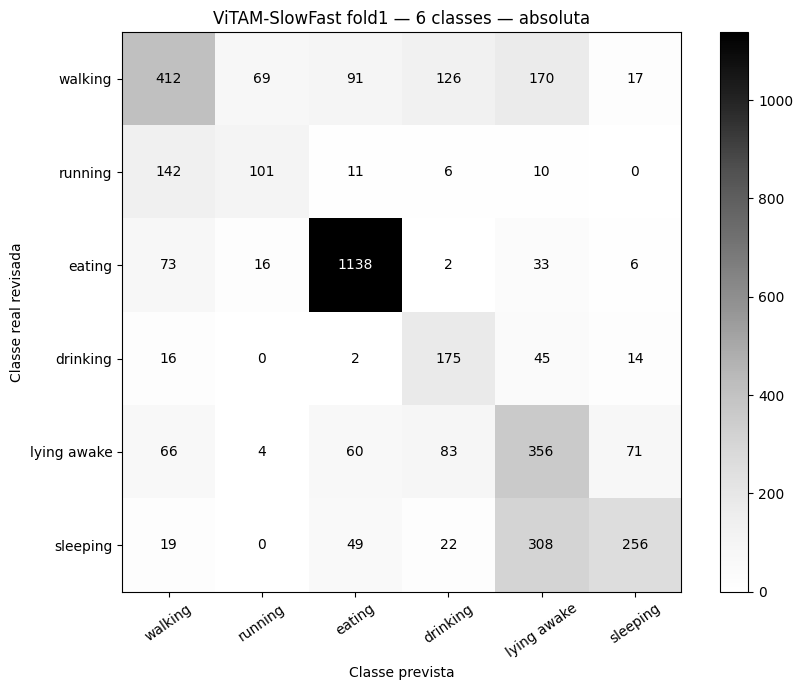

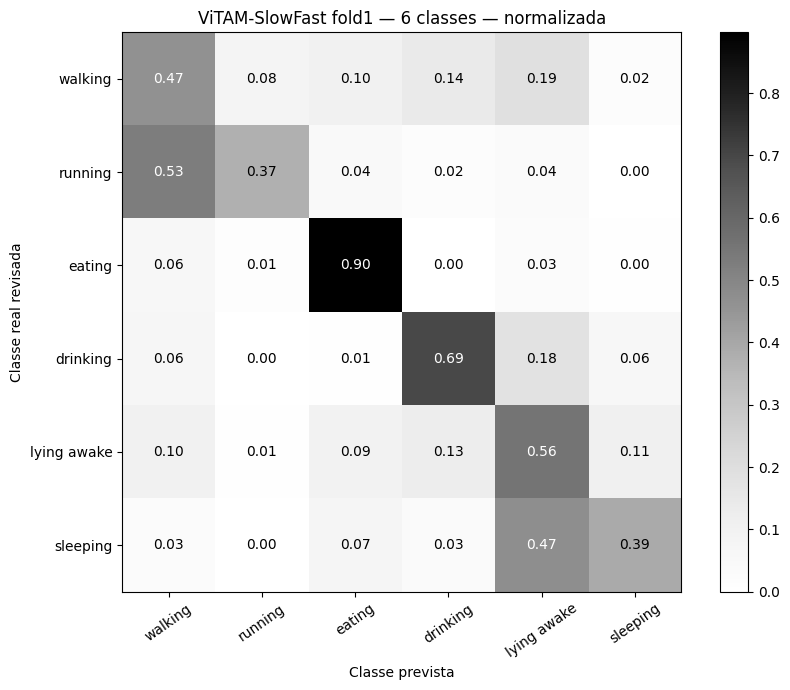


6c convertido para 4c
Accuracy=0.7629 | Macro-Precision=0.7061 | Macro-Recall=0.7462 | Macro-F1=0.7153
              precision    recall  f1-score   support

  locomotion     0.7887    0.6268    0.6985      1155
      eating     0.8423    0.8975    0.8690      1268
    drinking     0.4227    0.6944    0.5255       252
       lying     0.7706    0.7658    0.7682      1294

    accuracy                         0.7629      3969
   macro avg     0.7061    0.7462    0.7153      3969
weighted avg     0.7767    0.7629    0.7647      3969



,classe,precision,recall,f1,suporte
0,locomotion,0.7887,0.6268,0.6985,1155
1,eating,0.8423,0.8975,0.8690,1268
2,drinking,0.4227,0.6944,0.5255,252
3,lying,0.7706,0.7658,0.7682,1294


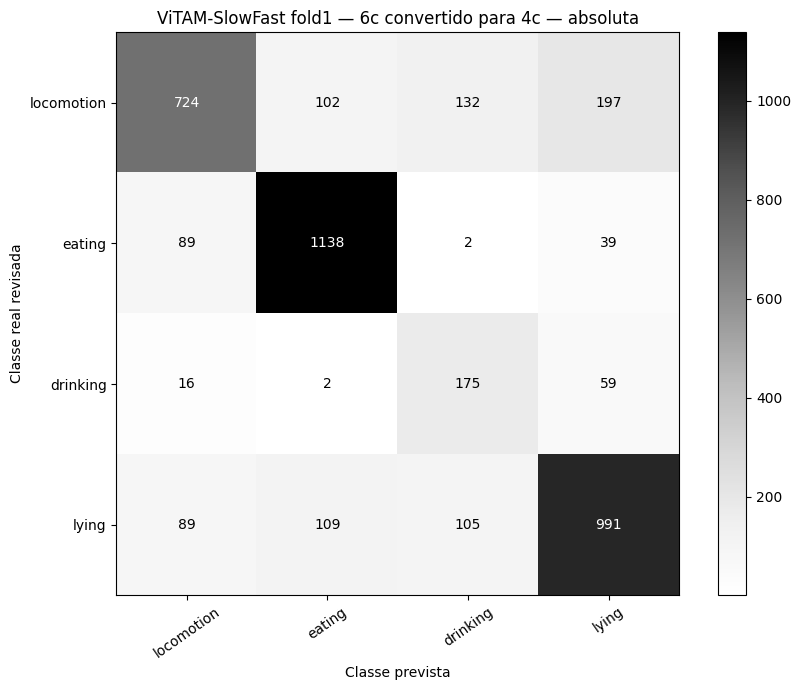

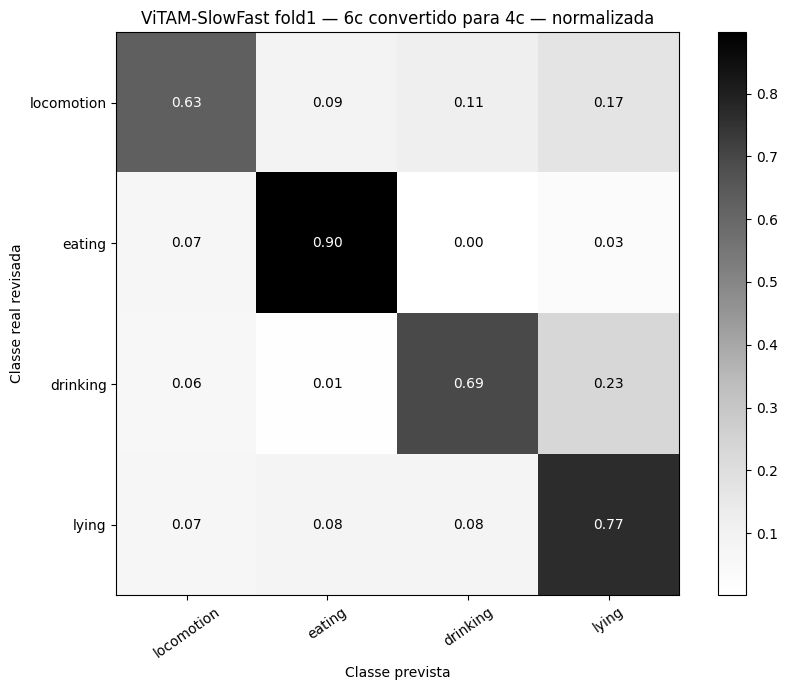

Acertos recuperados: 590

Resultados salvos em: F:\Doutorado\anotador_suinos\datasets_avaliacao\rgb_unificados3_20261110\avaliacao_ViTAM_SlowFast_6c_fold1


In [36]:

# ================================================================
# MÉTRICAS — 6C E 6C -> 4C, MATRIZES E CSVs
# ================================================================
SAIDA.mkdir(parents=True, exist_ok=True)

def avaliar(nome, yt, yp, classes):
    labels=np.arange(len(classes))
    p,r,f,s=precision_recall_fscore_support(yt, yp, labels=labels, zero_division=0)
    acc=accuracy_score(yt,yp)
    print("\n"+"="*70)
    print(nome)
    print("="*70)
    print(f"Accuracy={acc:.4f} | Macro-Precision={p.mean():.4f} | "
          f"Macro-Recall={r.mean():.4f} | Macro-F1={f.mean():.4f}")
    print(classification_report(yt, yp,labels=labels,target_names=classes,digits=4,zero_division=0))
    rel=pd.DataFrame({"classe":classes,"precision":p,"recall":r,"f1":f,"suporte":s})
    display(rel.round(4))
    prefixo='6classes' if len(classes)==6 else '6c_agrupado_4c'
    rel.to_csv(SAIDA/f"metricas_por_classe_{prefixo}.csv",index=False,encoding="utf-8-sig")
    cm=confusion_matrix(yt,yp,labels=labels)
    cm_norm=confusion_matrix(yt,yp,labels=labels,normalize='true')
    for subtipo, matriz, fmt in [('absoluta',cm,'d'),('normalizada',cm_norm,'.2f')]:
        pd.DataFrame(matriz,index=classes,columns=classes).to_csv(
            SAIDA/f"matriz_{prefixo}_{subtipo}.csv",encoding="utf-8-sig")
        fig,ax=plt.subplots(figsize=(9,7))
        ConfusionMatrixDisplay(confusion_matrix=matriz,display_labels=classes).plot(
            ax=ax,cmap='Greys',values_format=fmt,xticks_rotation=35,colorbar=True)
        ax.set_title(f"ViTAM-SlowFast fold1 — {nome} — {subtipo}")
        ax.set_xlabel('Classe prevista');ax.set_ylabel('Classe real revisada')
        fig.tight_layout()
        fig.savefig(SAIDA/f"matriz_{prefixo}_{subtipo}.png",dpi=300,bbox_inches='tight')
        plt.show();plt.close(fig)
    return {"avaliacao":nome,"n":len(yt),"accuracy":float(acc),
            "macro_precision":float(p.mean()),"macro_recall":float(r.mean()),
            "macro_f1":float(f.mean())}

r6=avaliar("6 classes", y_true,y_pred,CLASSES_6C)
y4_true=MAPA_IDX_4C[y_true]
y4_pred=MAPA_IDX_4C[y_pred]
r4=avaliar("6c convertido para 4c",y4_true,y4_pred,CLASSES_4C)
assert r4['accuracy']>=r6['accuracy']-1e-12
print("Acertos recuperados:",int(((y_true!=y_pred)&(y4_true==y4_pred)).sum()))
pred=df.copy()
pred['classe_real']=df['label_name']
pred['classe_prevista']=[CLASSES_6C[i] for i in y_pred]
pred['classe_real_4c']=[CLASSES_4C[i] for i in y4_true]
pred['classe_prevista_4c']=[CLASSES_4C[i] for i in y4_pred]
pred['correto_6c']=y_true==y_pred
pred['correto_4c']=y4_true==y4_pred
pred['confianca']=probs.max(axis=1)
for i,nome in enumerate(CLASSES_6C):
    pred['prob_'+nome.replace(' ','_')]=probs[:,i]
pred.to_csv(SAIDA/'predicoes_por_animal.csv',index=False,encoding='utf-8-sig')
pd.DataFrame([r6,r4]).to_csv(SAIDA/'metricas_globais.csv',index=False,encoding='utf-8-sig')
with open(SAIDA/'auditoria_execucao.json','w',encoding='utf-8') as f:
    json.dump({"checkpoint":str(CHECKPOINT),"sha256":hash_arquivo(CHECKPOINT),
               "dataset":str(CSV),"n":len(df),"fold":1,"modelo":"ViTAMSlowFastAdapted",
               "img_size":224,"src_frames":15,"fast_frames":32,"slow_frames":8},f,indent=2,ensure_ascii=False)
print("\nResultados salvos em:",SAIDA)


### Step 34 — ViTAM-SlowFast compact four-class checkpoint diagnostic

**Purpose.** Inspects the 4c checkpoint state dictionary, tensor shapes and major parameter names to verify the compact architecture before evaluation.

**Inputs and dependencies.** Four-class ViTAM fold3 checkpoint.

**Expected outputs.** A printed inventory of tensor keys and dimensions, including the final four-class classifier.

**Reproducibility and interpretation.** Diagnostic only. It prints up to 82 tensors and does not change the checkpoint or dataset.



In [38]:

from pathlib import Path
import torch

CHECKPOINT = Path(
    r"F:\Doutorado\anotador_suinos"
    r"\modelos\melhores_modelos"
    r"\ViTAM_SlowFast_4classes"
    r"\vitam_slowfast_4classes_fold3.pt"
)

if not CHECKPOINT.is_file():
    raise FileNotFoundError(CHECKPOINT)

ckpt = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

print("=" * 75)
print("DIAGNÓSTICO ViTAM-SLOWFAST — 4 CLASSES")
print("=" * 75)

print("Arquivo:", CHECKPOINT)
print("Tamanho MB:", round(
    CHECKPOINT.stat().st_size / 1048576, 2
))

print("\nTipo:", type(ckpt).__name__)

if not isinstance(ckpt, dict):
    raise TypeError("Formato inesperado do checkpoint")

print("\nChaves principais:")
print(list(ckpt.keys()))

for chave in [
    "epoch", "fold", "num_classes", "num_class",
    "best_f1", "best_val_f1", "model_name",
    "config", "args"
]:
    if chave in ckpt:
        print(f"{chave}: {ckpt[chave]}")

estado = None

for chave in [
    "model_state_dict",
    "state_dict",
    "model",
    "model_state"
]:
    if chave in ckpt and isinstance(ckpt[chave], dict):
        estado = ckpt[chave]
        print("\nPesos encontrados em:", chave)
        break

if estado is None:
    if all(isinstance(v, torch.Tensor) for v in ckpt.values()):
        estado = ckpt
        print("\nPesos armazenados diretamente")
    else:
        raise ValueError("State_dict não identificado")

print("\nTotal de tensores:", len(estado))

print("\nPARÂMETROS DO MODELO:")
for nome, tensor in estado.items():
    if isinstance(tensor, torch.Tensor):
        print(f"{nome:70} {tuple(tensor.shape)}")

print("\nDIAGNÓSTICO CONCLUÍDO")


DIAGNÓSTICO ViTAM-SLOWFAST — 4 CLASSES
Arquivo: F:\Doutorado\anotador_suinos\modelos\melhores_modelos\ViTAM_SlowFast_4classes\vitam_slowfast_4classes_fold3.pt
Tamanho MB: 4.82

Tipo: OrderedDict

Chaves principais:
['slow_path.patch_embed.proj.weight', 'slow_path.patch_embed.proj.bias', 'slow_path.encoder.layers.0.self_attn.in_proj_weight', 'slow_path.encoder.layers.0.self_attn.in_proj_bias', 'slow_path.encoder.layers.0.self_attn.out_proj.weight', 'slow_path.encoder.layers.0.self_attn.out_proj.bias', 'slow_path.encoder.layers.0.linear1.weight', 'slow_path.encoder.layers.0.linear1.bias', 'slow_path.encoder.layers.0.linear2.weight', 'slow_path.encoder.layers.0.linear2.bias', 'slow_path.encoder.layers.0.norm1.weight', 'slow_path.encoder.layers.0.norm1.bias', 'slow_path.encoder.layers.0.norm2.weight', 'slow_path.encoder.layers.0.norm2.bias', 'slow_path.encoder.layers.1.self_attn.in_proj_weight', 'slow_path.encoder.layers.1.self_attn.in_proj_bias', 'slow_path.encoder.layers.1.self_attn.out_

### Step 35 — ViTAM-SlowFast directly trained four-class independent evaluation

**Purpose.** Defines the original compact architecture (128-dimensional Transformer, three CNN/TAM blocks), reads 160×160 crops, checks strict loading and evaluates the four-class classifier.

**Inputs and dependencies.** The four-class RGB CSV, the original 4c class map and the preselected fold3 state dictionary.

**Expected outputs.** Global Macro-F1, accuracy, class-level report, grayscale confusion matrices and CSV files with individual predictions.

**Reproducibility and interpretation.** This is a separately trained four-class model; preserve the 160×160 preprocessing and compact architecture rather than reusing six-class settings.



Dispositivo: cuda
Checkpoint: F:\Doutorado\anotador_suinos\modelos\melhores_modelos\ViTAM_SlowFast_4classes\vitam_slowfast_4classes_fold3.pt
Dataset: F:\Doutorado\anotador_suinos\datasets_avaliacao\rgb_unificados3_20261110\teste_rgb_4classes.csv

Checkpoint fold3 carregado com strict=True.
Número de tensores: 82

Iniciando avaliação...


C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\torch\nn\modules\transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Processadas 3969/3969
Inferência concluída.

ViTAM-SLOWFAST 4 CLASSES — FOLD3 — TESTE REVISADO
Accuracy:        0.7208
Macro-Precision: 0.7031
Macro-Recall:    0.7567
Macro-F1:        0.6741

RELATÓRIO COMPLETO
              precision    recall  f1-score   support

  locomotion     0.9011    0.5758    0.7026      1155
      eating     0.7996    0.9409    0.8645      1268
    drinking     0.2868    0.9127    0.4364       252
       lying     0.8250    0.5974    0.6930      1294

    accuracy                         0.7208      3969
   macro avg     0.7031    0.7567    0.6741      3969
weighted avg     0.8048    0.7208    0.7343      3969



,classe,precision,recall,f1,suporte
0,locomotion,0.9011,0.5758,0.7026,1155
1,eating,0.7996,0.9409,0.8645,1268
2,drinking,0.2868,0.9127,0.4364,252
3,lying,0.8250,0.5974,0.6930,1294


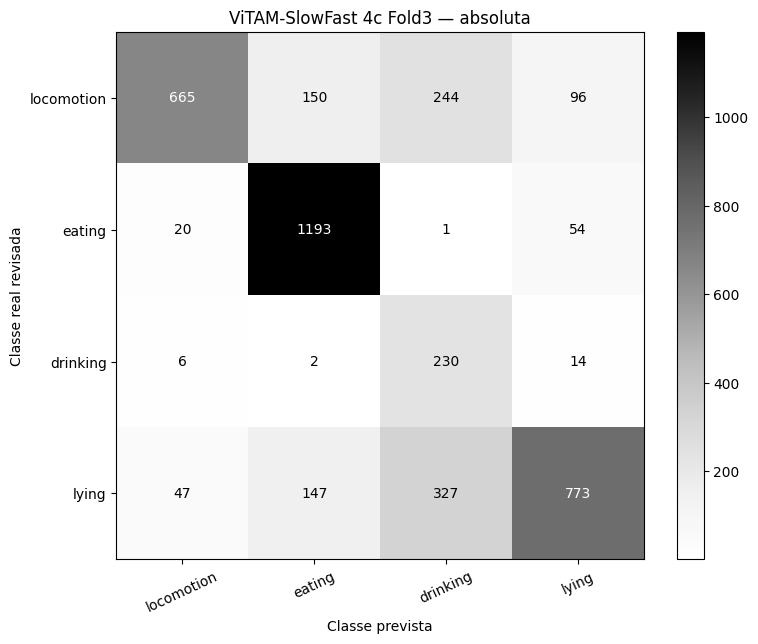

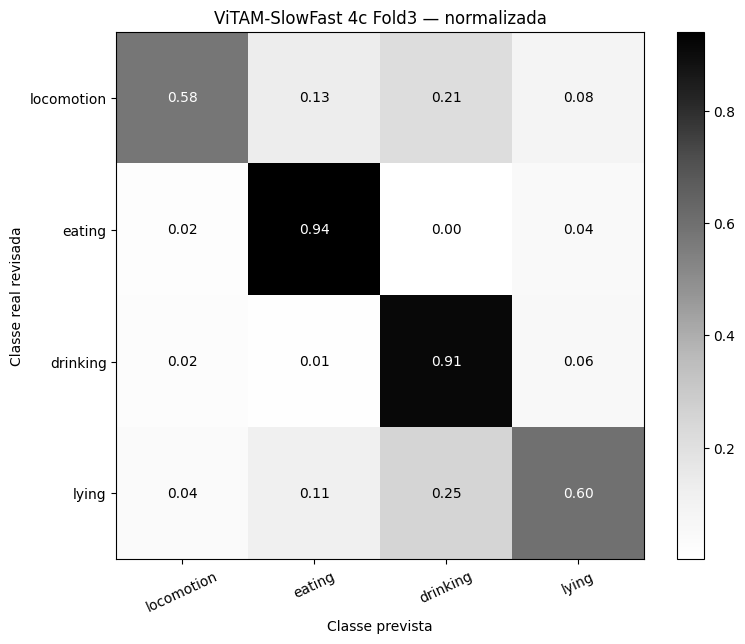


AVALIAÇÃO CONCLUÍDA


,modelo,fold,checkpoint,n,accuracy,macro_precision,macro_recall,macro_f1
0,ViTAM-SlowFast 4c,3,F:\Doutorado\anotador_suinos\modelos\melhores_...,3969,0.7208,0.7031,0.7567,0.6741



Resultados salvos em:
F:\Doutorado\anotador_suinos\datasets_avaliacao\rgb_unificados3_20261110\avaliacao_ViTAM_SlowFast_4c_fold3


In [40]:

# ================================================================
# ViTAM-SLOWFAST 4 CLASSES — FOLD3
# TESTE INDEPENDENTE NO DATASET REVISADO
#
# 414 clipes | 3969 instâncias | RGB
# Arquitetura original compacta do treinamento 4c
# Entrada: slow (8 frames), fast (32 frames), 160x160
# Apenas inferência. Não modifica os pesos.
# ================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ================================================================
# 1. CAMINHOS E CONFIGURAÇÕES
# ================================================================

BASE = Path(r"F:\Doutorado\anotador_suinos")

DATASET = (
    BASE / "datasets_avaliacao" /
    "rgb_unificados3_20261110"
)

CSV_TESTE = DATASET / "teste_rgb_4classes.csv"

CHECKPOINT = (
    BASE / "modelos" / "melhores_modelos" /
    "ViTAM_SlowFast_4classes" /
    "vitam_slowfast_4classes_fold3.pt"
)

MAPA_ORIGINAL = Path(
    r"F:\slowfast_dataset_degcn_aligned_5300xml"
    r"\merged_4classes\labels_map_4cls.json"
)

SAIDA = DATASET / "avaliacao_ViTAM_SlowFast_4c_fold3"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASSES_ORIGINAIS = [
    "deslocando", "eating", "drinking", "deitado"
]

CLASSES_EXIBICAO = [
    "locomotion", "eating", "drinking", "lying"
]

IMG_SIZE = 160
SRC_FRAMES = 15
FAST_FRAMES = 32
SLOW_FRAMES = 8
BATCH_SIZE = 1

for caminho in (CSV_TESTE, CHECKPOINT, MAPA_ORIGINAL):
    if not caminho.is_file():
        raise FileNotFoundError(caminho)

with MAPA_ORIGINAL.open("r", encoding="utf-8") as f:
    mapa = json.load(f)

if mapa["class_to_idx"] != {
    nome: i for i, nome in enumerate(CLASSES_ORIGINAIS)
}:
    raise ValueError("Ordem de classes original incompatível")

print("Dispositivo:", DEVICE)
print("Checkpoint:", CHECKPOINT)
print("Dataset:", CSV_TESTE)

# ================================================================
# 2. DATASET — IGUAL AO TREINAMENTO ORIGINAL
# ================================================================

class PigSlowFastDataset(Dataset):

    def __init__(self, csv_path):

        self.df = pd.read_csv(csv_path).reset_index(drop=True)

        self.fast_idx = np.linspace(
            0, SRC_FRAMES - 1, FAST_FRAMES
        ).round().astype(int)

        self.slow_idx = np.linspace(
            0, FAST_FRAMES - 1, SLOW_FRAMES
        ).round().astype(int)

        if len(self.df) != 3969:
            raise ValueError(
                f"Esperadas 3969 instâncias, "
                f"encontradas {len(self.df)}"
            )

        esperado = {
            nome: i for i, nome
            in enumerate(CLASSES_ORIGINAIS)
        }

        for nome, indice in esperado.items():
            linhas = self.df["label_name"] == nome

            if not (
                self.df.loc[linhas, "label_idx"] == indice
            ).all():
                raise ValueError(
                    f"Índice de classe incorreto: {nome}"
                )

        if self.df.duplicated(
            ["arquivo", "track_id"]
        ).any():
            raise ValueError("Instâncias duplicadas")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
        pasta = Path(row["clip_dir"])

        frames = []

        for t in range(SRC_FRAMES):

            caminho = pasta / f"img_{t:03d}.jpg"

            img = cv2.imread(str(caminho))

            if img is None:
                raise FileNotFoundError(caminho)

            img = cv2.cvtColor(
                img, cv2.COLOR_BGR2RGB
            )

            img = cv2.resize(
                img,
                (IMG_SIZE, IMG_SIZE),
                interpolation=cv2.INTER_LINEAR
            )

            img = img.astype(np.float32) / 255.0

            # Mesma normalização do treinamento
            img = (img - 0.45) / 0.225

            img = np.transpose(img, (2, 0, 1))
            frames.append(img)

        src = np.stack(frames, axis=0)

        fast = src[self.fast_idx]
        fast = np.transpose(fast, (1, 0, 2, 3))
        slow = fast[:, self.slow_idx, :, :]

        return (
            torch.from_numpy(slow.copy()),
            torch.from_numpy(fast.copy()),
            int(row["label_idx"]),
            idx
        )

# ================================================================
# 3. ARQUITETURA ORIGINAL ViTAM-SLOWFAST 4C
# ================================================================

class TemporalAdaptiveModule(nn.Module):

    def __init__(self, channels, reduction=4):
        super().__init__()

        hidden = max(channels // reduction, 8)

        self.fc1 = nn.Linear(channels, hidden)
        self.fc2 = nn.Linear(hidden, channels)
        self.conv1 = nn.Conv1d(
            channels, channels, kernel_size=3, padding=1
        )

    def forward(self, x):

        xs = x.mean(dim=[3, 4])

        local_att = torch.sigmoid(
            self.conv1(xs)
        ).unsqueeze(-1).unsqueeze(-1)

        xg = xs.mean(dim=2)
        g = F.relu(self.fc1(xg))
        g = torch.sigmoid(self.fc2(g))
        g = g.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1)

        return x * local_att * g


class FastPathway(nn.Module):

    def __init__(
        self, in_channels=3,
        base_channels=24, out_dim=128
    ):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(
                in_channels, base_channels,
                kernel_size=(3, 7, 7),
                stride=(1, 2, 2),
                padding=(1, 3, 3)
            ),
            nn.BatchNorm3d(base_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(
                kernel_size=(1, 3, 3),
                stride=(1, 2, 2),
                padding=(0, 1, 1)
            )
        )

        self.block1 = nn.Sequential(
            nn.Conv3d(
                base_channels, 48,
                kernel_size=3, padding=1
            ),
            nn.BatchNorm3d(48),
            nn.ReLU(inplace=True)
        )
        self.tam1 = TemporalAdaptiveModule(48)

        self.block2 = nn.Sequential(
            nn.Conv3d(
                48, 96, kernel_size=3,
                stride=(1, 2, 2), padding=1
            ),
            nn.BatchNorm3d(96),
            nn.ReLU(inplace=True)
        )
        self.tam2 = TemporalAdaptiveModule(96)

        self.block3 = nn.Sequential(
            nn.Conv3d(
                96, out_dim, kernel_size=3,
                stride=(1, 2, 2), padding=1
            ),
            nn.BatchNorm3d(out_dim),
            nn.ReLU(inplace=True)
        )
        self.tam3 = TemporalAdaptiveModule(out_dim)

        self.pool = nn.AdaptiveAvgPool3d((1, 1, 1))

    def forward(self, x):

        x = self.stem(x)
        x = self.tam1(self.block1(x))
        x = self.tam2(self.block2(x))
        x = self.tam3(self.block3(x))

        feat_map = x
        feat = self.pool(x).flatten(1)

        return feat, feat_map


class PatchEmbed3D(nn.Module):

    def __init__(
        self, in_channels=3, embed_dim=128,
        patch_size=(2, 16, 16)
    ):
        super().__init__()

        self.proj = nn.Conv3d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):

        x = self.proj(x)
        b, e, t, h, w = x.shape

        return (
            x.flatten(2).transpose(1, 2),
            (t, h, w)
        )


class SlowPathwayViT(nn.Module):

    def __init__(
        self, in_channels=3, embed_dim=128,
        depth=2, num_heads=4, mlp_ratio=4.0
    ):
        super().__init__()

        self.patch_embed = PatchEmbed3D(
            in_channels, embed_dim,
            patch_size=(2, 16, 16)
        )

        camada = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            camada, num_layers=depth
        )

        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):

        tokens, shape_3d = self.patch_embed(x)
        tokens = self.encoder(tokens)
        tokens = self.norm(tokens)

        return tokens.mean(dim=1), tokens, shape_3d


class LateralFusion(nn.Module):

    def __init__(
        self, fast_dim=128,
        slow_dim=128, out_dim=128
    ):
        super().__init__()

        self.fast_proj = nn.Linear(
            fast_dim, out_dim
        )

        self.slow_proj = nn.Linear(
            slow_dim, out_dim
        )

    def forward(self, fast_feat, slow_feat):

        f = self.fast_proj(fast_feat)
        s = self.slow_proj(slow_feat)

        return torch.cat([s, f], dim=1)


class ViTAMSlowFastAdapted(nn.Module):

    def __init__(
        self, num_classes=4,
        slow_dim=128, fast_dim=128
    ):
        super().__init__()

        self.slow_path = SlowPathwayViT(
            in_channels=3,
            embed_dim=slow_dim,
            depth=2,
            num_heads=4,
            mlp_ratio=4.0
        )

        self.fast_path = FastPathway(
            in_channels=3,
            base_channels=24,
            out_dim=fast_dim
        )

        self.fusion = LateralFusion(
            fast_dim=fast_dim,
            slow_dim=slow_dim,
            out_dim=128
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        slow_x, fast_x = x

        slow_feat, _, _ = self.slow_path(slow_x)
        fast_feat, _ = self.fast_path(fast_x)

        fused = self.fusion(fast_feat, slow_feat)

        return self.classifier(fused)

# ================================================================
# 4. CARREGAR CHECKPOINT FOLD3
# ================================================================

modelo = ViTAMSlowFastAdapted(
    num_classes=4,
    slow_dim=128,
    fast_dim=128
)

estado = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

# Checkpoint confirmado como OrderedDict/state_dict direto
modelo.load_state_dict(
    estado,
    strict=True
)

modelo = modelo.to(DEVICE).eval()

print("\nCheckpoint fold3 carregado com strict=True.")
print("Número de tensores:", len(estado))

# ================================================================
# 5. DATASET E INFERÊNCIA
# ================================================================

dataset = PigSlowFastDataset(CSV_TESTE)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

y_true = []
y_pred = []
probs_todas = []
indices = []

print("\nIniciando avaliação...")

with torch.inference_mode():

    for i, (slow, fast, y, idx) in enumerate(loader):

        slow = slow.to(DEVICE, non_blocking=True)
        fast = fast.to(DEVICE, non_blocking=True)

        logits = modelo([slow, fast])

        if tuple(logits.shape) != (len(y), 4):
            raise ValueError(
                f"Saída incompatível: {tuple(logits.shape)}"
            )

        probs = torch.softmax(
            logits, dim=1
        ).cpu().numpy()

        y_true.extend(y.numpy().tolist())
        y_pred.extend(probs.argmax(axis=1).tolist())
        probs_todas.append(probs)
        indices.extend(idx.numpy().tolist())

        if (i + 1) % 250 == 0 or i + 1 == len(loader):
            print(
                f"Processadas {len(y_true)}/{len(dataset)}",
                end="\r"
            )

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
probs = np.concatenate(probs_todas, axis=0)

print("\nInferência concluída.")

# Garantir que os resultados permaneçam na ordem do CSV
if not np.array_equal(
    np.asarray(indices), np.arange(len(dataset))
):
    raise AssertionError("Ordem das instâncias alterada")

# ================================================================
# 6. MÉTRICAS GLOBAIS E POR CLASSE
# ================================================================

acc = accuracy_score(y_true, y_pred)

p, r, f1, suporte = precision_recall_fscore_support(
    y_true, y_pred,
    labels=np.arange(4),
    zero_division=0
)

macro_p = float(np.mean(p))
macro_r = float(np.mean(r))
macro_f1 = float(np.mean(f1))

print("\n" + "=" * 72)
print("ViTAM-SLOWFAST 4 CLASSES — FOLD3 — TESTE REVISADO")
print("=" * 72)

print(f"Accuracy:        {acc:.4f}")
print(f"Macro-Precision: {macro_p:.4f}")
print(f"Macro-Recall:    {macro_r:.4f}")
print(f"Macro-F1:        {macro_f1:.4f}")

print("\nRELATÓRIO COMPLETO")

print(classification_report(
    y_true, y_pred,
    labels=np.arange(4),
    target_names=CLASSES_EXIBICAO,
    digits=4,
    zero_division=0
))

relatorio = pd.DataFrame({
    "classe": CLASSES_EXIBICAO,
    "precision": p,
    "recall": r,
    "f1": f1,
    "suporte": suporte
})

display(relatorio.round(4))

# ================================================================
# 7. MATRIZES DE CONFUSÃO — ESCALA DE CINZA
# ================================================================

SAIDA.mkdir(parents=True, exist_ok=True)

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(4)
)

cm_norm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(4),
    normalize="true"
)

for tipo, matriz, formato in (
    ("absoluta", cm, "d"),
    ("normalizada", cm_norm, ".2f")
):

    fig, ax = plt.subplots(figsize=(8, 6.5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CLASSES_EXIBICAO
    )

    disp.plot(
        ax=ax,
        cmap="Greys",
        values_format=formato,
        xticks_rotation=25,
        colorbar=True
    )

    ax.set_title(
        f"ViTAM-SlowFast 4c Fold3 — {tipo}"
    )
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real revisada")

    fig.tight_layout()

    fig.savefig(
        SAIDA / f"matriz_confusao_{tipo}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    pd.DataFrame(
        matriz,
        index=CLASSES_EXIBICAO,
        columns=CLASSES_EXIBICAO
    ).to_csv(
        SAIDA / f"matriz_confusao_{tipo}.csv",
        encoding="utf-8-sig"
    )

# ================================================================
# 8. SALVAR PREDIÇÕES INDIVIDUAIS
# ================================================================

df_pred = dataset.df.copy()

df_pred["classe_real"] = [
    CLASSES_EXIBICAO[i] for i in y_true
]

df_pred["classe_prevista"] = [
    CLASSES_EXIBICAO[i] for i in y_pred
]

df_pred["correto"] = y_true == y_pred
df_pred["confianca"] = probs.max(axis=1)

for j, nome in enumerate(CLASSES_EXIBICAO):
    df_pred[f"prob_{nome}"] = probs[:, j]

df_pred.to_csv(
    SAIDA / "predicoes_por_animal.csv",
    index=False,
    encoding="utf-8-sig"
)

relatorio.to_csv(
    SAIDA / "metricas_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo = pd.DataFrame([{
    "modelo": "ViTAM-SlowFast 4c",
    "fold": 3,
    "checkpoint": str(CHECKPOINT),
    "n": len(y_true),
    "accuracy": acc,
    "macro_precision": macro_p,
    "macro_recall": macro_r,
    "macro_f1": macro_f1
}])

resumo.to_csv(
    SAIDA / "metricas_globais.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 72)
print("AVALIAÇÃO CONCLUÍDA")
print("=" * 72)

display(resumo.round(4))

print("\nResultados salvos em:")
print(SAIDA)


In [1]:

# ================================================================
# BACKUP DOS 8 MODELOS DA AVALIAÇÃO INDEPENDENTE
# Destino: Área de Trabalho do Windows
#
# - 4 arquiteturas, versões 6c e 4c
# - Preserva os checkpoints originais
# - Não retreina nem seleciona novos folds
# - Verifica a integridade SHA-256 das cópias
# - Registra arquivos ausentes ou inacessíveis
# ================================================================

from pathlib import Path
import os
import hashlib
import json
import pandas as pd
import winreg

# ================================================================
# 1. LOCALIZAR A ÁREA DE TRABALHO REAL DO WINDOWS
# ================================================================

try:
    with winreg.OpenKey(
        winreg.HKEY_CURRENT_USER,
        r"Software\Microsoft\Windows\CurrentVersion"
        r"\Explorer\User Shell Folders"
    ) as chave:
        caminho_desktop, _ = winreg.QueryValueEx(
            chave, "Desktop"
        )

    DESKTOP = Path(os.path.expandvars(caminho_desktop))

except OSError:
    DESKTOP = Path.home() / "Desktop"

if not DESKTOP.is_dir():
    raise FileNotFoundError(
        f"Área de Trabalho não encontrada: {DESKTOP}"
    )

if DESKTOP.drive.upper() == "F:":
    raise RuntimeError(
        "A Área de Trabalho está na unidade F:. "
        "Escolha outro disco físico para o backup."
    )

DESTINO = DESKTOP / "modelos_avaliacao_independente"

print("Área de Trabalho:", DESKTOP)
print("Destino do backup:", DESTINO)

# ================================================================
# 2. CAMINHOS ORIGINAIS
# ================================================================

BASE = Path(r"F:\Doutorado\anotador_suinos")
M = BASE / "modelos"
BEST = M / "melhores_modelos"

RGB = Path(
    r"F:\slowfast_dataset_degcn_aligned_5300xml"
)

MODELOS = [
    {
        "modelo": "DeGCN",
        "classes": 6,
        "fold": 2,
        "origens": [
            BEST / "DeGCN_6classes" / "degcn_fold2.pth",
            M / "degcn" / "degcn_yolo_fold02.pth"
        ]
    },
    {
        "modelo": "DeGCN",
        "classes": 4,
        "fold": 2,
        "origens": [
            BEST / "DeGCN_4classes" / "degcn_fold2.pth",
            Path(
                r"F:\Doutorado\experimentos\degcn"
                r"\experiments\degcn_yolo_T15_4cls_5fold"
                r"\fold02.pth"
            )
        ]
    },
    {
        "modelo": "KP-TCN",
        "classes": 6,
        "fold": 1,
        "origens": [
            BEST / "KPTCN_6classes" / "tcn_best_fold1.pt",
            M / "kptcn" / "fold1" / "tcn_best.pt"
        ]
    },
    {
        "modelo": "KP-TCN",
        "classes": 4,
        "fold": 2,
        # Pasta contendo o checkpoint previamente selecionado
        "pasta_unica": BEST / "KPTCN_4classes"
    },
    {
        "modelo": "SlowFast",
        "classes": 6,
        "fold": 3,
        "origens": [
            BEST / "SlowFast_6classes" /
            "slowfast_6classes_fold3_artigo.pt",
            RGB / "slowfast_runs_5fold" /
            "fold3" / "best.pt"
        ]
    },
    {
        "modelo": "SlowFast",
        "classes": 4,
        "fold": 3,
        "origens": [
            BEST / "SlowFast_4classes" /
            "slowfast_4classes_fold3.pt",
            RGB / "merged_4classes" /
            "slowfast_runs_4cls_5fold" /
            "fold3" / "best.pt"
        ]
    },
    {
        "modelo": "ViTAM-SlowFast",
        "classes": 6,
        "fold": 1,
        "origens": [
            BEST / "ViTAM_SlowFast_6classes" /
            "vitam_slowfast_6classes_fold1.pt",
            RGB / "vitam_slowfast_runs_6cls_5fold" /
            "fold1" / "best.pt"
        ]
    },
    {
        "modelo": "ViTAM-SlowFast",
        "classes": 4,
        "fold": 3,
        "origens": [
            BEST / "ViTAM_SlowFast_4classes" /
            "vitam_slowfast_4classes_fold3.pt",
            RGB / "merged_4classes" /
            "vitam_slowfast_runs_4cls_5fold" /
            "fold3" / "best.pt"
        ]
    }
]

# ================================================================
# 3. IDENTIFICAR OS CHECKPOINTS SEM ALTERÁ-LOS
# ================================================================

def arquivo_acessivel(caminho):
    try:
        return caminho.is_file()
    except OSError:
        return False

def encontrar_origem(item):

    if "pasta_unica" in item:

        pasta = item["pasta_unica"]

        try:
            arquivos = sorted(
                p for p in pasta.iterdir()
                if p.is_file()
                and p.suffix.lower() in {".pt", ".pth"}
            )
        except OSError:
            return None

        # Só aceitar automaticamente uma seleção inequívoca.
        if len(arquivos) == 1:
            return arquivos[0]

        fold = item["fold"]
        correspondentes = [
            p for p in arquivos
            if f"fold{fold}" in p.name.lower()
            or f"fold_{fold}" in p.name.lower()
        ]

        if len(correspondentes) == 1:
            return correspondentes[0]

        print(
            "[ATENÇÃO] KP-TCN 4c: "
            "checkpoint não identificado univocamente.",
            arquivos
        )
        return None

    for caminho in item["origens"]:
        if arquivo_acessivel(caminho):
            return caminho

    return None

# ================================================================
# 4. CÓPIA COM VERIFICAÇÃO SHA-256
# ================================================================

def copiar_verificado(origem, destino):

    if destino.exists():
        raise FileExistsError(
            f"Arquivo já existe e não será sobrescrito: {destino}"
        )

    temporario = destino.with_name(
        destino.name + ".part"
    )

    if temporario.exists():
        raise FileExistsError(
            f"Existe uma cópia parcial anterior: {temporario}"
        )

    h_origem = hashlib.sha256()

    try:
        with origem.open("rb") as entrada, \
             temporario.open("xb") as saida:

            while True:
                bloco = entrada.read(1024 * 1024)

                if not bloco:
                    break

                h_origem.update(bloco)
                saida.write(bloco)

        # Verificar lendo somente a cópia
        h_copia = hashlib.sha256()

        with temporario.open("rb") as f:
            for bloco in iter(
                lambda: f.read(1024 * 1024), b""
            ):
                h_copia.update(bloco)

        if h_origem.digest() != h_copia.digest():
            raise RuntimeError(
                "Falha de integridade SHA-256"
            )

        temporario.rename(destino)

        return h_copia.hexdigest()

    except Exception:
        if temporario.exists():
            temporario.unlink()
        raise

registros = []
DESTINO.mkdir(parents=True, exist_ok=True)

print("\n" + "=" * 72)
print("COPIANDO CHECKPOINTS PARA A ÁREA DE TRABALHO")
print("=" * 72)

for item in MODELOS:

    nome = item["modelo"]
    classes = item["classes"]
    fold = item["fold"]

    origem = encontrar_origem(item)

    registro = {
        "modelo": nome,
        "classes": classes,
        "fold": fold,
        "origem": str(origem) if origem else "",
        "destino": "",
        "tamanho_MB": None,
        "sha256": "",
        "status": ""
    }

    if origem is None:
        registro["status"] = "NÃO LOCALIZADO / INACESSÍVEL"
        print(f"[AUSENTE] {nome} {classes}c")

    else:
        pasta = DESTINO / nome.replace("-", "_")
        pasta.mkdir(parents=True, exist_ok=True)

        extensao = origem.suffix

        destino = pasta / (
            f"{nome.replace('-', '_')}_"
            f"{classes}c_fold{fold}{extensao}"
        )

        registro["destino"] = str(destino)

        try:
            if destino.exists():
                registro["status"] = (
                    "JÁ EXISTE - NÃO SOBRESCRITO"
                )
                print(f"[JÁ EXISTE] {destino.name}")

            else:
                checksum = copiar_verificado(
                    origem, destino
                )

                registro["sha256"] = checksum
                registro["status"] = "COPIADO E VERIFICADO"

                print(f"[OK] {destino.name}")

            registro["tamanho_MB"] = round(
                destino.stat().st_size / (1024 ** 2), 2
            )

        except (OSError, RuntimeError) as erro:
            registro["status"] = f"ERRO: {erro}"
            print(f"[ERRO] {nome} {classes}c: {erro}")

    registros.append(registro)

# ================================================================
# 5. INVENTÁRIO FINAL
# ================================================================

df = pd.DataFrame(registros)

df.to_csv(
    DESTINO / "inventario_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

with (DESTINO / "inventario_modelos.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(
        registros, f, indent=2, ensure_ascii=False
    )

print("\n" + "=" * 72)
print("RESULTADO DO BACKUP")
print("=" * 72)

display(df[[
    "modelo", "classes", "fold",
    "tamanho_MB", "status"
]])

copiados = sum(
    r["status"] == "COPIADO E VERIFICADO"
    for r in registros
)

print(f"\nNovas cópias verificadas: {copiados}/8")
print("Pasta:", DESTINO)

if any(r["status"] != "COPIADO E VERIFICADO"
       for r in registros):
    print(
        "\nATENÇÃO: confira os itens não copiados "
        "ou já existentes no inventário."
    )
else:
    print("\nBACKUP DOS OITO MODELOS CONCLUÍDO.")


Área de Trabalho: C:\Users\pedro\OneDrive\Área de Trabalho
Destino do backup: C:\Users\pedro\OneDrive\Área de Trabalho\modelos_avaliacao_independente

COPIANDO CHECKPOINTS PARA A ÁREA DE TRABALHO
[OK] DeGCN_6c_fold2.pth
[OK] DeGCN_4c_fold2.pth
[OK] KP_TCN_6c_fold1.pt
[OK] KP_TCN_4c_fold2.pt
[OK] SlowFast_6c_fold3.pt
[OK] SlowFast_4c_fold3.pt
[OK] ViTAM_SlowFast_6c_fold1.pt
[OK] ViTAM_SlowFast_4c_fold3.pt

RESULTADO DO BACKUP


,modelo,classes,fold,tamanho_MB,status
0,DeGCN,6,2,2.92,COPIADO E VERIFICADO
1,DeGCN,4,2,2.91,COPIADO E VERIFICADO
2,KP-TCN,6,1,0.29,COPIADO E VERIFICADO
3,KP-TCN,4,2,0.29,COPIADO E VERIFICADO
4,SlowFast,6,3,128.85,COPIADO E VERIFICADO
5,SlowFast,4,3,128.83,COPIADO E VERIFICADO
6,ViTAM-SlowFast,6,1,20.24,COPIADO E VERIFICADO
7,ViTAM-SlowFast,4,3,4.82,COPIADO E VERIFICADO



Novas cópias verificadas: 8/8
Pasta: C:\Users\pedro\OneDrive\Área de Trabalho\modelos_avaliacao_independente

BACKUP DOS OITO MODELOS CONCLUÍDO.
